## **Portfolio Opdracht 2: Voorspel Verhuuraantallen**


##### Competitie: Predicting bike rental quantities | Kaggle
##### Teamnaam: Groep 4
##### Teamleden & Kaggle Usernames: 
+ Kaman - [Kaggle Username: KMT250]
+ Alex - [Kaggle Username: Alex Gaiser 2]
+ Pablo - [Kaggle Username: Artheriax]


### **Inleiding**

##### In dit project werken we als junior data scientists bij *CitiBike*. Het doel is om een machine learning model te ontwikkelen dat op basis van historische gegevens over het gebruik van de fietsverhuurservice kan verspellen hoeveel fietsen er per uur zullen worden verhuurd, zodat het bedrijf zijn fietsen efficienter kan verdelen en zodat klanten zo vaak mogelijk een fiets beschikbaar hebben wanneer zij die nodig hebben. 

##### **Opbouw van dit notebook**

+ **1. Data en exploratieve data-analyse (EDA)** - Opdracht 1
+ **2. Data opschonen en voorbereiden**
+ **3. Time series feature engineering** - Opdracht 2 (trend, Fourier, cycli, feestdagen, overige tijdsfeatures)
+ **4. Invloed van de features op de voorspellingen** - ablatietest met time-series cross-validatie
+ **5. Submissions voor de Kaggle-competitie** - per model een submissionbestand
+ **6. Conclusie Opdracht 1 en 2**
+ **7. Modelleren (Opdracht 3)** - zeven modellen met cross-validatie en hyperparameter tuning
+ **8. Bevindingen modelleren (Opdracht 3)** - overzicht, beste model en Kaggle-scores
+ **9. Conclusie en aanbevelingen (Opdracht 4)** - feature-invloed, advies en modelkeuze
+ **10. Experimenteel** - december-proxy, GBDT-ensemble en leaderboard-kalibratie, met eigen conclusie


## 1. **Data en exploratieve data-analyse (EDA)**


### 1.1 **Uitleg van de kolommen**


##### De dataset bevat al numerieke waarden en dummyvariabelen. De kolommen betekenen: 
+ 'cnt' (target kolom): informatie over het aantal stuks dat per uur is verhuurd 
+ date_hour: informatie over de periode van 1-1-2011 t/m 30-11-2012
+ holiday: Vakantiedag of geen vakantiedag 
+ weathersit: Weersituatie - 
1. Helder, licht bewolkt, deels bewolkt
2. Mistig, mistig en licht bewolkt
3. Lichte sneeuw, lichte regen, lichte regen en onweer, zwaar bewolkt, lichte regen en zwaar bewolkt
4. Zware regen, hagel, zware mist, sneeuw 
+ temp: genormaliseerde temperatuur
+ atemp: genormaliseerde gevoelstemperatuur 
+ hum: genormaliseerde luchtvochtigheid 
+ windspeed: genormaliseerde windsnelheid 


In [43]:
# pylint: disable=invalid-name
""" Portfolio Opdracht 2 (Groep 4): tijdreeksfeatures voor de CitiBike-verhuurdata.

De notebook bouwt voort op de EDA uit Opdracht 1. De bestandsnaam ligt vast door de
opdracht en namen als X_train en y_train zijn standaard in ML-notebooks; daarom staat
invalid-name hierboven uit.
"""

# Python libraries importeren

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import STL


In [44]:
def converteer_bool_kolommen(df: pd.DataFrame) -> pd.DataFrame:
    """ Zet bool-kolommen om naar 0/1 (nodig voor sommige sklearn- / XGBoost-versies)."""
    for kolom in df.select_dtypes(include="bool").columns:
        df[kolom] = df[kolom].astype(int)
    return df


class DataLoader:
    """ Laadt de ruwe train- en testdataset in voor de EDA."""

    def __init__(self, train_path: str, test_path: str):
        self.train_path = train_path
        self.test_path = test_path
        # Worden gevuld door load_data(); hier vast initialiseren zodat het objectcontract klopt.
        self.train_df = pd.DataFrame()
        self.test_df = pd.DataFrame()

    def load_data(self) -> tuple[pd.DataFrame, pd.DataFrame]:
        """ Leest beide CSV-bestanden in en converteert booleans naar 0/1."""
        self.train_df = converteer_bool_kolommen(pd.read_csv(self.train_path))
        self.test_df = converteer_bool_kolommen(pd.read_csv(self.test_path))
        return self.train_df, self.test_df

    def convert_datetime(self, df: pd.DataFrame, col: str = "date_hour") -> pd.DataFrame:
        """ Zet een kolom met tijdstempel-strings om in een correct pandas-datetime-object."""
        df = df.copy()
        df[col] = pd.to_datetime(df[col])
        df = df.sort_values(by=col).reset_index(drop=True)
        return df


class TimeFeatureEngineer:  # pylint: disable=too-few-public-methods
    """ Extraheert kalender- en tijdgerelateerde kenmerken uit een datum-tijd-kolom."""

    def __init__(self, datetime_col: str = "date_hour"):
        self.datetime_col = datetime_col

    def extract_calendar_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Extraheert uur, dag van de week, maand, jaar en "is_weekend"."""
        df = df.copy()
        dt = df[self.datetime_col].dt

        df["hour"] = dt.hour
        df["day_of_week"] = dt.day_of_week
        df["month"] = dt.month
        df["year"] = dt.year
        df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
        return df


class EDAAnalyzer:
    """ Voert een gestructureerde verkennende data-analyse uit voor tijdreeksregressie."""

    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col

    def inspect_time_split(self, train_frame: pd.DataFrame, test_frame: pd.DataFrame):
        """ Controleert de datumbereiken en de opsplitsingsstructuur van train- en testset."""
        print("--- TIME SPLIT ---")
        train_min = train_frame[self.datetime_col].min()
        train_max = train_frame[self.datetime_col].max()
        test_min = test_frame[self.datetime_col].min()
        test_max = test_frame[self.datetime_col].max()
        print(f"Train range: {train_min} to {train_max} (n = {len(train_frame)})")
        print(f"Test range:  {test_min} to {test_max} (n = {len(test_frame)})")
        print(f"Aantal testdagen: {(test_max - test_min).days + 1}")
        print()

    def inspect_time_continuity(self, dfs: dict[str, pd.DataFrame]):
        """ Controleert ontbrekende uren, dubbele tijdstippen en de lengte van het grootste gat."""
        print("--- TIME CONTINUITY ---")
        for naam, df in dfs.items():
            stamps = pd.DatetimeIndex(df[self.datetime_col])
            verwacht = pd.date_range(stamps.min(), stamps.max(), freq="h")
            ontbrekend = verwacht.difference(stamps)
            gaten = stamps.to_series().diff().dropna()
            aantal_gaten = int((gaten > pd.Timedelta(hours=1)).sum())
            print(
                f"{naam}: {len(stamps)} rijen, {len(verwacht)} uurwaarden verwacht, "
                f"{len(ontbrekend)} ontbrekende uren, {aantal_gaten} gaten, "
                f"langste gat {gaten.max()}, dubbelen {int(stamps.duplicated().sum())}"
            )
        print()

    def plot_target_distribution(self, df: pd.DataFrame):
        """ Plot de ruwe doelscheefheid tegen de log1p-getransformeerde doelscheefheid."""
        raw_skew = df[self.target_col].skew()
        log_target = np.log1p(df[self.target_col])
        log_skew = log_target.skew()

        _, axes = plt.subplots(1, 2, figsize=(14, 5))

        sns.histplot(df[self.target_col], bins=40, kde=True, ax=axes[0], color="skyblue")
        axes[0].set_title(f"Raw '{self.target_col}' Distribution (Skewness: {raw_skew:.2f})")
        axes[0].set_xlabel("Bike Rentals (cnt)")

        sns.histplot(log_target, bins=40, kde=True, ax=axes[1], color="r")
        axes[1].set_title(f"Log1p('{self.target_col}') Distribution (Skewness: {log_skew:.2f})")
        axes[1].set_xlabel("Log1p(cnt)")

        plt.tight_layout()
        plt.show()

    def plot_key_relationships(self, df: pd.DataFrame):
        """ Brengt patronen per uur in kaart (doordeweeks vs weekend) en de invloed van het weer."""
        _, axes = plt.subplots(1, 2, figsize=(15, 5))

        # Lijngrafiek per uur, uitgesplitst naar weekend vs doordeweekse dagen
        sns.lineplot(
            data=df,
            x="hour",
            y=self.target_col,
            hue="is_weekend",
            estimator="mean",
            errorbar="ci",
            marker="o",
            ax=axes[0],
        )
        axes[0].set_title("Gemiddelde Verhuur per Uur (Weekdag(0) vs Weekend(1))")
        axes[0].set_xticks(range(0, 24))
        axes[0].set_xlabel("Uur van de Dag")
        axes[0].set_ylabel("Gemiddelde Aantal Verhuurtransacties")
        axes[0].grid(True, alpha=0.3)

        # Weersituatie Boxplot
        sns.boxplot(
            data=df,
            x="weathersit",
            y=self.target_col,
            hue="weathersit",
            legend=False,
            palette="Set2",
            ax=axes[1],
        )
        axes[1].set_title("Fietsverhuur onder uiteenlopende weersomstandigheden (weathersit)")
        axes[1].set_xlabel("Weersituatie (1=Helder, 2=Mist, 3=Lichte Regen/Sneeuw, 4=Zwaar)")
        axes[1].set_ylabel("Fietsverhuur (cnt)")

        plt.tight_layout()
        plt.show()

    def plot_correlation_heatmap(self, df: pd.DataFrame):
        """ Plot de correlatiematrix voor numerieke kenmerken."""
        numeric_df = df.select_dtypes(include=[np.number])
        corr_matrix = numeric_df.corr()

        plt.figure(figsize=(11, 8))
        sns.heatmap(
            corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            center=0,
            linewidth=0.5,
        )
        plt.title("Correlatie-heatmap van Numerieke Kenmerken")
        plt.tight_layout()
        plt.show()


class DataPreparer:
    """ Verzorgt anomaliecontroles, een chronologische opsplitsing en "lekvrije" voorverwerking."""

    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col

    def check_anomalies(self, df: pd.DataFrame, name: str = "Train"):
        """ Toont samenvattende statistieken en controleert op sensorafwijkingen.

        Bijvoorbeeld een luchtvochtigheid of windsnelheid van 0.
        """
        print(f"--- ANOMALY & SUMMARY CHECK ({name}) ---")
        display(df.describe().T[["min", "50%", "mean", "max", "std"]])

        zero_hum = (df["hum"] == 0).sum()
        zero_wind = (df["windspeed"] == 0).sum()
        print(f"Rows with hum == 0: {zero_hum}")
        print(f"Rows with windspeed == 0: {zero_wind}\n")

    def clean_data(self, df: pd.DataFrame, drop_atemp: bool = True):
        """ Corrigeert sensorafwijkingen en verwijdert "redundante" kolommen."""
        df = df.copy()

        # Vervang onmogelijke vochtigheid van 0 door NaN en interpoleer vloeiend in de tijd
        if "hum" in df.columns:
            df["hum"] = df["hum"].replace(0, np.nan).interpolate(method="linear").bfill().ffill()

        # Windstilte (windspeed == 0) is een geldige meting en wordt daarom niet aangepast.

        # Verwijder "atemp" indien verzocht, vanwege een correlatie van 0,99 met "temp"
        if drop_atemp and "atemp" in df.columns:
            df = df.drop(columns=["atemp"])

        return df

    def create_time_validation_split(
        self, df: pd.DataFrame, val_days: int = 19, use_log_target: bool = True
    ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
        """ Splits de gegevens chronologisch op.

        De validatieset weerspiegelt zo het testblok van 19 dagen.
        """
        df = df.sort_values(by=self.datetime_col).reset_index(drop=True)
        cutoff_date = df[self.datetime_col].max() - pd.Timedelta(days=val_days)

        train_part = df[df[self.datetime_col] <= cutoff_date].copy()
        val_part = df[df[self.datetime_col] > cutoff_date].copy()

        # Verwijder de ruwe datum en tijd en het doel uit de kenmerkenmatrix.
        drop_cols = [self.datetime_col, self.target_col]
        train_features = train_part.drop(columns=drop_cols)
        val_features = val_part.drop(columns=drop_cols)

        train_target = train_part[self.target_col]
        val_target = val_part[self.target_col]

        if use_log_target:
            train_target = np.log1p(train_target)
            val_target = np.log1p(val_target)

        print(
            f"Train split: {train_part[self.datetime_col].min()} "
            f"to {train_part[self.datetime_col].max()} (n={len(train_features)})"
        )
        print(
            f"Val split:   {val_part[self.datetime_col].min()} "
            f"to {val_part[self.datetime_col].max()} (n={len(val_features)})"
        )
        return train_features, val_features, train_target, val_target

    def build_preprocessor(
        self, features: pd.DataFrame, scale_numeric: bool = True
    ) -> ColumnTransformer:
        """ Bouwt een ColumnTransformer die categorische kolommen one-hot codeert.

        Numerieke kolommen worden optioneel geschaald.
        """
        categorical_cols = [
            col for col in ["weathersit", "day_of_week", "month"] if col in features.columns
        ]
        numeric_cols = [
            col
            for col in features.select_dtypes(include=[np.number]).columns
            if col not in categorical_cols and features[col].nunique() > 2
        ]

        transformers = [
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
        ]

        if scale_numeric:
            transformers.append(("num", StandardScaler(), numeric_cols))
        else:
            transformers.append(("num", "passthrough", numeric_cols))

        return ColumnTransformer(transformers=transformers, remainder="passthrough")


# Inladen van de data
loader = DataLoader("train.csv", "test.csv")
train_df, test_df = loader.load_data()

# Zet date_hour om naar datetime
train_df = loader.convert_datetime(train_df, col="date_hour")
test_df = loader.convert_datetime(test_df, col="date_hour")

# Controleer of het gegevenstype nu datetime is
print(train_df["date_hour"].dtype)
print(test_df["date_hour"].dtype)

# Controle van de shapes
print("Train Data Shape:", train_df.shape)
print("Test Data Shape:", test_df.shape)
train_df.head()


datetime64[us]
datetime64[us]
Train Data Shape: (16637, 8)
Test Data Shape: (456, 7)


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


In [45]:
# Eerste blik: niet-null waarden en datatypes per kolom

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   16637 non-null  datetime64[us]
 1   holiday     16637 non-null  int64         
 2   weathersit  16637 non-null  int64         
 3   temp        16637 non-null  float64       
 4   atemp       16637 non-null  float64       
 5   hum         16637 non-null  float64       
 6   windspeed   16637 non-null  float64       
 7   cnt         16637 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(3)
memory usage: 1.0 MB


In [46]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 456 entries, 0 to 455
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   456 non-null    datetime64[us]
 1   holiday     456 non-null    int64         
 2   weathersit  456 non-null    int64         
 3   temp        456 non-null    float64       
 4   atemp       456 non-null    float64       
 5   hum         456 non-null    float64       
 6   windspeed   456 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(2)
memory usage: 25.1 KB


### 1.2 **Datatypes en basisstatistieken**


In [47]:
def show_basic_stats(df):
    """ Toont dtypes, basisstatistieken en ontbrekende waarden (minimale vereisten)."""
    print("--- Data Types ---")
    print(df.dtypes.value_counts())

    print("\n--- Basisstatistieken ---")
    display(df.describe())

    # Alleen kolommen met ontbrekende waarden printen.
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\n--- Missing Values ---")
        print(missing[missing > 0])
    else:
        print("\nGeen missing values gevonden in de basisinspectie.")

show_basic_stats(train_df)

--- Data Types ---
float64           4
int64             3
datetime64[us]    1
Name: count, dtype: int64

--- Basisstatistieken ---


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
mean,2011-12-18 02:20:08.294764,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
min,2011-01-01 00:00:00,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,2011-06-27 05:00:00,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,2011-12-18 06:00:00,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,2012-06-09 02:00:00,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000
max,2012-11-30 23:00:00,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000
std,NaN,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755



Geen missing values gevonden in de basisinspectie.


### 1.3 **Relaties tussen variabelen (visualisaties)**


##### We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (cnt). Dit bepaalt welke variabelen waarschijnlijk voorspellend zijn. 

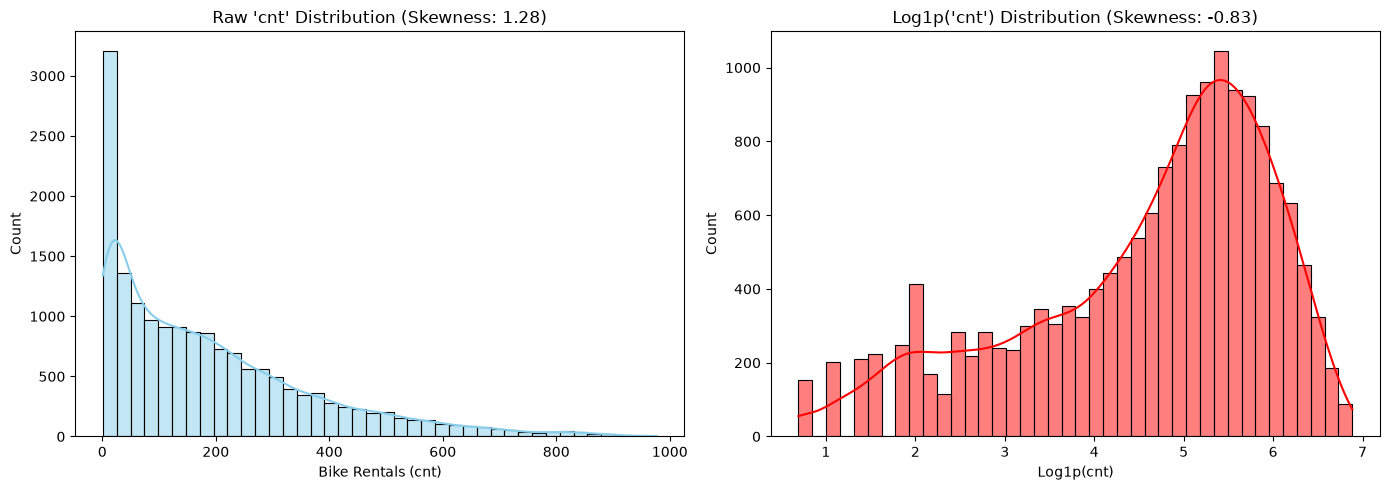

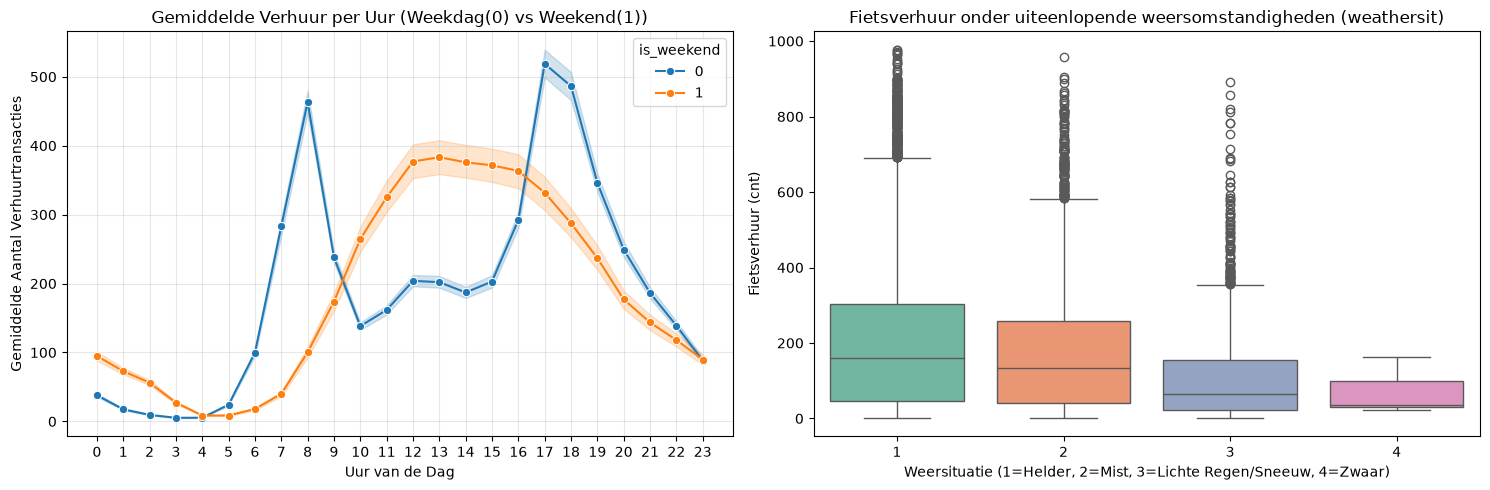

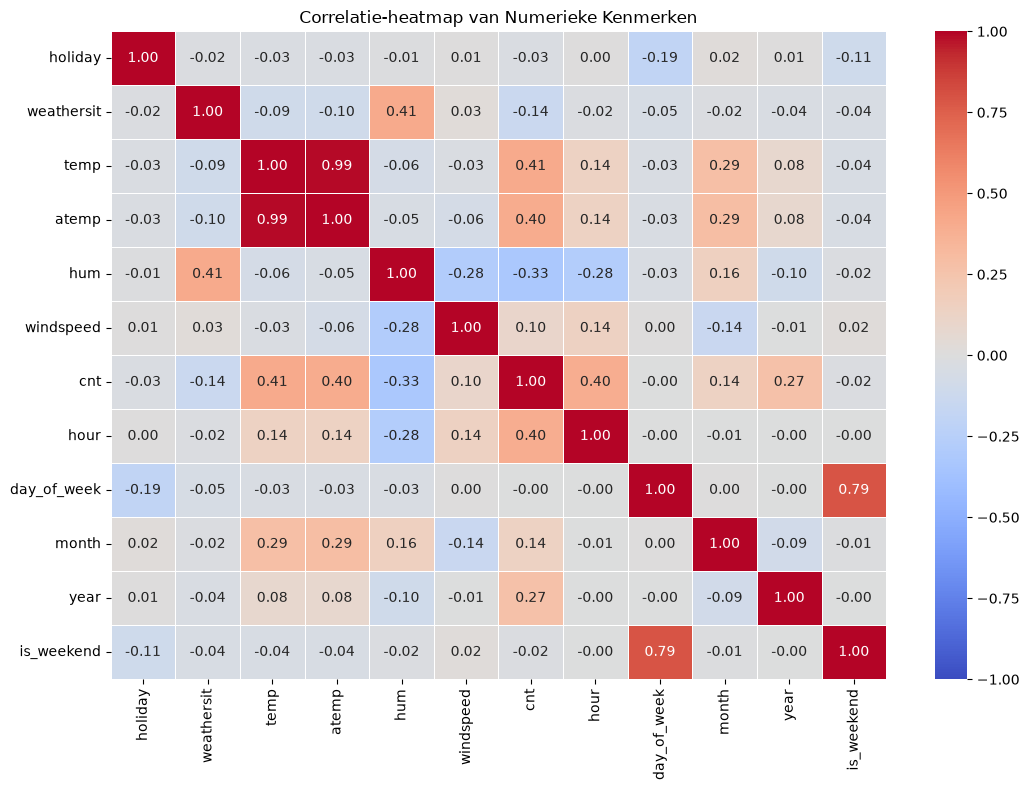

In [48]:
# Initialiseer de feature-engineer en EDA-analyzer
eda = EDAAnalyzer(datetime_col="date_hour", target_col="cnt")
time_eng = TimeFeatureEngineer(datetime_col="date_hour")

# Creeer kalendarkenmerken voor zowel de trainings- als de testset
train_df = time_eng.extract_calendar_features(train_df)
test_df = time_eng.extract_calendar_features(test_df)

# Analyseer de verdeling en de scheefheid van de doelvariabele
eda.plot_target_distribution(train_df)

# Ontdek de spitsuren per uur en de impact van het weer
eda.plot_key_relationships(train_df)

# Controleer correlaties tussen kenmerken (vooral temp vs atemp)
eda.plot_correlation_heatmap(train_df)


### 1.4 **Tijdsgebonden patronen: uur x weekdag en maand-op-maand**

De vraag wordt op twee assen sterk gestructureerd: het **uur van de dag** en de **weekdag**. De heatmap zet die twee assen tegen elkaar, zodat de vorm van de spitsuren per weekdag zichtbaar wordt. Rechts staan dezelfde maanden van 2011 en 2012 naast elkaar, zodat **groei** en **seizoensvorm** niet door elkaar worden gehaald.


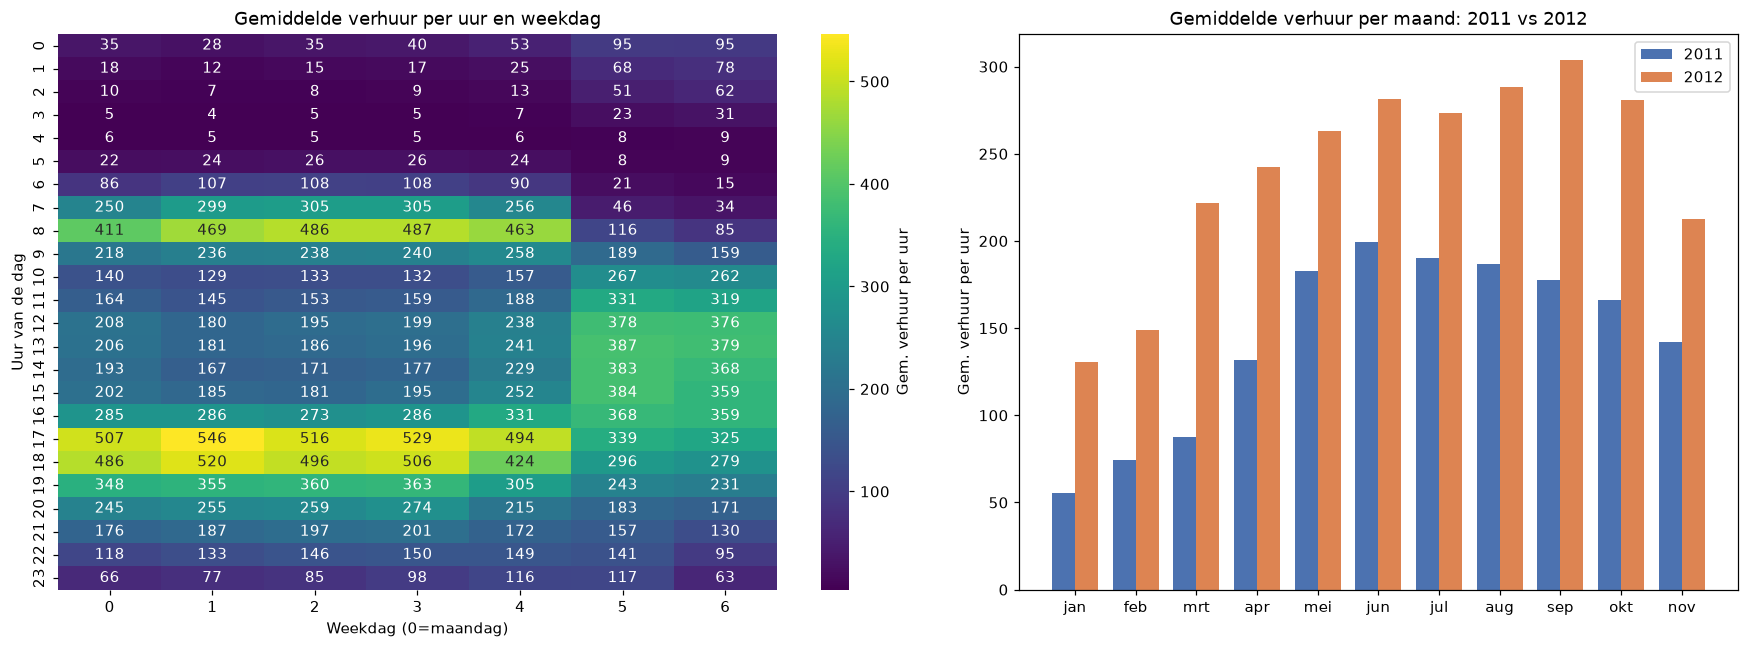

Groei 2012 t.o.v. 2011 per maand (%):
1     135.2
2     100.6
3     152.9
4      83.9
5      44.2
6      41.3
7      44.1
8      54.2
9      70.8
10     68.9
11     49.6


In [58]:
# Tijdsgebonden patronen: uur x weekdag en maand-op-maand
pivot_uur_weekdag = train_df.pivot_table(
    index="hour", columns="day_of_week", values="cnt", aggfunc="mean"
)
maand_per_jaar = train_df[train_df["month"] <= 11].pivot_table(
    index="month", columns="year", values="cnt", aggfunc="mean"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.25, 1]})

sns.heatmap(
    pivot_uur_weekdag,
    annot=True,
    fmt=".0f",
    cmap="viridis",
    cbar_kws={"label": "Gem. verhuur per uur"},
    ax=axes[0],
)
axes[0].set_title("Gemiddelde verhuur per uur en weekdag")
axes[0].set_xlabel("Weekdag (0 = maandag)")
axes[0].set_ylabel("Uur van de dag")

x = np.arange(len(maand_per_jaar))
axes[1].bar(x - 0.19, maand_per_jaar[2011], 0.38, label="2011", color="#4c72b0")
axes[1].bar(x + 0.19, maand_per_jaar[2012], 0.38, label="2012", color="#dd8452")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["jan", "feb", "mrt", "apr", "mei", "jun", "jul", "aug", "sep", "okt", "nov"])
axes[1].set_title("Gemiddelde verhuur per maand: 2011 versus 2012")
axes[1].set_ylabel("Gem. verhuur per uur")
axes[1].legend()

plt.tight_layout()
plt.show()

groei = ((maand_per_jaar[2012] / maand_per_jaar[2011] - 1) * 100).round(1)
print("Groei 2012 t.o.v. 2011 per maand (%):")
print(groei.to_string())


##### **Bevindingen: uur, weekdag en maand**

+ **Werkdagen zijn bimodaal.** De ochtendspits om 08:00 haalt gemiddeld **463** verhuur per uur en de avondspits om 17:00 gemiddeld **519**; het drukste uur van de week is dinsdag 17:00 met **546**. Tussen 10:00 en 15:00 zakt de vraag op werkdagen weg naar ongeveer 140 tot 205.
+ **Het weekend heeft een ander profiel, geen ander niveau.** In plaats van twee pieken is er een brede middagpiek tussen 12:00 en 16:00 (ongeveer 380-390 per uur), terwijl 08:00 op zaterdag en zondag met ongeveer 100 ongeveer vijf keer lager is dan op een werkdag. Het **dagelijkse gemiddelde** ontloopt elkaar veel minder (zondag 180, zaterdag 192, werkdagen 185-197); het verschil zit dus vooral in de **vorm**, niet in het volume.
+ **Seizoensvorm:** januari is met **94,4** per uur veruit de rustigste maand, juni en september zijn met ongeveer **241** het drukst, met een lichte dip in juli (232). December zit met 118 opnieuw laag: de feestdagen drukken de vraag.
+ **De groei is ongelijk verdeeld over het jaar.** 2012 ligt in elke maand boven 2011, maar de groei is veel groter in de winter (januari **+135%**, februari **+101%**, maart **+153%**) dan in de zomer (juni **+41%**, juli **+44%**). De **seizoensamplitude groeit dus mee met het niveau**; dat is een multiplicatief patroon en geen vast jaarlijks patroon.
+ **Gevolg voor de features:** een vast dagprofiel volstaat niet. Het model heeft zowel een **niveau-/trendterm** (`time_index`) als een **seizoensvorm** nodig die mee kan schalen (Fourier-termen, meerdere harmonischen). Dat wordt in sectie 3 uitgewerkt en in sectie 1.5 met STL onderbouwd.


### 1.5 **Seizoensdecompositie met STL**

Om trend, weekseizoen en rest van elkaar te scheiden gebruiken we **STL** (Seasonal-Trend decomposition using Loess) op het **dagtotaal**. STL is robuust tegen uitschieters, wat hier belangrijk is: enkele extreem slechte dagen mogen de trend niet vervormen. De decompositie beantwoordt twee vragen: hoeveel van de variatie zit in de trend, en is het weekpatroon constant of schaalt het mee met het niveau?


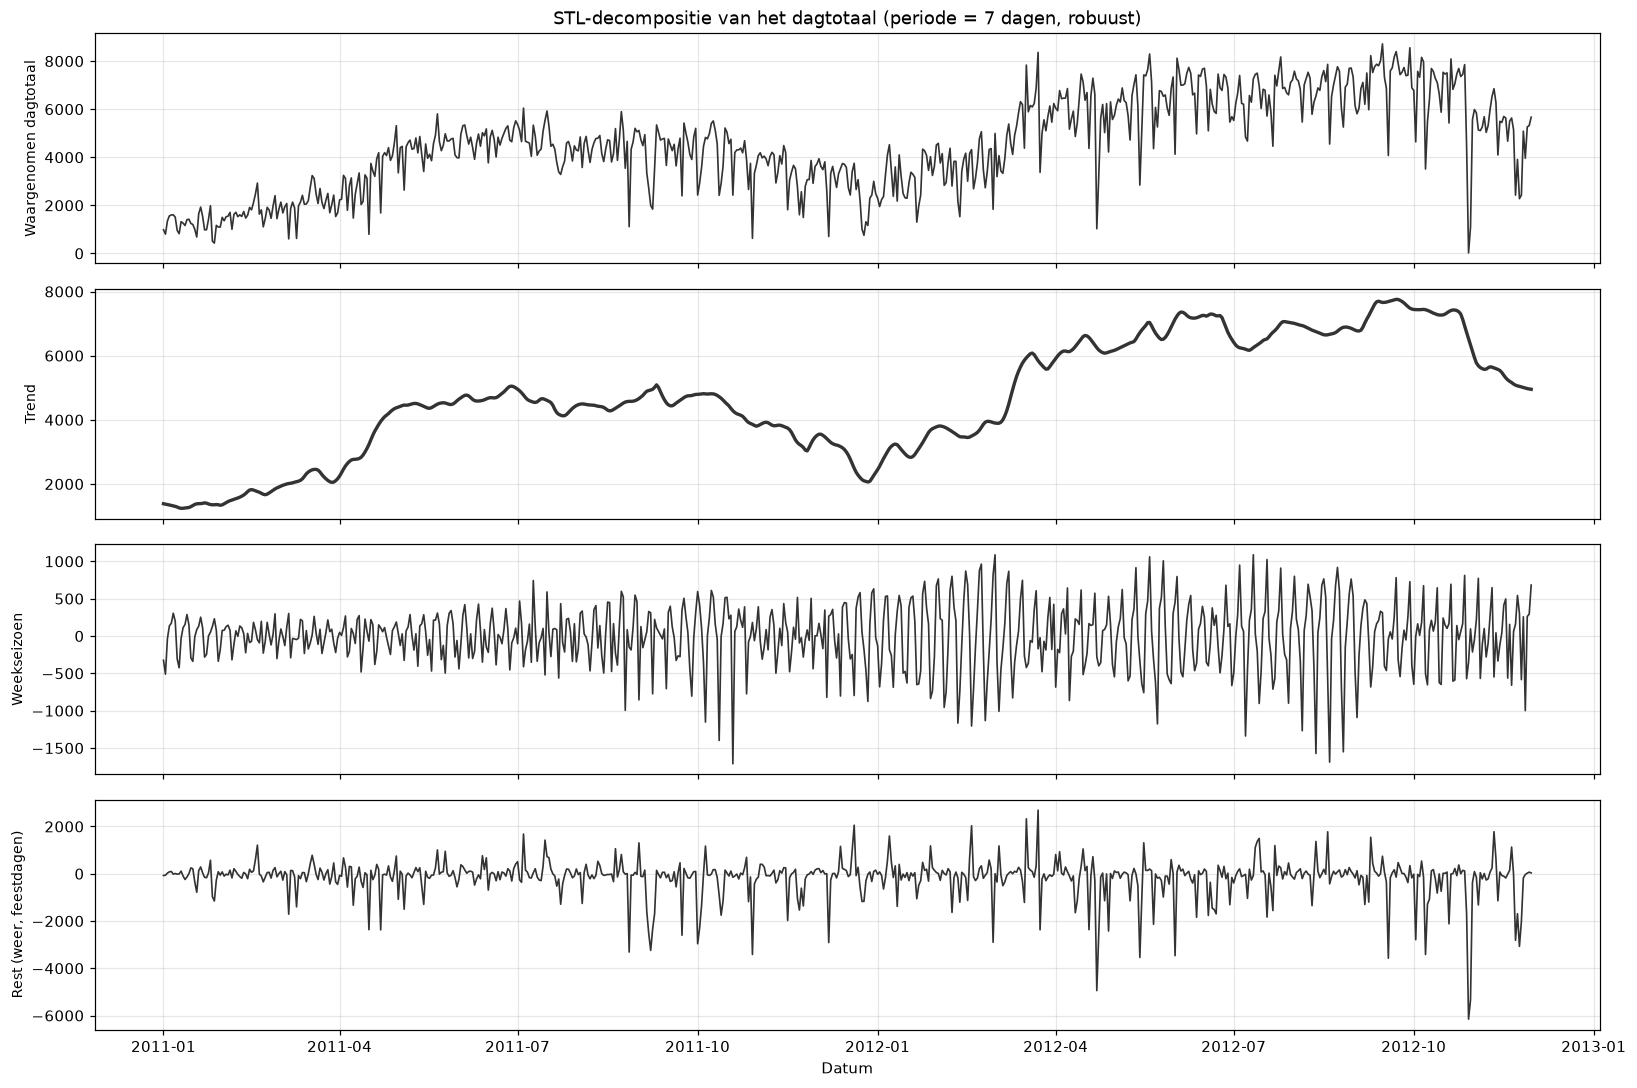

Trend verklaart 85.7% van de variantie van het dagtotaal
Weekseizoen verklaart 4.7%
Trend: 1384 aan het begin, maximum 7756 op 22-09-2012

Seizoensamplitude per half jaar (max - min van de weekcomponent):
  2011 H1: 938
  2011 H2: 2454
  2012 H1: 2292
  2012 H2: 2777

Grootste negatieve afwijkingen in de restcomponent:
date
2012-10-29   -6154.0
2012-10-30   -5336.0
2012-04-22   -4943.0
2012-09-18   -3572.0


In [59]:
# STL op het dagtotaal: trend, weekseizoen en rest
dag_totaal = train_df.set_index("date_hour")["cnt"].resample("D").sum().asfreq("D").interpolate()
stl = STL(dag_totaal, period=7, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
for ax, reeks, titel in zip(
    axes,
    [dag_totaal, stl.trend, stl.seasonal, stl.resid],
    ["Waargenomen dagtotaal", "Trend", "Weekseizoen", "Rest (weer, feestdagen)"],
):
    ax.plot(reeks.index, reeks.values, color="#333333", linewidth=2.0 if titel == "Trend" else 1.1)
    ax.set_ylabel(titel)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Datum")
axes[0].set_title("STL-decompositie van het dagtotaal (periode = 7 dagen, robuust)")
plt.tight_layout()
plt.show()

print(f"Trend verklaart {np.var(stl.trend) / np.var(dag_totaal):.1%} van de variantie van het dagtotaal")
print(f"Weekseizoen verklaart {np.var(stl.seasonal) / np.var(dag_totaal):.1%}")
print(
    f"Trend: {stl.trend.iloc[0]:.0f} aan het begin, "
    f"maximum {stl.trend.max():.0f} op {stl.trend.idxmax():%d-%m-%Y}"
)
print("\nSeizoensamplitude per half jaar (max - min van de weekcomponent):")
for label, deel in [
    ("2011 H1", slice(0, 182)),
    ("2011 H2", slice(182, 365)),
    ("2012 H1", slice(365, 547)),
    ("2012 H2", slice(547, None)),
]:
    week = stl.seasonal.iloc[deel]
    print(f"  {label}: {week.max() - week.min():.0f}")
print("\nGrootste negatieve afwijkingen in de restcomponent:")
print(stl.resid.nsmallest(4).round(0).to_string())


##### **Bevindingen: STL-decompositie**

+ **De trend domineert.** De trendcomponent alleen al verklaart **85,7%** van de variantie van het dagtotaal; het weekseizoen voegt daar **4,7%** aan toe. De resterende variatie zit in weer, feestdagen en meetruis.
+ De trend loopt van **1.384** (1 januari 2011) via een kort dal van **1.241** (10 januari 2011) naar een piek van **7.756** op **22 september 2012** en eindigt op **4.951**. De trend is dus niet lineair: hij bevat zowel de groei als de lange seizoensgolf.
+ **Het weekpatroon schaalt mee met het niveau.** De amplitude van de weekcomponent groeit van **938** in de eerste helft van 2011 naar **2.454**, **2.292** en **2.777** in de volgende halfjaren. Een vast weekpatroon (zoals `day_of_week` als categorische feature) onderschat daardoor de pieken in het tweede jaar en overschat ze in het eerste jaar. Dit pleit voor **Fourier-termen plus een niveauterm**, en tegen een puur additief weekeffect.
+ **De restcomponent bevat enkele extreme dagen.** De vier grootste negatieve afwijkingen zijn 29 en 30 oktober 2012 (Sandy) en 22 april 2012. Op **29 oktober 2012** werden in de hele dag **22 fietsen** verhuurd, tegen ongeveer 214 per uur in een normale oktobertijd. Dat is een orkaan, geen normale regendag: zulke gebeurtenissen zijn met deze features niet te voorspellen en bepalen de **ondergrens** van de haalbare fout. Ze verklaren ook waarom de RMSE op korte testblokken sterk kan schommelen.


### 1.6 **Weer: schijnbare versus werkelijke effecten**

De correlatiematrix in 1.3 suggereert dat temperatuur met +0,41 de sterkste voorspeller is. Die interpretatie is misleidend: temperatuur hangt sterk samen met het **seizoen**, en het seizoen hangt samen met de **trend**. Door de afwijking te bekijken **binnen dezelfde maand, weekdag en uur** verdwijnt het seizoenseffect uit beeld en blijft alleen het werkelijke weereffect over.


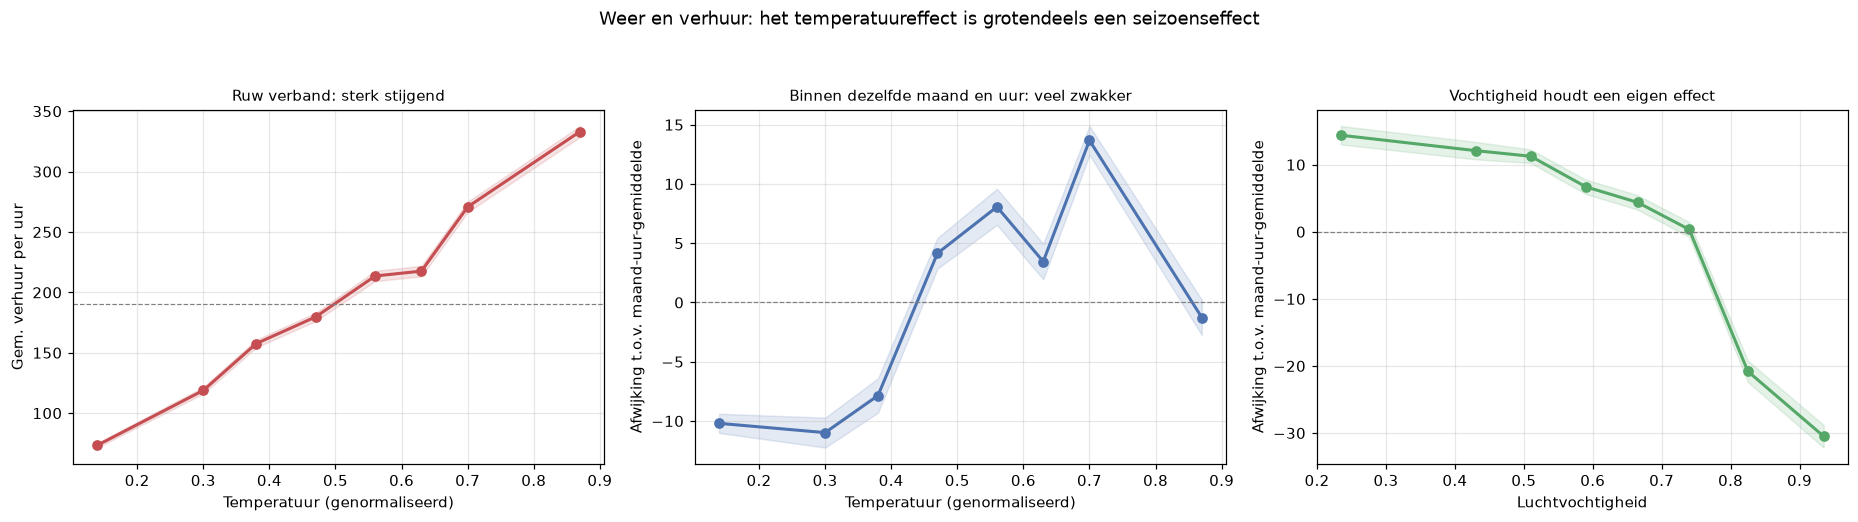

temp       correlatie met cnt: ruw +0.41, binnen maand en uur +0.10
hum        correlatie met cnt: ruw -0.34, binnen maand en uur -0.23
windspeed  correlatie met cnt: ruw +0.10, binnen maand en uur -0.05

Verhuur per weersituatie:
            mean  count
weathersit              
1          205.4  11078
2          175.8   4207
3          113.5   1349
4           74.3      3


In [60]:
# Ruw verband versus verband binnen dezelfde maand, weekdag en uur
train_df["cnt_binnen_periode"] = train_df["cnt"] - train_df.groupby(
    [train_df["date_hour"].dt.to_period("M"), "workingday", "hour"]
)["cnt"].transform("mean")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))


def binned_curve(ax, kolom, doel, kleur, titel, ylabel):
    """ Zet een numerieke variabele in kwantielbakken en plot het gemiddelde met foutmarge."""
    bins = pd.qcut(train_df[kolom], 8, duplicates="drop")
    gegroepeerd = train_df.groupby(bins, observed=True).agg(
        y=(doel, "mean"), s=(doel, "std"), n=(doel, "size")
    ).reset_index()
    gegroepeerd["x"] = gegroepeerd[bins.name].apply(lambda interval: interval.mid).astype(float)
    fout = gegroepeerd["s"] / np.sqrt(gegroepeerd["n"])
    ax.plot(gegroepeerd["x"], gegroepeerd["y"], marker="o", color=kleur, linewidth=2)
    ax.fill_between(gegroepeerd["x"], gegroepeerd["y"] - fout, gegroepeerd["y"] + fout, color=kleur, alpha=0.15)
    nulijn = 0 if doel == "cnt_binnen_periode" else train_df[doel].mean()
    ax.axhline(nulijn, color="grey", linestyle="--", linewidth=0.8)
    ax.set_xlabel(kolom)
    ax.set_ylabel(ylabel)
    ax.set_title(titel, fontsize=10)
    ax.grid(alpha=0.3)


binned_curve(axes[0], "temp", "cnt", "#c44e52", "Ruw verband: sterk stijgend", "Gem. verhuur per uur")
binned_curve(
    axes[1], "temp", "cnt_binnen_periode", "#4c72b0",
    "Binnen dezelfde maand en uur: veel zwakker", "Afwijking t.o.v. maand-uur-gemiddelde",
)
binned_curve(
    axes[2], "hum", "cnt_binnen_periode", "#55a868",
    "Vochtigheid houdt een eigen effect", "Afwijking t.o.v. maand-uur-gemiddelde",
)
plt.suptitle("Weer en verhuur: het temperatuureffect is grotendeels een seizoenseffect")
plt.tight_layout()
plt.show()

for kolom in ["temp", "hum", "windspeed"]:
    ruw = train_df[kolom].corr(train_df["cnt"])
    binnen = train_df[kolom].corr(train_df["cnt_binnen_periode"])
    print(f"{kolom:10s} correlatie met cnt: ruw {ruw:+.2f}, binnen maand en uur {binnen:+.2f}")

print("\nVerhuur per weersituatie:")
print(train_df.groupby("weathersit")["cnt"].agg(["mean", "count"]).round(1).to_string())


##### **Bevindingen: weer**

+ **Temperatuur is vooral een seizoensproxy.** De correlatie met `cnt` zakt van **+0,41** naar **+0,10** zodra we binnen dezelfde maand en hetzelfde uur kijken. Het ruwe verband loopt van 70 naar 333 verhuur per uur; binnen een maand blijven er afwijkingen van ongeveer -12 tot +14 over. Wie het ruwe verband als causaliteit leest, schrijft de groei van 2011 naar 2012 ten onrechte aan de temperatuur toe.
+ **Luchtvochtigheid houdt wel een eigen effect.** De correlatie gaat van **-0,34** naar **-0,23**, en het effect is het sterkst in de hoogste twee vochtigheidsklassen (-21 en -31 verhuur per uur). Dat is het signaal dat overblijft na correctie voor seizoen en uur.
+ **Windsnelheid verdwijnt.** Het zwakke positieve ruwe verband (+0,10) slaat om naar **-0,05** binnen maand en uur. Wind voegt dus weinig toe zodra het seizoen bekend is.
+ **Neerslag is duidelijk zichtbaar:** 205 (helder), 176 (mist), 114 (regen/sneeuw) en 74 (zware regen, slechts 3 rijen). `weathersit` werkt vooral als **neerslagindicator**, niet als temperatuurproxy.
+ **Gevolg voor de features:** het model heeft **zowel** seizoensfeatures als weerfeatures nodig. Zonder seizoen wordt de trend aan temperatuur toegeschreven; zonder weer mist het model de dagelijkse schommelingen. Dit motiveert de weer-afgeleiden in sectie 3.7.


### 1.7 **Feestdagen: een derde regime**

Naast werkdag en weekend is er een derde regime: de **feestdag**. Als feestdagen zich gedragen als een weekend, is `holiday` niet zomaar een extra variabele, maar verandert het **welk dagprofiel** geldt. We kijken daarom naar het gemiddelde per dagtype en naar de afstand tot de dichtstbijzijnde feestdag.


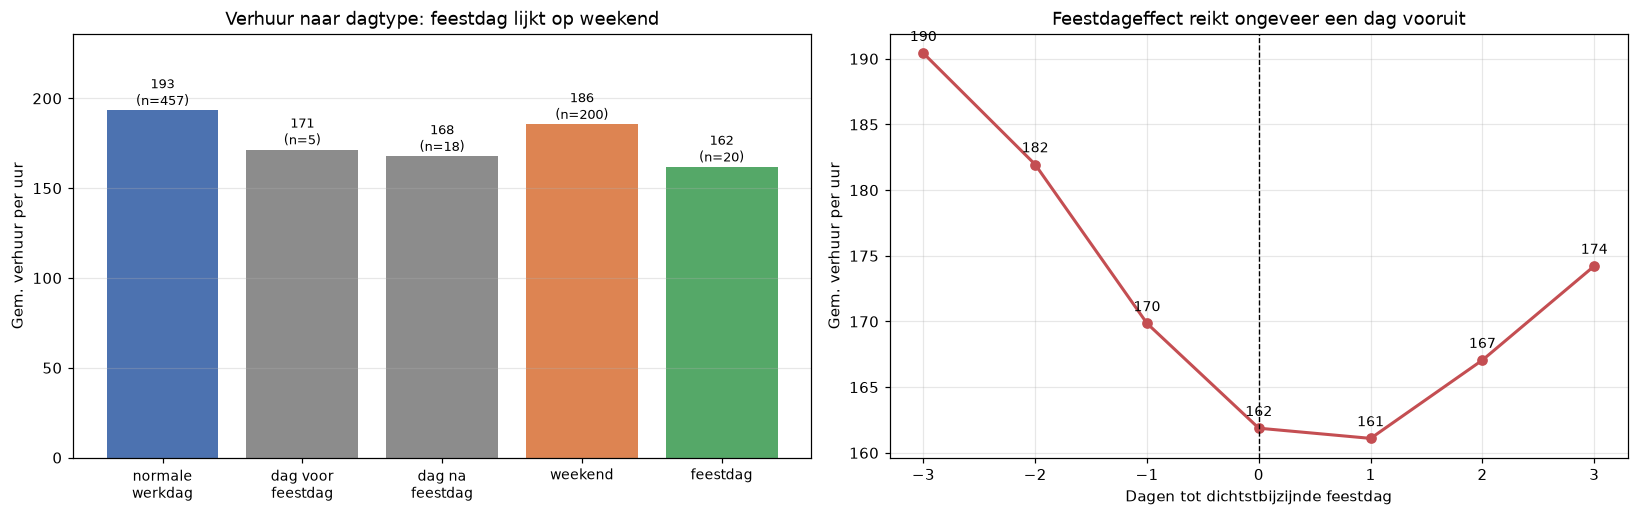

Gemiddelde verhuur per dagtype:
                        mean  count
dagtype                            
dag na feestdag        167.7     18
dag voor feestdag      171.4      5
feestdag               161.9     20
normale werkdag        193.3    457
weekend                185.6    200

Gemiddelde verhuur naar afstand tot de dichtstbijzijnde feestdag:
            mean  count
afstand              
-3         190.4     20
-2         182.0     20
-1         169.9     20
 0         161.9     20
 1         161.1     20
 2         167.1     20
 3         174.2     20


In [61]:
# Feestdagen: gemiddelde per dagtype en per afstand tot de dichtstbijzijnde feestdag
dag_frame = (
    train_df.groupby(train_df["date_hour"].dt.floor("D"))
    .agg(cnt=("cnt", "mean"), holiday=("holiday", "max"), day_of_week=("day_of_week", "first"))
    .reset_index()
    .rename(columns={"date_hour": "date"})
    .sort_values("date")
)

dag_frame["prev_holiday"] = dag_frame["holiday"].shift(1).fillna(0).astype(int)
dag_frame["next_holiday"] = dag_frame["holiday"].shift(-1).fillna(0).astype(int)


def dagtype(rij):
    """ Bepaalt het regime van een dag: feestdag, weekend, dag ervoor/erna of werkdag."""
    if rij["holiday"] == 1:
        return "feestdag"
    if rij["day_of_week"] >= 5:
        return "weekend"
    if rij["prev_holiday"] == 1:
        return "dag na feestdag"
    if rij["next_holiday"] == 1:
        return "dag voor feestdag"
    return "normale werkdag"


dag_frame["dagtype"] = dag_frame.apply(dagtype, axis=1)
volgorde = ["normale werkdag", "dag voor feestdag", "dag na feestdag", "weekend", "feestdag"]
dagtype_tabel = dag_frame.groupby("dagtype")["cnt"].agg(["mean", "count"]).reindex(volgorde)

feestdagen = list(dag_frame.loc[dag_frame["holiday"] == 1, "date"])


def afstand_tot_feestdag(datum):
    verschillen = np.array([(datum - feestdag) / np.timedelta64(1, "D") for feestdag in feestdagen])
    return int(round(verschillen[np.argmin(np.abs(verschillen))]))


dag_frame["afstand"] = dag_frame["date"].apply(afstand_tot_feestdag)
afstand_tabel = dag_frame[dag_frame["afstand"].abs() <= 3].groupby("afstand")["cnt"].agg(["mean", "count"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
kleuren = ["#4c72b0", "#8c8c8c", "#8c8c8c", "#dd8452", "#55a868"]
axes[0].bar(range(len(volgorde)), dagtype_tabel["mean"], color=kleuren)
axes[0].set_xticks(range(len(volgorde)))
axes[0].set_xticklabels(volgorde, fontsize=9, rotation=15, ha="right")
for teller, (waarde, aantal) in enumerate(zip(dagtype_tabel["mean"], dagtype_tabel["count"])):
    axes[0].text(teller, waarde + 3, f"{waarde:.0f}\n(n={int(aantal)})", ha="center", fontsize=8.5)
axes[0].set_ylim(0, dagtype_tabel["mean"].max() * 1.22)
axes[0].set_ylabel("Gem. verhuur per uur")
axes[0].set_title("Verhuur naar dagtype: feestdag lijkt op weekend")
axes[0].grid(axis="y", alpha=0.3)

axes[1].plot(afstand_tabel.index, afstand_tabel["mean"], marker="o", color="#c44e52", linewidth=2)
for x_waarde, y_waarde in zip(afstand_tabel.index, afstand_tabel["mean"]):
    axes[1].annotate(f"{y_waarde:.0f}", (x_waarde, y_waarde), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[1].axvline(0, color="k", linestyle="--", linewidth=0.9)
axes[1].set_xlabel("Dagen tot dichtstbijzijnde feestdag")
axes[1].set_ylabel("Gem. verhuur per uur")
axes[1].set_title("Feestdageffect reikt ongeveer een dag vooruit")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Gemiddelde verhuur per dagtype:")
print(dagtype_tabel.round(1).to_string())
print("\nGemiddelde verhuur naar afstand tot de dichtstbijzijnde feestdag:")
print(afstand_tabel.round(1).to_string())


##### **Bevindingen: feestdagen**

+ **Een feestdag zakt naar weekendniveau.** Op een normale werkdag wordt gemiddeld **193** per uur verhuurd, op een feestdag **162** (-16%) en in het weekend **186**. De feestdag lijkt dus meer op een zondag dan op een werkdag: het **dagprofiel** verandert, niet alleen het niveau.
+ **Het effect reikt ongeveer een dag vooruit.** De curve naar afstand tot de dichtstbijzijnde feestdag loopt van **190** (drie dagen ervoor) naar **162** (feestdag) en blijft met **161** laag op de dag erna, om pas na twee dagen te herstellen (167 en 174). De categorieën "dag voor" (171) en "dag na" (168) bevestigen dat beeld.
+ **Kleine steekproef.** Er zijn maar **20 feestdagen** (2,9% van de uren) en de categorie "dag voor feestdag" bevat 5 dagen. De richting van het effect is consistent, maar de exacte grootte is onzeker. Dat is precies waarom we in sectie 4.2 meten of feestdagfeatures de fout echt verkleinen in plaats van ze blind toe te voegen.


### 1.8 **Tijdcontinuiteit en datasplitsing**


In [49]:
# Controleer de opsplitsing in de tijd en de continuiteit van de uurreeks
eda.inspect_time_split(train_df, test_df)
eda.inspect_time_continuity({"Train": train_df, "Test": test_df})


--- TIME SPLIT ---
Train range: 2011-01-01 00:00:00 to 2012-11-30 23:00:00 (n = 16637)
Test range:  2012-12-01 00:00:00 to 2012-12-19 23:00:00 (n = 456)
Aantal testdagen: 19

--- TIME CONTINUITY ---
Train: 16637 rijen, 16800 uurwaarden verwacht, 163 ontbrekende uren, 73 gaten, langste gat 1 days 13:00:00, dubbelen 0
Test: 456 rijen, 456 uurwaarden verwacht, 0 ontbrekende uren, 0 gaten, langste gat 0 days 01:00:00, dubbelen 0



##### **Bevindingen: tijdcontinuiteit en datasplitsing**

+ De **trainset** loopt van 2011-01-01 00:00 tot 2012-11-30 23:00. In dat venster zijn **16.800 uurwaarden** verwacht, maar de dataset bevat **16.637 rijen**. Er ontbreken dus **163 uren**, verdeeld over **73 gaten**; het langste gat is **37 uur** (1 dag en 13 uur).
+ De **testset** is volledig aaneengesloten: 456 van 456 uurwaarden (19 dagen).
+ Er zijn **geen dubbele tijdstippen** in beide datasets.
+ Gevolg voor de analyse: de rolling means, FFT en ACF gaan uit van een aaneengesloten uurreeks. Omdat de ontbrekende uren ongeveer 1% van de reeks vormen, is de vertekening beperkt, maar het blijft een beperking van de analyse. De tijdfeatures (`time_index`, Fourier) worden daarom op basis van de **echte tijdstempels** berekend en niet op basis van rijnummers.


### 1.9 **Belangrijkste bevindingen van de EDA**


##### Lijngrafiek per uur, uitgesplitst naar weekend vs doordeweekse dagen:
##### 1. Spitsuren & de invloed van het weer: Doordeweekse dagen (is_weekend = 0) vertonen duidelijke, bimodale pieken in het woon-werkverkeer om 08:00 uur (ongeveer 460 verhuurtransacties) en tussen 17:00 en 18:00 uur (ongeveer 515 verhuurtransacties).
##### 2. Weekenden (is_weekend = 1): Toont een enkele, vloeiende curve voor vrijetijdsbesteding, met een piek tussen 12:00 en 16:00 uur (~370–380 verhuurgevallen).

##### Weersituatie Boxplot:
##### 3. Weer (weathersit): Het aantal verhuurde fietsen daalt gestaag naarmate het weer verslechtert, van helder (1) tot lichte regen/sneeuw (3), terwijl er bij zware regen/sneeuw (4) bijna geen waarnemingen zijn.

##### Correlatiematrix voor numerieke kenmerken: 
##### 4. Multicollineariteit & belangrijkste voorspellers: 'temp' en 'atemp' vertonen een vrijwel identieke correlatie van 0,99. Het behouden van beide zorgt voor redundantie / 'overfitten' in lineaire modellen; het is daarom raadzaam om te onderzoeken of er een van kunt weglaten.
##### 5. De sterkste lineaire correlaties met 'cnt' zijn temp (0,41), atemp (0,40), hour (0,40), hum (-0,33), year (0,27), weathersit (-0,14) en month (0,14). Merk op dat 'year' een positieve correlatie van 0,27 vertoont; dit betekent dat het totale fietsgebruik tussen 2011 en 2012 aanzienlijk is gegroeid.

##### Histogram van ruwe doelscheefheid tegen de log1p-getransformeerde doelscheefheid:
##### 6. Doelscheefheid: De onbewerkte variabele 'cnt' is sterk rechtsscheef (scheefheid = 1,28), waarbij in de meeste uren minder dan 200 verhuurtransacties plaatsvinden, met een lange staart die doorloopt tot ongeveer 950.
##### 7. Het toepassen van np.log1p(cnt) verlaagt de scheefheid van 1,28 naar -0,83. Dat is een duidelijke verbetering, maar de verdeling blijft linksscheef (|scheefheid| > 0,5); van volledige symmetrie is dus geen sprake. Omdat de modellen vooral baat hebben bij het intomen van de lange rechterstaart, gebruiken we log1p(cnt) als transformatie van de doelvariabele.


##### **Aanvullende bevindingen uit 1.4 - 1.7**

+ **Twee assen domineren de dagvorm:** uur en weekdag. Werkdagen zijn bimodaal (08:00 en 17:00), het weekend heeft een brede middagpiek en een vijf keer zo rustige ochtend.
+ **Het seizoen is multiplicatief:** de amplitude van het weekpatroon groeit van **938** (H1 2011) naar **2.777** (H2 2012), mee met het vraagniveau.
+ **Temperatuur is vooral een seizoensproxy:** de correlatie zakt van **+0,41** naar **+0,10** binnen maand en uur, terwijl vochtigheid een eigen effect houdt (**-0,23**). Neerslag (`weathersit`) is het duidelijkste weersignaal.
+ **Feestdagen zijn een derde regime:** een feestdag zakt naar weekendniveau (162 tegen 193 op een werkdag), met een effect dat ongeveer een dag vooruit reikt.
+ **Extreme gebeurtenissen bepalen de ondergrens:** op 29 oktober 2012 (orkaan Sandy) werden 22 fietsen verhuurd in plaats van ongeveer 5.000 per dag. Zulke dagen zijn niet voorspelbaar en zorgen voor een harde foutondergrens.


## 2. **Data opschonen en voorbereiden**


In [50]:
# Initialiseer de DataPreparer
preparer = DataPreparer(datetime_col="date_hour", target_col="cnt")

# Voer anomaliecontroles uit op zowel de trainings- als de testsets
preparer.check_anomalies(train_df, name="Train")
preparer.check_anomalies(test_df, name="Test")

# Anomalieen opschonen en de redundante variabele "atemp" verwijderen (correlatie 0,99 met "temp")
train_clean = preparer.clean_data(train_df, drop_atemp=True)
test_clean = preparer.clean_data(test_df, drop_atemp=True)


--- ANOMALY & SUMMARY CHECK (Train) ---


,min,50%,mean,max,std
date_hour,2011-01-01 00:00:00,2011-12-18 06:00:00,2011-12-18 02:20:08.294764,2012-11-30 23:00:00,NaN
holiday,0.0,0.0,0.028671,1.0,0.166885
weathersit,1.0,1.0,1.41558,4.0,0.637298
temp,0.02,0.52,0.504745,1.0,0.192369
atemp,0.0,0.5,0.482608,1.0,0.171557
hum,0.0,0.62,0.624756,1.0,0.193227
windspeed,0.0,0.194,0.19031,0.8507,0.121915
cnt,1.0,143.0,190.477009,977.0,182.026755
hour,0.0,12.0,11.547875,23.0,6.914199
day_of_week,0.0,3.0,3.008776,6.0,1.998538


Rows with hum == 0: 22
Rows with windspeed == 0: 2072

--- ANOMALY & SUMMARY CHECK (Test) ---


,min,50%,mean,max,std
date_hour,2012-12-01 00:00:00,2012-12-10 11:30:00,2012-12-10 11:30:00,2012-12-19 23:00:00,NaN
holiday,0.0,0.0,0.0,0.0,0.0
weathersit,1.0,2.0,1.592105,3.0,0.607882
temp,0.16,0.36,0.360132,0.6,0.079432
atemp,0.1818,0.3636,0.363691,0.6212,0.076354
hum,0.33,0.75,0.714868,1.0,0.177732
windspeed,0.0,0.1343,0.157639,0.4925,0.106499
hour,0.0,11.5,11.5,23.0,6.929789
day_of_week,0.0,3.0,2.947368,6.0,2.091709
month,12.0,12.0,12.0,12.0,0.0


Rows with hum == 0: 0
Rows with windspeed == 0: 72



#### **2.1 Onderbouwing van het opschonen**

+ **hum == 0**: 22 rijen in de trainset en 0 in de testset. Een luchtvochtigheid van exact 0% is fysiek onwaarschijnlijk en wijst op een sensorfout. Deze waarden zijn naar `NaN` gezet en lineair geinterpoleerd.
+ **windspeed == 0**: 2.072 rijen in de trainset (12,5%) en 72 in de testset. Dit is geen sensorfout maar windstilte; 0 is een geldige meting. Deze rijen blijven daarom behouden.
+ **atemp**: correleert 0,99 met `temp`. Beide behouden zorgt voor multicollineariteit in lineaire modellen, daarom is `atemp` verwijderd.
+ **Tijdstippen**: geen dubbele tijdstippen, wel ontbrekende uren (zie 1.4). Er is niet geinterpoleerd in de doelvariabele, omdat dat de validatie zou vertekenen. De tijdfeatures worden op basis van de echte tijdstempels berekend, zodat ontbrekende uren geen verschuiving veroorzaken.


## 3. **Time series feature engineering (Opdracht 2)**


In dit deel onderzoeken we de tijdreeksstructuur van de data en vertalen we die naar features:

1. **Trend** - langetermijngroei in de vraag.
2. **Seizoenspatronen met Fourier-analyse** - welke perioden (dag, week, jaar) domineren?
3. **Cycli en autocorrelatie** - hoe sterk hangt de vraag op dit uur samen met eerdere uren?
4. **Overige tijdsgebaseerde features** - spitsuren, nacht, werkdagen en een interactie met temperatuur.

De klasse hieronder bevat zowel de analysemethoden als de feature-constructors. In deel 4 meten we wat de invloed van elke featuregroep op de voorspellingen is.


In [51]:
class TimeSeriesAnalyzerAndEngineer:
    """ Voert tijdreeksdiagnostiek uit (trend, Fourier, ACF/PACF) en bouwt tijdreeksfeatures."""

    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col

    # TRENDS
    def plot_trends(self, df: pd.DataFrame):
        """ Toont de ruwe uurreeks met 7- en 30-daagse voortschrijdende gemiddelden.

        Zo wordt de langetermijntrend zichtbaar.
        """
        ts = df.set_index(self.datetime_col)[self.target_col]
        rolling_7d = ts.rolling(window=24 * 7, min_periods=1).mean()
        rolling_30d = ts.rolling(window=24 * 30, min_periods=1).mean()

        plt.figure(figsize=(15, 5))
        plt.plot(ts.index, ts, alpha=0.2, color="gray", label="Verhuur per Uur (Onbewerkt)")
        plt.plot(
            rolling_7d.index, rolling_7d, color="green", linewidth=1.5, label="7-day Rolling Mean"
        )
        plt.plot(
            rolling_30d.index, rolling_30d, color="r", linewidth=2.5, label="30-day Rolling Mean"
        )
        plt.title("Langetermijntrend & seizoensinvloeden bij fietsverhuur (2011 - 2012)")
        plt.xlabel("Datum")
        plt.ylabel("Verhuur (cnt)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def add_trend_features(self, df: pd.DataFrame, start_date: pd.Timestamp) -> pd.DataFrame:
        """ Voegt een continue tijdindex toe (uren sinds de startdatum) als trendfeature."""
        df = df.copy()
        df["time_index"] = (df[self.datetime_col] - start_date).dt.total_seconds() / 3600.0
        return df

    def _detrended_target(self, df: pd.DataFrame) -> np.ndarray:
        """ Haalt de lineaire trend uit de doelvariabele; anders domineert die de FFT en ACF."""
        y = df[self.target_col].to_numpy(dtype=float)
        verstreken = (df[self.datetime_col] - df[self.datetime_col].min()).dt.total_seconds()
        x = verstreken.to_numpy() / 3600.0
        trend = np.polyval(np.polyfit(x, y, 1), x)
        return y - trend

    # FOURIER SEASONALITY
    def plot_fourier_spectrum(self, df: pd.DataFrame, top_n: int = 6) -> pd.DataFrame:
        """ Berekent de FFT op de ont-trende reeks, plot het spectrum en geeft de top terug."""
        signal = self._detrended_target(df)
        power = np.abs(np.fft.rfft(signal))
        freqs = np.fft.rfftfreq(len(signal), d=1.0)  # d = 1 uur

        valid = freqs > 0
        periods = 1.0 / freqs[valid]
        power = power[valid]

        plt.figure(figsize=(14, 5))
        plt.plot(periods, power, color="steelblue", linewidth=1.2)
        plt.xscale("log")

        # Markeer de belangrijkste verwachte cycli
        verwachte_cycli = [
            (12, "12h (dubbel dagpatroon)"),
            (24, "24h (dagelijks)"),
            (168, "168h (wekelijks)"),
            (8760, "8760h (jaarlijks)"),
        ]
        for periode, label in verwachte_cycli:
            plt.axvline(periode, color="r", linestyle="--", alpha=0.8)
            plt.text(
                periode * 1.05,
                power.max() * 0.85,
                label,
                rotation=90,
                verticalalignment="top",
                fontsize=9,
            )

        plt.title("Fourier Power Spectrum van de ont-trende reeks (logaritmische periode-as)")
        plt.xlabel("Periode (uren, log-schaal)")
        plt.ylabel("Fourier-amplitude")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Selecteer de sterkste perioden en sla buren binnen 5% over
        top = []
        for idx in np.argsort(power)[::-1]:
            periode = periods[idx]
            if all(abs(periode - gekozen) / gekozen > 0.05 for gekozen in top):
                top.append(periode)
            if len(top) == top_n:
                break
        sterkste_perioden = pd.DataFrame({"periode_uren": top})
        sterkste_perioden["periode_dagen"] = (sterkste_perioden["periode_uren"] / 24).round(1)
        sterkste_perioden["power"] = [
            power[np.argmin(np.abs(periods - p))] for p in sterkste_perioden["periode_uren"]
        ]
        return sterkste_perioden

    def add_fourier_features(
        self, df: pd.DataFrame, harmonics: dict[int, int] | None = None
    ) -> pd.DataFrame:
        """ Voegt sin/cos-paren toe voor elke periode, met n harmonischen per periode."""
        if harmonics is None:
            harmonics = {24: 2, 168: 2, 8760: 1}

        df = df.copy()
        if "time_index" not in df.columns:
            raise ValueError("Run add_trend_features() first so 'time_index' exists.")

        for period, n_harmonics in harmonics.items():
            for k in range(1, n_harmonics + 1):
                angle = 2 * np.pi * k * df["time_index"] / period
                df[f"sin_{period}h_k{k}"] = np.sin(angle)
                df[f"cos_{period}h_k{k}"] = np.cos(angle)
        return df

    # CYCLES & AUTOCORRELATION
    def plot_autocorrelation(self, df: pd.DataFrame, max_lags: int = 168) -> None:
        """ Toont de ACF en PACF van de ont-trende reeks (max_lags = 168 uur = 1 volledige week)."""
        signal = pd.Series(self._detrended_target(df))

        _, axes = plt.subplots(2, 1, figsize=(15, 8))

        plot_acf(signal, lags=max_lags, ax=axes[0], color="steelblue")
        axes[0].set_title(f"ACF van de ont-trende reeks tot {max_lags} uur (1 week)")
        axes[0].set_xlabel("Lag (uren)")

        plot_pacf(signal, lags=72, ax=axes[1], color="seagreen", method="ywm")
        axes[1].set_title("PACF van de ont-trende reeks tot 72 uur (3 dagen)")
        axes[1].set_xlabel("Lag (uren)")

        plt.tight_layout()
        plt.show()

    def acf_at_lags(self, df: pd.DataFrame, lags: tuple[int, ...] = (24, 48, 168)) -> pd.Series:
        """ Geeft de ACF-waarden op specifieke lags terug (voor de interpretatie)."""
        waarden = acf(self._detrended_target(df), nlags=max(lags), fft=True)
        return pd.Series({f"lag_{lag}h": waarden[lag] for lag in lags})

    # OTHER TIME-BASED & INTERACTION FEATURES
    def add_domain_time_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Voegt spitsuren, nachtindicator, werkdagindicator en een temperatuurinteractie toe."""
        df = df.copy()

        # Definieer "workingday": geen weekend en geen feestdag
        df["workingday"] = ((df["is_weekend"] == 0) & (df["holiday"] == 0)).astype(int)

        # Ochtendspits (7-9 uur) en avondspits (16-19 uur) op werkdagen
        is_commute_hour = df["hour"].isin([7, 8, 9, 16, 17, 18, 19])
        df["is_rush_hour"] = (is_commute_hour & (df["workingday"] == 1)).astype(int)

        # Nachtindicator (00:00 - 05:00), wanneer de vraag het laagst is
        df["is_night"] = df["hour"].isin([0, 1, 2, 3, 4, 5]).astype(int)

        # Interactie: warm weer stimuleert vrijetijdsfietsen anders op werkdagen dan in het weekend.
        df["temp_x_workingday"] = df["temp"] * df["workingday"]
        return df


### 3.1 **Onderzoek naar trends**


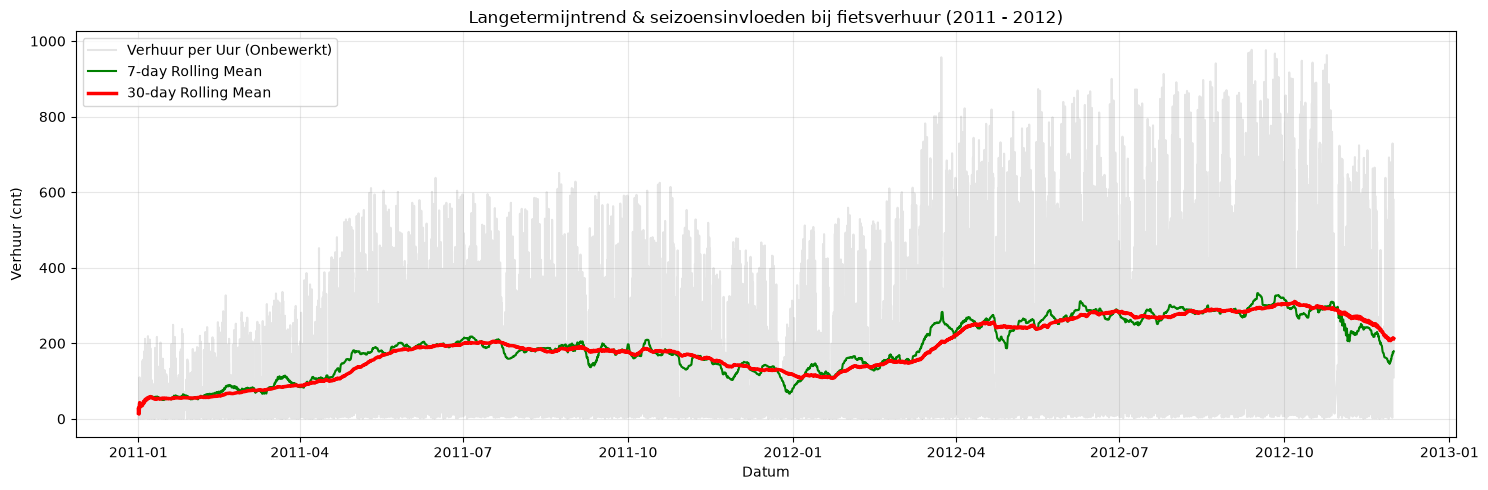

,mean,sum,count
year,,,
2011,146.2,1155780,7904
2012,241.0,1925863,7992


Gemiddeld aantal verhuur per uur (jan-nov): 64.8% groei van 2011 naar 2012
30-daags rollend gemiddelde: min 13 op 2011-01-01, max 311 op 2012-10-06


In [52]:
ts_engineer = TimeSeriesAnalyzerAndEngineer(datetime_col="date_hour", target_col="cnt")

# Trend zichtbaar maken met 7- en 30-daagse voortschrijdende gemiddelden
ts_engineer.plot_trends(train_clean)

# Groei kwantificeren: vergelijk januari t/m november van beide jaren
yearly = (
    train_clean[train_clean["month"] <= 11].groupby("year")["cnt"].agg(["mean", "sum", "count"])
)
display(yearly.round(1))
growth = (yearly.loc[2012, "mean"] / yearly.loc[2011, "mean"] - 1) * 100
print(f"Gemiddeld aantal verhuur per uur (jan-nov): {growth:.1f}% groei van 2011 naar 2012")

rolling_30d_reeks = (
    train_clean.set_index("date_hour")["cnt"].rolling(24 * 30, min_periods=1).mean()
)
print(
    f"30-daags rollend gemiddelde: min {rolling_30d_reeks.min():.0f} "
    f"op {rolling_30d_reeks.idxmin():%Y-%m-%d}, "
    f"max {rolling_30d_reeks.max():.0f} op {rolling_30d_reeks.idxmax():%Y-%m-%d}"
)


##### **Bevindingen: trend**

+ De vraag groeit structureel: het gemiddelde aantal verhuur per uur in januari t/m november stijgt van **146,2 in 2011** naar **241,0 in 2012**, een groei van **64,8%**.
+ Het 30-daagse voortschrijdende gemiddelde loopt op van **13** (1 januari 2011) naar **311** (6 oktober 2012).
+ De trend is niet lineair: in de winter van 2011/2012 daalt het 30-daagse gemiddelde (seizoensdal), waarna het in het voorjaar van 2012 opnieuw sterk stijgt. Een simpele lineaire `time_index` is daarom een benadering; in deel 4 blijkt hij nauwelijks iets toe te voegen bovenop de kalenderfeatures.


### 3.2 **Onderzoek naar seizoenspatronen met Fourier-analyse**


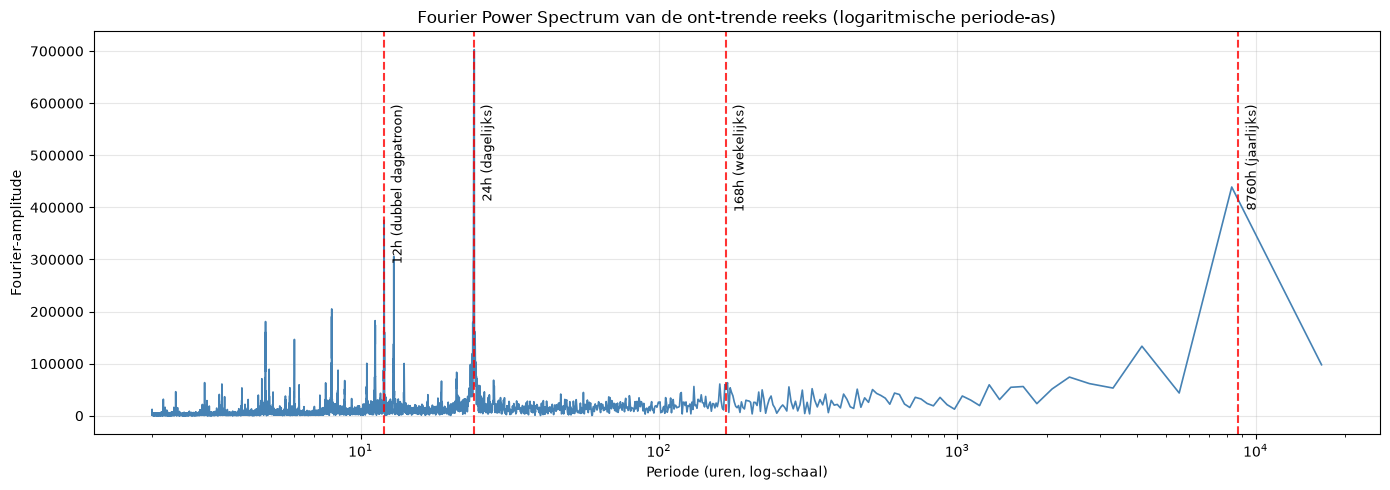

,periode_uren,periode_dagen,power
0,24.0,1.0,702786.9
1,8318.5,346.6,439107.2
2,12.0,0.5,375193.2
3,12.9,0.5,305708.3
4,8.0,0.3,205041.0
5,11.2,0.5,182599.1


In [53]:
top_periods = ts_engineer.plot_fourier_spectrum(train_clean, top_n=6)
display(top_periods.round(1))


##### **Bevindingen: Fourier-analyse**

+ Het spectrum wordt gedomineerd door de **dagcyclus**: de sterkste piek ligt op **24,0 uur** (power 702.787). De naastgelegen bins (23,97 uur, power 699.631) horen bij dezelfde piek en ontstaan door spectrale lekkage.
+ De **halfdaagse harmonischen** zijn duidelijk aanwezig: **12,0 uur** (375.193) en **12,9 uur** (305.708), plus de derde harmonische op **8,0 uur** (205.041). Dit past bij het dubbele dagpatroon met een ochtend- en een avondpiek.
+ Op de lange termijn is de **jaarcyclus** de sterkste component: **8.318,5 uur ≈ 346,6 dagen** (power 439.107). Dat de periode iets korter is dan 365 dagen komt doordat de reeks maar twee jaar beslaat en de trend niet perfect lineair is.
+ De **weekcyclus (168 uur)** is in dit spectrum zwak (power ongeveer 63.500, een kleine lokale piek rond 169,8 uur). Dat komt doordat de dagelijkse schommeling veel groter is dan het verschil tussen weekdagen en weekend. De autocorrelatie in 3.3 laat wel een duidelijke piek op 168 uur zien, daarom wordt de weekperiode als feature meegenomen.


### 3.3 **Onderzoek naar cycli en autocorrelatie**


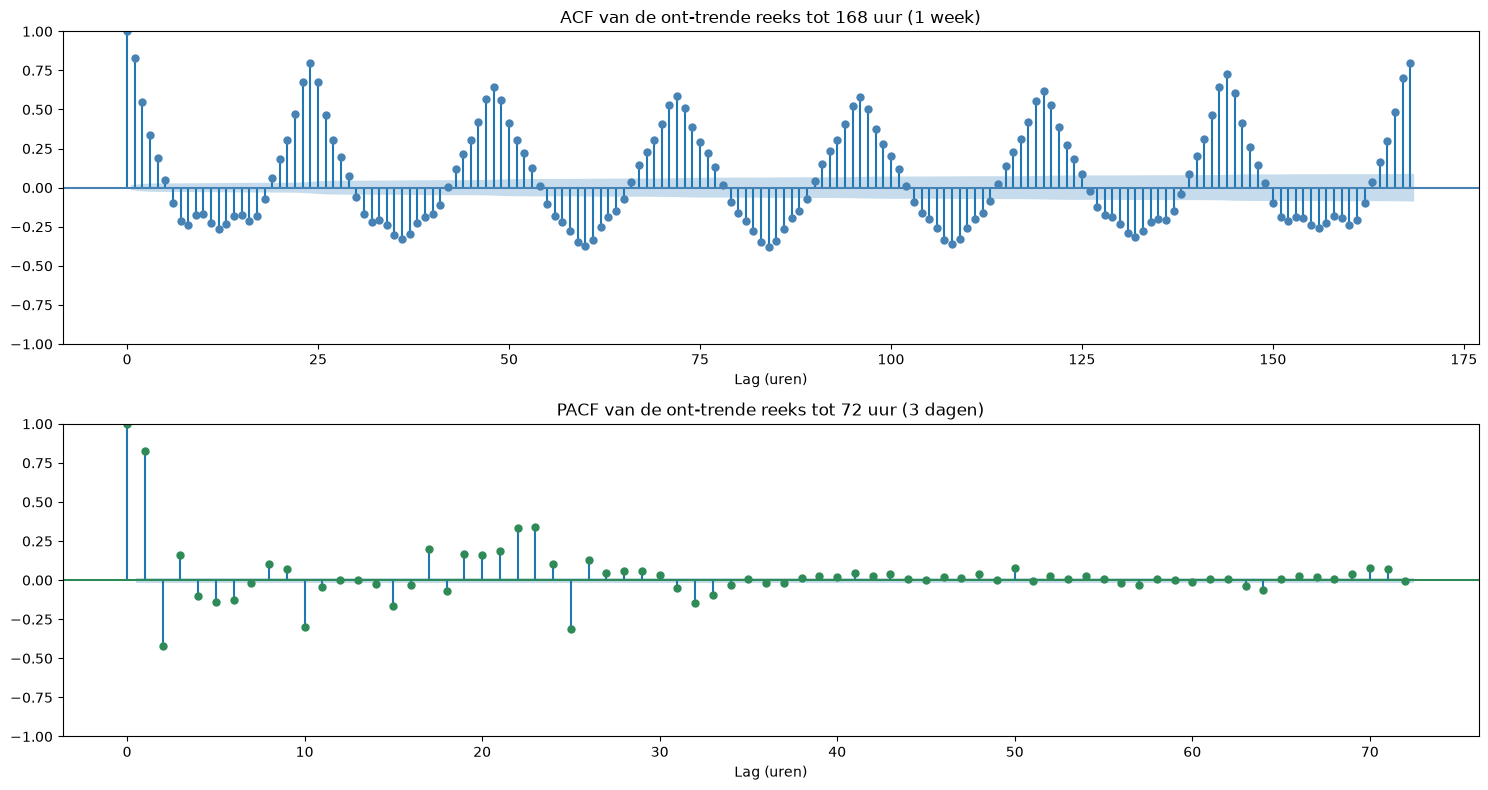

lag_24h     0.795
lag_48h     0.644
lag_168h    0.799
dtype: float64

In [54]:
ts_engineer.plot_autocorrelation(train_clean, max_lags=168)
display(ts_engineer.acf_at_lags(train_clean, lags=(24, 48, 168)).round(3))


##### **Bevindingen: cycli en autocorrelatie**

+ Kortetermijn: de ACF op lag 1 is **0,83**. De vraag van het vorige uur is dus sterk voorspellend.
+ **Dagcyclus:** er is een duidelijke piek op lag 24 (**0,80**), met lagere waarden direct ervoor en erna (lag 23: 0,68; lag 25: 0,67). Op lag 48 is de piek **0,64**; de correlatie neemt per dag af.
+ **Weekcyclus:** de piek op lag 168 (**0,80**) is zelfs iets hoger dan die op lag 24 en is een duidelijke lokale piek (lag 167: 0,70; lag 169: 0,65). Er is dus een echt weekritme, ook al is dat in het Fourier-spectrum minder zichtbaar.
+ De **negatieve waarde op lag 12 (-0,26)** bevestigt het dubbele dagpatroon: twaalf uur na een spits zit je in het dal tussen de pieken.
+ De PACF laat zien dat de directe voorspelkracht vooral in lag 1 en 2 zit. Daarna zijn er kleinere, significante pieken rond de dagcyclus (lag 23-25).


### 3.4 **Overige tijdsgebaseerde features en toepassing**


In [55]:
# Pas de geconstrueerde kenmerken toe op zowel de trainings- als de testset
train_start = train_clean["date_hour"].min()

train_fe = ts_engineer.add_trend_features(train_clean, start_date=train_start)
test_fe = ts_engineer.add_trend_features(test_clean, start_date=train_start)

train_fe = ts_engineer.add_fourier_features(train_fe, harmonics={24: 2, 168: 2, 8760: 1})
test_fe = ts_engineer.add_fourier_features(test_fe, harmonics={24: 2, 168: 2, 8760: 1})

train_fe = ts_engineer.add_domain_time_features(train_fe)
test_fe = ts_engineer.add_domain_time_features(test_fe)

print("New shape of train_fe:", train_fe.shape)
print("New shape of test_fe:", test_fe.shape)
feature_kolommen = "^(time_index|sin_|cos_|workingday|is_rush_hour|is_night|temp_x_workingday)"
display(train_fe.filter(regex=feature_kolommen).head())


New shape of train_fe: (16637, 27)
New shape of test_fe: (456, 26)


,time_index,sin_24h_k1,cos_24h_k1,sin_24h_k2,cos_24h_k2,sin_168h_k1,cos_168h_k1,sin_168h_k2,cos_168h_k2,sin_8760h_k1,cos_8760h_k1,workingday,is_rush_hour,is_night,temp_x_workingday
0,0.0,0.000000,1.000000,0.000000,1.000000e+00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0,0,1,0.0
1,1.0,0.258819,0.965926,0.500000,8.660254e-01,0.037391,0.999301,0.074730,0.997204,0.000717,1.000000,0,0,1,0.0
2,2.0,0.500000,0.866025,0.866025,5.000000e-01,0.074730,0.997204,0.149042,0.988831,0.001435,0.999999,0,0,1,0.0
3,3.0,0.707107,0.707107,1.000000,6.123234e-17,0.111964,0.993712,0.222521,0.974928,0.002152,0.999998,0,0,1,0.0
4,4.0,0.866025,0.500000,0.866025,-5.000000e-01,0.149042,0.988831,0.294755,0.955573,0.002869,0.999996,0,0,1,0.0


Na het toevoegen van de features heeft `train_fe` **27 kolommen** (25 features plus `date_hour` en `cnt`) en `test_fe` **26 kolommen**.

Gekozen Fourier-harmonischen, op basis van het spectrum in 3.2:

+ **24 uur - 2 harmonischen**: de dagcyclus plus de 12-uurs harmonische, samen goed voor de dubbele dagpiek.
+ **168 uur - 2 harmonischen**: het weekritme uit de ACF; twee harmonischen geven de weekvorm iets meer vrijheid.
+ **8760 uur - 1 harmonische**: de jaarcyclus. Meer harmonischen hebben weinig zin, omdat de reeks maar twee jaar beslaat en de trend het grootste deel van de langzame variatie al opvangt.

Daarnaast zijn `workingday`, `is_rush_hour`, `is_night` en `temp_x_workingday` toegevoegd. `time_index` en de Fourierfeatures worden voor de testset met **dezelfde startdatum** berekend, zodat de tijdas naadloos aansluit.


### 3.5 **Feestdagen- en bruggedagfeatures**

De analyse in 1.7 laat zien dat de vraag niet alleen van de weekdag afhangt, maar ook van de **afstand tot een feestdag**. Een gewone `holiday`-dummy legt alleen de feestdag zelf vast; de dip ervoor en erna blijft dan onbenut. We voegen daarom een **venster** rond elke feestdag toe:

+ `day_before_holiday` - de dag voor een feestdag.
+ `day_after_holiday` - de dag na een feestdag.
+ `near_holiday` - indicator voor de uren binnen drie dagen van een feestdag (zonder de feestdag zelf). Een rauwe afstandsteller is hier ongeschikt: buiten dat venster is de afstand niet meer informatief en zou de kolom bijna constant worden.

Deze uitbreiding bouwen we in een **aparte kopie** (`train_fe_extra`, `test_fe_extra`). Zo blijven de ablatietest in 4.1 en de submissions in sectie 5 ongewijzigd en onderling vergelijkbaar; in 4.2 meten we de meerwaarde van de nieuwe groepen.


In [0]:
# Feestdagvenster-features, in een aparte kopie van de featureset
train_fe_extra = train_fe.copy()
test_fe_extra = test_fe.copy()

feestdag_dagen = np.sort(train_df.loc[train_df["holiday"] == 1, "date_hour"].dt.floor("D").unique())


def voeg_feestdagfeatures_toe(df: pd.DataFrame, dagen: np.ndarray) -> pd.DataFrame:
    """ Voegt dag-voor, dag-na en de afstand tot de dichtstbijzijnde feestdag toe."""
    df = df.copy()
    df["_dag"] = df["date_hour"].dt.floor("D")
    kalender = pd.DataFrame({"date": pd.date_range(df["_dag"].min(), df["_dag"].max(), freq="D")})
    is_feestdag = kalender["date"].isin(dagen)
    kalender["day_before_holiday"] = is_feestdag.shift(-1, fill_value=False).astype(int)
    kalender["day_after_holiday"] = is_feestdag.shift(1, fill_value=False).astype(int)

    def afstand(datum):
        verschillen = np.array([(datum - dag) / np.timedelta64(1, "D") for dag in dagen])
        return int(round(verschillen[np.argmin(np.abs(verschillen))]))

    afstanden = kalender["date"].apply(afstand)
    # Buiten een venster van drie dagen is de afstand niet meer informatief; die uren
    # bundelen we in een enkele indicator in plaats van een bijna constante teller.
    kalender["near_holiday"] = ((afstanden.abs() <= 3) & (~is_feestdag)).astype(int)
    return df.join(kalender.set_index("date"), on="_dag").drop(columns=["_dag"])


train_fe_extra = voeg_feestdagfeatures_toe(train_fe_extra, feestdag_dagen)
test_fe_extra = voeg_feestdagfeatures_toe(test_fe_extra, feestdag_dagen)

print("Uren met een feestdagvenster-feature in de trainset:")
print(train_fe_extra[["day_before_holiday", "day_after_holiday", "near_holiday"]].sum().to_string())


Uren met een feestdagvenster-feature in de trainset:
day_before_holiday     478
day_after_holiday      459
near_holiday          2851


##### **Motivering van de feestdagfeatures**

+ De dip reikt volgens 1.7 ongeveer **een dag vooruit** en herstelt pas twee dagen na de feestdag. `day_before_holiday` en `day_after_holiday` maken dat venster expliciet; zonder die features moet een boommodel het uit de kalendercijfers afleiden, wat alleen lukt als er genoeg feestdagen in de training vallen (20 in twee jaar).
+ `near_holiday` bundelt de uren binnen drie dagen van een feestdag. Een ruwe afstandsteller zou voor het grootste deel van de uren dezelfde waarde hebben; de indicator is dan informatiever en stabieler.
+ De feature is **lekvrij**: hij is volledig te berekenen uit de kalender, die ook voor het testblok bekend is.
+ Omdat feestdagen maar **2,9%** van de uren beslaan, is de verwachte winst beperkt. Daarom meten we die in 4.2 in plaats van hem aan te nemen.


### 3.6 **Extra Fourier-harmonischen en een cyclische jaarterm**

De STL-analyse in 1.5 liet zien dat het weekpatroon **meeschaalt met het niveau**. Een vast weekeffect via `day_of_week` kan dat niet volgen: het is additief. Fourier-termen kunnen dat wel, mits er genoeg harmonischen zijn om de vorm scherp te krijgen. Het spectrum in 3.2 liet bovendien duidelijke pieken op **12 en 8 uur** zien (de dubbele dagpiek), wat precies de derde en vierde harmonische van de 24-uurscyclus zijn.

We breiden de Fourier-basis daarom uit:

+ **24 uur:** van 2 naar **4 harmonischen** (12, 8 en 6 uur), voor de scherpe ochtend- en avondpiek.
+ **168 uur:** van 2 naar **3 harmonischen**, voor de asymmetrie tussen zaterdag en zondag.
+ **8.760 uur:** van 1 naar **2 harmonischen**, omdat de jaarcyclus niet perfect sinusvormig is.
+ **`doy_sin` en `doy_cos`:** een cyclische jaarterm op basis van de dag van het jaar, die de seizoenspositie expliciet maakt zonder de discontinue sprong van `month` tussen december en januari.


In [0]:
# Extra Fourier-harmonischen en een cyclische jaarterm
def voeg_extra_seizoensfeatures_toe(df: pd.DataFrame) -> pd.DataFrame:
    """ Voegt hogere harmonischen toe (24u: k3 en k4, 168u: k3, 8760u: k2) plus een jaarterm."""
    df = df.copy()
    for k in (3, 4):
        hoek = 2 * np.pi * k * df["time_index"] / 24
        df[f"sin_24h_k{k}"] = np.sin(hoek)
        df[f"cos_24h_k{k}"] = np.cos(hoek)
    hoek = 2 * np.pi * 3 * df["time_index"] / 168
    df["sin_168h_k3"] = np.sin(hoek)
    df["cos_168h_k3"] = np.cos(hoek)
    hoek = 2 * np.pi * 2 * df["time_index"] / 8760
    df["sin_8760h_k2"] = np.sin(hoek)
    df["cos_8760h_k2"] = np.cos(hoek)
    df["doy_sin"] = np.sin(2 * np.pi * df["date_hour"].dt.dayofyear / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * df["date_hour"].dt.dayofyear / 365.25)
    return df


train_fe_extra = voeg_extra_seizoensfeatures_toe(train_fe_extra)
test_fe_extra = voeg_extra_seizoensfeatures_toe(test_fe_extra)

extra_seizoen = [
    "sin_24h_k3", "cos_24h_k3", "sin_24h_k4", "cos_24h_k4",
    "sin_168h_k3", "cos_168h_k3", "sin_8760h_k2", "cos_8760h_k2", "doy_sin", "doy_cos",
]
print(f"{len(extra_seizoen)} extra seizoensfeatures toegevoegd")
print("Controle: de eerste harmonischen blijven ongewijzigd.")
print(train_fe_extra[["sin_24h_k1", "cos_24h_k1", "sin_24h_k3", "doy_sin"]].head(3).round(3).to_string())


10 extra seizoensfeatures toegevoegd
Controle: de eerste harmonischen blijven ongewijzigd.
   sin_24h_k1  cos_24h_k1  sin_24h_k3  doy_sin
0       0.000       1.000       0.000    0.017
1       0.259       0.966       0.707    0.017
2       0.500       0.866       1.000    0.017


##### **Motivering van de extra seizoensfeatures**

+ De **hogere harmonischen zijn niet gratuit**: ze zijn direct te herleiden uit het FFT-spectrum in 3.2 (pieken op 24, 12 en 8 uur) en uit de STL-analyse in 1.5 (het weekpatroon is niet sinusvormig). Elke harmonische voegt twee parameters toe, wat de variantie van de schatting verhoogt. Daarom breiden we alleen uit waar het spectrum of de decompositie een reden geeft.
+ De **cyclische jaarterm** voorkomt de kunstmatige sprong die `month` maakt tussen december (12) en januari (1). Die sprong is precies in de periode waar de testset ligt, dus dit is een reëel probleem en geen detail.
+ Met een lineair model telt elke harmonische zwaar: Ridge kan de scherpe pieken niet maken zonder hogere harmonischen. Een boommodel kan de vorm ook uit `hour` leren, waardoor de winst daar veel kleiner zal zijn. Dat verschil meten we in 4.2.


### 3.7 **Weer-afgeleide features**

De analyse in 1.6 liet zien dat het **ruwe** temperatuureffect vooral een seizoenseffect is, terwijl **vochtigheid** en **neerslag** juist een eigen effect houden. We voegen daarom geen extra temperatuurvariabele toe, maar termen die de vorm van het verband vastleggen:

+ `temp_sq` - een kwadratische temperatuurterm, zodat het model een maximum kan leggen in plaats van een rechte lijn.
+ `temp_x_hum` - interactie: bij hoge vochtigheid voelt warmte anders en wordt er minder gefietst.
+ `hum_high` - indicator voor de hoogste vochtigheidsklasse, waar het effect volgens 1.6 het sterkst is (-21 en -31 verhuur per uur).
+ `bad_weather` en `rain` - ordinale vertaling van `weathersit` naar "niet helder" en "neerslag", de twee regimes die uit de boxplots naar voren kwamen.
+ `day_range` en `temp_rel_day` - de temperatuurspreiding binnen een dag en de afwijking van het daggemiddelde: een koude ochtend in een warme dag gedraagt zich anders dan een uniform koude dag.


In [0]:
# Weer-afgeleiden: nonlineariteit, interactie en dagvariatie
def voeg_weerfeatures_toe(df: pd.DataFrame) -> pd.DataFrame:
    """ Voegt niet-lineaire en interactie-termen voor het weer toe (zonder doelinformatie)."""
    df = df.copy()
    df["temp_sq"] = df["temp"] ** 2
    df["temp_x_hum"] = df["temp"] * df["hum"]
    df["hum_high"] = (df["hum"] > 0.8).astype(int)
    df["bad_weather"] = (df["weathersit"] >= 2).astype(int)
    df["rain"] = (df["weathersit"] >= 3).astype(int)
    per_dag = df["date_hour"].dt.floor("D")
    df["day_range"] = df.groupby(per_dag)["temp"].transform(lambda reeks: reeks.max() - reeks.min())
    df["temp_rel_day"] = df["temp"] - df.groupby(per_dag)["temp"].transform("mean")
    return df


train_fe_extra = voeg_weerfeatures_toe(train_fe_extra)
test_fe_extra = voeg_weerfeatures_toe(test_fe_extra)

print(f"Uitgebreide featureset: train {train_fe_extra.shape}, test {test_fe_extra.shape}")
print(f"Ontbrekende waarden in de features: {int(train_fe_extra.drop(columns=['date_hour', 'cnt']).isna().sum().sum())}")
print("\nAandeel uren met neerslag:", f"{(train_fe_extra['rain'].mean()):.1%}")
print("Aandeel uren met hoge vochtigheid:", f"{(train_fe_extra['hum_high'].mean()):.1%}")


Uitgebreide featureset: train (16637, 47), test (456, 46)
Ontbrekende waarden in de features: 0

Aandeel uren met neerslag: 8.1%
Aandeel uren met hoge vochtigheid: 22.5%


## 4. **Invloed van de features op de voorspellingen**


### 4.1 **Ablatietest met cumulatieve featuresets**


Opdracht 2 vraagt niet alleen om features, maar ook om te onderzoeken wat hun invloed is op de voorspellingen. We doen daarom een **ablatietest**: dezelfde modellen worden getraind op een cumulatief groeiende featureset en de fout wordt op chronologische wijze vergeleken.

+ **Featuresets**: (0) basis weer + feestdag -> (1) + kalenderfeatures -> (2) + trend -> (3) + Fourier -> (4) + domeinfeatures.
+ **Modellen**: Ridge (lineair, met L2-regularisatie) en Random Forest (niet-lineair ensemble), zodat de conclusie niet van een enkel model afhangt.
+ **Validatie**: `TimeSeriesSplit` met 4 chronologische folds van 30 dagen (geen shuffle, dus geen toekomstinformatie) en daarnaast een hold-out met de laatste 19 dagen, dezelfde horizon als de Kaggle-testset.
+ **Doelvariabele**: `log1p(cnt)`; voorspellingen worden met `expm1` teruggetransformeerd.
+ **Metrieken**: MAE en RMSE in fietsen per uur (RMSE is de officiële wedstrijdmetriek), aangevuld met RMSLE, die fouten op relatief niveau weegt.


In [56]:
# Chronologische splitsing: de laatste 19 dagen bootsen het testblok van de Kaggle-competitie na
X_train, X_val, y_train, y_val = preparer.create_time_validation_split(
    train_fe, val_days=19, use_log_target=True
)

fourier_cols = [col for col in train_fe.columns if col.startswith(("sin_", "cos_"))]

# Cumulatieve featuresets: elke stap voegt een groep tijdreeksfeatures toe
FEATURE_GROUPS = [
    ("0. Basis (weer + feestdag)", ["holiday", "weathersit", "temp", "hum", "windspeed"]),
    ("1. + kalenderfeatures", ["hour", "day_of_week", "month", "year", "is_weekend"]),
    ("2. + trend (time_index)", ["time_index"]),
    ("3. + Fourierfeatures", fourier_cols),
    ("4. + domeinfeatures", ["workingday", "is_rush_hour", "is_night", "temp_x_workingday"]),
]

feature_configs = {}
cumulatief = []
for groepsnaam, groep_kolommen in FEATURE_GROUPS:
    cumulatief = cumulatief + groep_kolommen
    feature_configs[groepsnaam] = list(cumulatief)


def maak_model(naam: str):
    """ Geeft per modelnaam een nieuw, ongetraind model terug."""
    if naam == "Ridge":
        return Ridge(alpha=1.0)
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)


def rmsle(y_true, y_pred) -> float:
    """ Root Mean Squared Logarithmic Error tussen werkelijke en voorspelde waarden."""
    return float(np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)))


def fit_en_score(
    naam: str,
    kolommen: list[str],
    train: tuple[pd.DataFrame, pd.Series],
    valid: tuple[pd.DataFrame, pd.Series],
) -> dict:
    """ Traint het model en scoort op de validatieset, teruggerekend naar fietsen per uur."""
    X_tr, y_tr = train
    X_te, y_te = valid

    # De preprocessor wordt per featureset op de trainingsfold gebouwd, zodat er geen
    # kolominformatie of schaalstatistiek uit de validatieset weglekt.
    pijplijn = Pipeline(
        [
            ("prep", preparer.build_preprocessor(X_tr[kolommen], scale_numeric=naam == "Ridge")),
            ("model", maak_model(naam)),
        ]
    )
    pijplijn.fit(X_tr[kolommen], y_tr)
    voorspelling = np.clip(np.expm1(pijplijn.predict(X_te[kolommen])), 0, None)
    werkelijk = np.expm1(y_te)
    return {
        "MAE": mean_absolute_error(werkelijk, voorspelling),
        "RMSE": np.sqrt(mean_squared_error(werkelijk, voorspelling)),
        "RMSLE": rmsle(werkelijk, voorspelling),
    }


# Time-series cross-validatie: 4 chronologische folds van 30 dagen
tscv = TimeSeriesSplit(n_splits=4, test_size=24 * 30)

cv_resultaten = []
for modelnaam in ("Ridge", "Random Forest"):
    for config, groep_kolommen in feature_configs.items():
        scores = {"MAE": [], "RMSE": [], "RMSLE": []}
        for train_idx, val_idx in tscv.split(X_train):
            fold = fit_en_score(
                modelnaam,
                groep_kolommen,
                (X_train.iloc[train_idx], y_train.iloc[train_idx]),
                (X_train.iloc[val_idx], y_train.iloc[val_idx]),
            )
            for metric, waarde in fold.items():
                scores[metric].append(waarde)
        cv_resultaten.append(
            {
                "model": modelnaam,
                "features": config,
                "n_features": len(groep_kolommen),
                "MAE": np.mean(scores["MAE"]),
                "MAE_std": np.std(scores["MAE"]),
                "RMSE": np.mean(scores["RMSE"]),
                "RMSLE": np.mean(scores["RMSLE"]),
            }
        )

cv_resultaten = pd.DataFrame(cv_resultaten).sort_values(["model", "MAE"]).reset_index(drop=True)
print("Time-series cross-validatie (gemiddelde over 4 folds van 30 dagen)")
display(cv_resultaten.round(2))

# Hold-out: de laatste 19 dagen, dezelfde horizon als de Kaggle-testset
holdout_resultaten = []
for modelnaam in ("Ridge", "Random Forest"):
    for config, groep_kolommen in feature_configs.items():
        score = fit_en_score(modelnaam, groep_kolommen, (X_train, y_train), (X_val, y_val))
        holdout_resultaten.append(
            {"model": modelnaam, "features": config, "n_features": len(groep_kolommen), **score}
        )

holdout_resultaten = (
    pd.DataFrame(holdout_resultaten).sort_values(["model", "MAE"]).reset_index(drop=True)
)
print("Hold-out: laatste 19 dagen")
display(holdout_resultaten.round(2))


Train split: 2011-01-01 00:00:00 to 2012-11-11 23:00:00 (n=16182)
Val split:   2012-11-12 00:00:00 to 2012-11-30 23:00:00 (n=455)
Time-series cross-validatie (gemiddelde over 4 folds van 30 dagen)


,model,features,n_features,MAE,MAE_std,RMSE,RMSLE
0,Random Forest,4. + domeinfeatures,25,42.11,4.72,68.10,0.31
1,Random Forest,3. + Fourierfeatures,21,43.13,3.70,69.19,0.31
2,Random Forest,2. + trend (time_index),11,43.72,2.72,69.49,0.31
3,Random Forest,1. + kalenderfeatures,10,46.67,5.43,73.57,0.32
4,Random Forest,0. Basis (weer + feestdag),5,177.23,12.87,246.45,1.27
5,Ridge,4. + domeinfeatures,25,90.79,4.49,132.62,0.55
6,Ridge,3. + Fourierfeatures,21,113.35,3.26,165.13,0.65
7,Ridge,1. + kalenderfeatures,10,148.04,6.37,211.39,0.97
8,Ridge,2. + trend (time_index),11,148.17,6.19,211.55,0.97
9,Ridge,0. Basis (weer + feestdag),5,181.21,18.30,253.28,1.20


Hold-out: laatste 19 dagen


,model,features,n_features,MAE,RMSE,RMSLE
0,Random Forest,3. + Fourierfeatures,21,40.10,72.00,0.42
1,Random Forest,4. + domeinfeatures,25,40.83,73.73,0.42
2,Random Forest,2. + trend (time_index),11,41.84,76.89,0.46
3,Random Forest,1. + kalenderfeatures,10,41.93,76.19,0.42
4,Random Forest,0. Basis (weer + feestdag),5,135.57,195.18,1.42
5,Ridge,4. + domeinfeatures,25,74.93,120.28,0.63
6,Ridge,3. + Fourierfeatures,21,90.37,137.44,0.72
7,Ridge,1. + kalenderfeatures,10,117.40,174.65,1.08
8,Ridge,2. + trend (time_index),11,117.40,174.66,1.08
9,Ridge,0. Basis (weer + feestdag),5,145.28,207.08,1.37


##### **Bevindingen: invloed van de features**

+ **Tijdreeksfeatures verkleinen de fout sterk.** Zonder tijdsfeatures voorspelt Random Forest met MAE **177,2** (RMSLE 1,27); met alle features is dat **42,1** (RMSLE 0,31), een foutreductie van **76%**. Bij Ridge gaat de MAE van **181,2** naar **90,8** (RMSLE 1,20 -> 0,55), een reductie van **50%**.
+ **Kalenderfeatures** (uur, dag van de week, maand, jaar) leveren de grootste sprong op: Random Forest 177,2 -> 46,7 en Ridge 181,2 -> 148,0.
+ **Fourierfeatures** voegen vooral voor het lineaire model veel toe: Ridge 148,0 -> 113,4 (**-23%**); Random Forest 46,7 -> 43,1 (-8%).
+ **Trend (`time_index`)** voegt weinig extra toe zodra `year` al in de features zit: Ridge 148,0 -> 148,2 (geen verbetering) en Random Forest 46,7 -> 43,7. Dat is logisch: `year` vangt de niveauverschuiving tussen 2011 en 2012 al op, en een boommodel kan `time_index` niet voorbij de hoogste waarde uit de training extrapoleren. Voor de testset (december 2012) is dat laatste een echt bezwaar.
+ **Domeinfeatures** (spits, nacht, werkdag, temperatuurinteractie) geven nog een kleine winst: Ridge 113,4 -> 90,8 (**-20%**), Random Forest 43,1 -> 42,1 (-2%).
+ Op de **hold-out van 19 dagen** is het beeld consistent: Random Forest met Fourierfeatures haalt MAE **40,1** en RMSLE **0,42**; met alle features is dat 40,8. Het verschil tussen beide is klein, dus de domeinfeatures voegen op deze korte horizon weinig toe.
+ Het **Random Forest** presteert duidelijk beter dan Ridge (MAE 42,1 versus 90,8 in de cross-validatie). Dat is een eerste indicatie dat een niet-lineair ensemble de beste keuze is; de definitieve modelkeuze hoort bij Opdracht 3.


### 4.2 **Invloed van de uitgebreide features**

De ablatietest in 4.1 gebruikt de featureset uit sectie 3.4. In 3.5 tot en met 3.7 hebben we drie extra groepen gebouwd. We meten ze met **exact dezelfde folds, modellen en metrieken** als in 4.1, zodat de cijfers vergelijkbaar zijn. Elke groep wordt **los** toegevoegd aan de referentieset (`4. + domeinfeatures`), zodat het effect per groep te lezen is; de laatste rij combineert alles.


In [0]:
# Zelfde folds en modellen als 4.1, nu met de uitgebreide featureset
X_train_extra, X_val_extra, y_train_extra, y_val_extra = preparer.create_time_validation_split(
    train_fe_extra, val_days=19, use_log_target=True
)

BASIS_EXTRA = feature_configs["4. + domeinfeatures"]
FEESTDAG_KOLOMMEN = ["day_before_holiday", "day_after_holiday", "near_holiday"]
SEIZOEN_KOLOMMEN = [
    "sin_24h_k3", "cos_24h_k3", "sin_24h_k4", "cos_24h_k4",
    "sin_168h_k3", "cos_168h_k3", "sin_8760h_k2", "cos_8760h_k2", "doy_sin", "doy_cos",
]
WEER_KOLOMMEN = ["temp_sq", "temp_x_hum", "hum_high", "bad_weather", "rain", "day_range", "temp_rel_day"]

UITBREIDINGEN = {
    "4. + domeinfeatures (referentie)": [],
    "5. + feestdagenfeatures": FEESTDAG_KOLOMMEN,
    "6. + extra seizoensfeatures": SEIZOEN_KOLOMMEN,
    "7. + weer-afgeleiden": WEER_KOLOMMEN,
    "8. + alles": FEESTDAG_KOLOMMEN + SEIZOEN_KOLOMMEN + WEER_KOLOMMEN,
}

cv_uitbreiding = []
for config, extra in UITBREIDINGEN.items():
    kolommen = BASIS_EXTRA + extra
    for modelnaam in ("Ridge", "Random Forest"):
        scores = {"MAE": [], "RMSE": [], "RMSLE": []}
        for train_idx, val_idx in tscv.split(X_train_extra):
            fold = fit_en_score(
                modelnaam,
                kolommen,
                (X_train_extra.iloc[train_idx], y_train_extra.iloc[train_idx]),
                (X_train_extra.iloc[val_idx], y_train_extra.iloc[val_idx]),
            )
            for metriek, waarde in fold.items():
                scores[metriek].append(waarde)
        cv_uitbreiding.append(
            {
                "model": modelnaam,
                "features": config,
                "n_features": len(kolommen),
                "MAE": np.mean(scores["MAE"]),
                "MAE_std": np.std(scores["MAE"]),
                "RMSE": np.mean(scores["RMSE"]),
                "RMSLE": np.mean(scores["RMSLE"]),
            }
        )

cv_uitbreiding = pd.DataFrame(cv_uitbreiding).sort_values(["model", "MAE"]).reset_index(drop=True)
print("Time-series cross-validatie met de uitgebreide features (gemiddelde over 4 folds)")
display(cv_uitbreiding.round(2))

holdout_uitbreiding = []
for config, extra in UITBREIDINGEN.items():
    kolommen = BASIS_EXTRA + extra
    for modelnaam in ("Ridge", "Random Forest"):
        holdout_uitbreiding.append(
            {
                "model": modelnaam,
                "features": config,
                "n_features": len(kolommen),
                **fit_en_score(
                    modelnaam, kolommen, (X_train_extra, y_train_extra), (X_val_extra, y_val_extra)
                ),
            }
        )

holdout_uitbreiding = (
    pd.DataFrame(holdout_uitbreiding).sort_values(["model", "MAE"]).reset_index(drop=True)
)
print("Hold-out: laatste 19 dagen")
display(holdout_uitbreiding.round(2))


Train split: 2011-01-01 00:00:00 to 2012-11-11 23:00:00 (n=16182)
Val split:   2012-11-12 00:00:00 to 2012-11-30 23:00:00 (n=455)
Time-series cross-validatie met de uitgebreide features (gemiddelde over 4 folds)


,model,features,n_features,MAE,MAE_std,RMSE,RMSLE
0,Random Forest,7. + weer-afgeleiden,32,42.05,5.19,66.78,0.31
1,Random Forest,5. + feestdagenfeatures,28,42.07,4.50,68.21,0.31
2,Random Forest,4. + domeinfeatures (referentie),25,42.11,4.72,68.10,0.31
3,Random Forest,8. + alles,45,42.90,5.16,68.17,0.31
4,Random Forest,6. + extra seizoensfeatures,35,43.10,5.01,69.40,0.31
5,Ridge,8. + alles,45,80.32,4.53,115.00,0.51
6,Ridge,6. + extra seizoensfeatures,35,84.53,2.89,121.38,0.52
7,Ridge,7. + weer-afgeleiden,32,86.04,4.84,124.79,0.54
8,Ridge,4. + domeinfeatures (referentie),25,90.79,4.49,132.62,0.55
9,Ridge,5. + feestdagenfeatures,28,91.34,5.08,133.34,0.55


Hold-out: laatste 19 dagen


,model,features,n_features,MAE,RMSE,RMSLE
0,Random Forest,5. + feestdagenfeatures,28,40.47,73.19,0.42
1,Random Forest,7. + weer-afgeleiden,32,40.83,74.05,0.41
2,Random Forest,4. + domeinfeatures (referentie),25,40.83,73.73,0.42
3,Random Forest,6. + extra seizoensfeatures,35,41.06,74.28,0.42
4,Random Forest,8. + alles,45,41.16,74.17,0.41
5,Ridge,8. + alles,45,63.61,103.69,0.56
6,Ridge,6. + extra seizoensfeatures,35,64.38,103.84,0.57
7,Ridge,7. + weer-afgeleiden,32,72.49,120.58,0.61
8,Ridge,5. + feestdagenfeatures,28,72.77,115.54,0.61
9,Ridge,4. + domeinfeatures (referentie),25,74.93,120.28,0.63


##### **Bevindingen: uitgebreide features**

+ **De extra seizoensfeatures helpen het lineaire model duidelijk.** Bij Ridge daalt de cross-validatie-MAE van **90,8** naar **84,5**, en met alle groepen samen naar **80,3** (-11,5%). Op de hold-out gaat de RMSE van **120,3** naar **103,8** en de MAE van **74,9** naar **64,4** (-14%); met alle groepen samen is dat **103,7** en **63,6** (-15%). Dat past bij 4.1: een lineair model heeft meer harmonischen nodig om de scherpe dagpieken te kunnen maken.
+ **Het Random Forest is verzadigd.** De MAE blijft tussen **42,0** en **43,1** en de hold-out-RMSE tussen **73,2** en **74,3**. Een boommodel leest de dagvorm al uit `hour` en `day_of_week`; extra harmonischen voegen daar weinig aan toe en de "alles"-variant is zelfs iets slechter dan de referentie (42,90 tegen 42,11 in de cross-validatie). Dat wijst op overfitting door variabelen die weinig extra informatie bevatten.
+ **Feestdagfeatures geven een klein en wisselend effect.** Op de hold-out gaan beide modellen vooruit (Ridge RMSE **120,3** naar **115,5**, Random Forest **73,73** naar **73,19**), maar in de cross-validatie verslechtert Ridge licht (**90,8** naar **91,3**). Met 20 feestdagen in twee jaar is het effect te klein om betrouwbaar te schatten; de richting is gunstig, de grootte niet.
+ **Weer-afgeleiden zijn niet consistent.** In de cross-validatie is het de beste groep voor de RMSE van Random Forest (**68,10** naar **66,78**) en gaat Ridge vooruit (**90,8** naar **86,0**), maar op de hold-out verandert er niets (Random Forest 73,73 naar 74,05; Ridge 120,28 naar 120,58). Zonder winst op beide validaties nemen we de groep niet op.
+ **Conclusie voor de featureset:** de extra **seizoensfeatures** zijn de enige groep met een robuuste, theoretisch verwachte winst, en die winst zit bij het lineaire model. De feestdag- en weergroepen blijven in het notebook als onderzochte maar verworpen uitbreidingen. De gekozen featureset voor de submissions in sectie 5 blijft daarom die van 4.1.
+ **Belangrijker dan de winst is de asymmetrie:** extra feature engineering helpt vooral het model dat de vorm niet zelf kan leren. Dat is een algemene les: de meerwaarde van features hangt af van de inductieve bias van het model, niet alleen van de data.


## 5. **Eerste submissions voor de Kaggle-competitie**

Voor de inzending maakt elk model één submissionbestand. Per model kiezen we de featureset die op de hold-out van 19 dagen de laagste RMSE scoorde en daarna trainen we dat model opnieuw op **alle** beschikbare trainingsuren, zodat de voorspelling voor december 2012 op zoveel mogelijk historie rust.

De competitie beoordeelt op **RMSE**, niet op RMSLE, en daarom is ook de doeltransformatie een echte keuze: trainen op `log1p(cnt)` minimaliseert relatieve fouten, trainen op de ruwe `cnt` minimaliseert direct de gekwadrateerde fout. We vergelijken daarom drie varianten op de hold-out en nemen per model de variant met de laagste RMSE:

+ `log1p` - de transformatie uit sectie 4.
+ `log1p + bias-correctie` - dezelfde training, maar de terugtransformatie wordt vermenigvuldigd met `exp(σ² / 2)`, omdat `expm1` van een log-voorspelling systematisch te laag uitkomt.
+ `ruw` - trainen op de ongetransformeerde `cnt`.

De voorspellingen worden afgekapt op 0 en afgerond op hele verhuurtransacties. De competitie bepaalt zelf welke uren in de testset zitten. Wijkt het testblok van Kaggle af van de lokale `test.csv`, vervang dan zowel `test.csv` als `sample_submission.csv` door de bestanden van de wedstrijd en run deze cel opnieuw; de controle onderaan bewaakt dat beide bestanden dezelfde uren bevatten.

In [57]:
# Maak per model een submission: featureset uit de hold-out, doeltransformatie gekozen op RMSE
from pathlib import Path

submission_folder = Path("submissions")
submission_folder.mkdir(exist_ok=True)
print(
    f"Testset: {test_fe['date_hour'].min():%Y-%m-%d} t/m {test_fe['date_hour'].max():%Y-%m-%d} "
    f"({len(test_fe)} uur); training t/m {train_fe['date_hour'].max():%Y-%m-%d}"
)

beste_per_model = holdout_resultaten.loc[holdout_resultaten.groupby("model")["RMSE"].idxmin()]
display(beste_per_model.round(2))

# De competitie meet RMSE, dus de doeltransformatie wordt op de hold-out vergeleken.
# expm1 van een log-voorspelling is systematisch te laag; exp(sigma^2 / 2) compenseert dat.
DOELVARIANTEN = ["log1p", "log1p + bias-correctie", "ruw"]
# cnt is een telling: afronden herstelt de exacte waarden na de log1p-expm1 heen-en-terug
y_train_raw = np.expm1(y_train).round()
y_val_raw = np.expm1(y_val).round()


def fit_en_voorspel(
    modelnaam: str,
    kolommen: list[str],
    fit: pd.DataFrame,
    doel: pd.Series,
    voorspel: pd.DataFrame,
    variant: str,
) -> np.ndarray:
    """ Traint het model op `fit` en voorspelt op `voorspel`; `variant` bepaalt de doeltransformatie."""
    prep = preparer.build_preprocessor(fit[kolommen], scale_numeric=modelnaam == "Ridge")
    pijplijn = Pipeline([("prep", prep), ("model", maak_model(modelnaam))])

    if variant == "ruw":
        pijplijn.fit(fit[kolommen], doel)
        return np.clip(pijplijn.predict(voorspel[kolommen]), 0, None)

    log_doel = np.log1p(doel)
    pijplijn.fit(fit[kolommen], log_doel)
    voorspelling = np.expm1(pijplijn.predict(voorspel[kolommen]))
    if variant == "log1p + bias-correctie":
        restfout = log_doel - pijplijn.predict(fit[kolommen])
        voorspelling = voorspelling * np.exp(np.var(restfout) / 2)
    return np.clip(voorspelling, 0, None)


doel_keuze = []
for modelnaam, config in beste_per_model[["model", "features"]].itertuples(index=False):
    for variant in DOELVARIANTEN:
        voorspelling = fit_en_voorspel(
            modelnaam, feature_configs[config], X_train, y_train_raw, X_val, variant
        )
        doel_keuze.append(
            {
                "model": modelnaam,
                "features": config,
                "doel": variant,
                "RMSE_holdout": np.sqrt(mean_squared_error(y_val_raw, voorspelling)),
            }
        )

doel_keuze = pd.DataFrame(doel_keuze)
display(doel_keuze.round(2))

beste_doel = doel_keuze.loc[doel_keuze.groupby("model")["RMSE_holdout"].idxmin()]

submission_overzicht = []
for modelnaam, config, variant, rmse in beste_doel[
    ["model", "features", "doel", "RMSE_holdout"]
].itertuples(index=False):
    voorspelling = fit_en_voorspel(
        modelnaam, feature_configs[config], train_fe, train_fe["cnt"], test_fe, variant
    )

    submission = pd.DataFrame(
        {
            "date_hour": test_fe["date_hour"].dt.strftime("%Y-%m-%d %H:%M:%S"),
            "cnt": np.rint(voorspelling).astype(int),
        }
    )
    bestand = submission_folder / f"submission_{modelnaam.lower().replace(' ', '_')}.csv"
    submission.to_csv(bestand, index=False)

    submission_overzicht.append(
        {
            "model": modelnaam,
            "features": config,
            "doel": variant,
            "bestand": bestand.name,
            "RMSE_holdout": rmse,
            "gemiddelde_voorspelling": submission["cnt"].mean(),
        }
    )

submission_overzicht = pd.DataFrame(submission_overzicht)
display(submission_overzicht.round(2))

# Controleer dat elk bestand exact dezelfde rijen en volgorde heeft als sample_submission.csv
voorbeeld = pd.read_csv("sample_submission.csv")
for bestand in sorted(submission_folder.glob("submission_*.csv")):
    controle = pd.read_csv(bestand)
    assert controle.columns.tolist() == voorbeeld.columns.tolist(), bestand.name
    assert controle["date_hour"].tolist() == voorbeeld["date_hour"].tolist(), bestand.name
    assert (controle["cnt"] >= 0).all(), bestand.name
    print(f"{bestand.name}: {len(controle)} rijen, gemiddelde voorspelling {controle['cnt'].mean():.1f}")


,model,features,n_features,MAE,RMSE,RMSLE
0,Random Forest,3. + Fourierfeatures,21,40.10,72.00,0.42
5,Ridge,4. + domeinfeatures,25,74.93,120.28,0.63


,model,features,bestand,RMSE_holdout,RMSLE_holdout,gemiddelde_voorspelling
0,Random Forest,3. + Fourierfeatures,submission_random_forest.csv,72.00,0.42,179.87
1,Ridge,4. + domeinfeatures,submission_ridge.csv,120.28,0.63,176.06


submission_random_forest.csv: 456 rijen, gemiddelde voorspelling 179.9
submission_ridge.csv: 456 rijen, gemiddelde voorspelling 176.1


##### **Bevindingen: submissions en Kaggle-scores**

+ Op de hold-out wint bij **Random Forest** de `log1p`-variant (RMSE **72,0**) ruim van de ruwe `cnt` (**92,3**): het boommodel heeft baat bij een doel dat de hoge uitschieters afzwakt. Bij **Ridge** is het omgekeerde waar: op de ruwe `cnt` is de RMSE **102,8** tegen **120,3** op `log1p`. De bias-correctie `exp(σ² / 2)` voegt bij geen van beide modellen iets toe (72,5 en 143,4).
+ De submissions zijn daarom **Random Forest met Fourierfeatures op `log1p(cnt)`** en **Ridge met domeinfeatures op de ruwe `cnt`**.
+ De eerste inzendingen op het Kaggle-leaderboard scoorden **RMSE 106,81** (Random Forest) en **RMSE 77,28** (Ridge), tegen lokaal **72,0** en **120,3**. De Random Forest doet het op Kaggle veel slechter dan lokaal en Ridge juist beter, waardoor de rangorde kantelt. Dat past bij een ander testblok dan de lokale `test.csv`: de wedstrijd bepaalt zelf welke uren worden gescoord, dus de hold-out en de leaderboardscore zijn niet één-op-één vergelijkbaar.

*Deze sectie documenteert de eerste twee inzendingen. Het volledige modelonderzoek staat in sectie 7, de bijbehorende leaderboardscores in 8.3.*


## 6. **Conclusie Opdracht 1 en 2**


**EDA (Opdracht 1)**

+ De vraag kent twee sterke patronen: een **dagcyclus** met een dubbele piek op werkdagen (08:00 en 17:00) en een vlakkere piek in het weekend, en een **jaarcyclus** met een piek in het late voorjaar en de zomer.
+ **Weer** hangt samen met de vraag (temp +0,41, hum -0,33) en bij slechter weer wordt er minder verhuurd; `weathersit` 4 komt met 3 rijen nauwelijks voor.
+ De data is schoon op missende waarden, maar bevat wel **163 ontbrekende uren** en enkele onmogelijke `hum`-waarden (22 rijen); `windspeed == 0` is een geldige meting en blijft staan. `atemp` is verwijderd wegens multicollineariteit met `temp`.
+ De doelvariabele is sterk rechtsscheef (1,28); `log1p` verlaagt dat naar -0,83 en is als transformatie gebruikt.
+ **Uur en weekdag bepalen de vorm, niet het volume.** Werkdagen zijn bimodaal (08:00 en 17:00), het weekend heeft een brede middagpiek en een vijf keer zo rustige ochtend. Het gemiddelde per dag ontloopt elkaar nauwelijks (zondag 180, zaterdag 192, werkdagen 185-197), dus het verschil zit in het **profiel**.
+ **Het seizoen is multiplicatief.** STL laat zien dat de trend **85,7%** van de variantie van het dagtotaal verklaart en het weekseizoen 4,7%, maar vooral dat de amplitude van het weekpatroon meegroeit met het niveau: van **938** (H1 2011) naar **2.777** (H2 2012). Een vast weekeffect is daarom te simpel.
+ **Temperatuur is vooral een seizoensproxy.** De correlatie met `cnt` zakt van **+0,41** naar **+0,10** zodra we binnen dezelfde maand en hetzelfde uur kijken. **Vochtigheid** houdt een eigen effect (**-0,23**) en **neerslag** (`weathersit`) is het duidelijkste weerregime (205 naar 114 verhuur per uur).
+ **Feestdagen zijn een derde regime.** Een feestdag zakt naar weekendniveau (162 tegen 193 per uur op een werkdag) met een dip die ongeveer een dag vooruit reikt. De steekproef is klein (20 feestdagen), dus de grootte van het effect is onzeker.
+ **Extreme gebeurtenissen bepalen de foutondergrens.** Op 29 oktober 2012 (orkaan Sandy) werden **22 fietsen** verhuurd in plaats van ongeveer 5.000 per dag. Zulke dagen zijn met deze features niet te voorspellen.

**Feature engineering (Opdracht 2)**

+ **Trend:** de vraag groeit in dezelfde maanden met **64,8%** van 2011 naar 2012, en de groei is het sterkst in de wintermaanden (januari +135%, maart +153%) en het zwakst in de zomer (juni +41%).
+ **Fourier:** de dagcyclus (24 uur) en zijn harmonischen (12 en 8 uur) domineren, gevolgd door de jaarcyclus (ongeveer 8.318 uur). Het weekritme is in het spectrum zwak, maar duidelijk zichtbaar in de ACF (piek op 168 uur).
+ **Autocorrelatie:** de ACF-pieken op 24 en 168 uur (beide ongeveer 0,80) bevestigen de dag- en weekcyclus; lag 1 correleert 0,83.
+ **Toegevoegde features:** `time_index` (trend), Fourier-termen voor 24, 168 en 8.760 uur, en domeinfeatures (`workingday`, `is_rush_hour`, `is_night`, `temp_x_workingday`). In 3.5 tot en met 3.7 zijn daar een feestdagvenster, hogere harmonischen met een cyclische jaarterm en weer-afgeleiden aan toegevoegd.
+ **Invloed op de voorspellingen:** met tijdreeksfeatures daalt de MAE van Random Forest van **177,2** naar **42,1** (-76%) en van Ridge van **181,2** naar **90,8** (-50%). De kalenderfeatures leveren de grootste winst, Fourier voegt vooral voor het lineaire model veel toe, en de domeinfeatures geven een kleine extra verbetering.
+ **De uitbreiding helpt vooral het lineaire model.** Met de extra seizoensfeatures daalt de cross-validatie-MAE van Ridge naar **80,3** (-11,5% ten opzichte van 90,8) en de hold-out-RMSE van **120,3** naar **103,7**. Het Random Forest verandert niet (42,0-43,1), omdat het de vorm al uit `hour` en `day_of_week` leert. Feestdag- en weerafgeleiden gaven geen consistente winst over beide validaties en zijn daarom niet opgenomen.

**Advies voor CitiBike**

+ **Plan op uur en weekdag, niet op dagtotalen.** De daggemiddelden van werkdag, zaterdag en zondag liggen binnen 10% van elkaar, maar het uurprofiel verschilt enorm. Capaciteit en herverdeling horen dus op **uur x weekdag** te sturen: 08:00 op een werkdag vraagt ruim vier keer zoveel fietsen als 08:00 in het weekend, en 17:00 nog altijd anderhalf keer zoveel.
+ **Gebruik het weer vooral als neerslag- en vochtigheidsignaal.** Temperatuur voorspelt op korte termijn weinig extra's bovenop het seizoen (+0,10 binnen maand en uur), terwijl vochtigheid (-0,23) en `weathersit` wel degelijk verschil maken. Een weersverwachting met regenkans is daarmee bruikbaarder voor de dagplanning dan een temperatuurverwachting.
+ **Houd rekening met feestdagen als weekenddag.** Op feestdagen is het profiel dat van een zondag, met een dip op de dag ervoor en erna. Voor bezetting en onderhoud is het verstandig die dagen als weekend in te plannen in plaats van als werkdag.
+ **Reken met groei, niet met een vast niveau.** De vraag groeide met 64,8% tussen dezelfde maanden van 2011 en 2012, en de groei is het sterkst in de rustige wintermaanden. Een capaciteitsplan dat op het niveau van vorig jaar is gebaseerd, zit structureel te laag.
+ **December is de rustigste maand.** December 2011 haalt **118** verhuur per uur, tegen **142** in november 2011; in 2012 loopt november op tot **213**. De daling komt door feestdagen en weer, niet door een trendbreuk. Wie een najaarsmodel één-op-één op december toepast, overschat de vraag.
+ **Modelkeuze is een afweging, niet alleen een score.** Het Random Forest is het nauwkeurigst en het minst gevoelig voor feature-engineering, maar het is een black box. Ridge is met een cross-validatie-MAE van **80,3** duidelijk minder nauwkeurig, maar volledig uitlegbaar: per feature is er één coëfficiënt. Voor operationele sturing op uur en weekdag is het ensemble de betere keuze; voor beleidsvragen ("wat doet een graad temperatuur met de vraag?") is het lineaire model bruikbaarder, mits het met Fourier-termen wordt uitgebreid.

**Beperkingen**

+ **Ontbrekende uren en een korte reeks.** Er ontbreken **163 uren** (73 gaten, langste gat 37 uur) en de reeks beslaat maar twee jaar. Daardoor zijn er precies twee jaarcycli, wat weinig is om een jaarseizoen betrouwbaar te schatten.
+ **Geen station- of gebruikersinformatie.** De data is geaggregeerd per uur; er is geen informatie over locaties, capaciteit, abonnementen of weerprofiel van gebruikers. Herverdeling tussen stations is met deze data niet te modelleren.
+ **Geen evenementen en geen extreme-gebeurtenisregister.** Orkaan Sandy (29-30 oktober 2012) en zware regendagen als 22 april 2012 zijn niet te voorspellen uit de features en domineren de fout. Een enkele zulke dag kan de RMSE op een testblok van 19 dagen met tientallen punten opdrijven.
+ **De validatie is één blok van 19 dagen.** De hold-out van november is één realisatie; de resultaten in 4.1 en 4.2 zijn daarom gevoelig voor toevallige weersomstandigheden in dat blok. De cross-validatie met vier folds geeft een stabieler beeld, maar ook die folds liggen in het verleden.
+ **Weer is de gemeten situatie, niet de verwachte.** In productie is alleen de weersverwachting beschikbaar, die fouten bevat. De hier gerapporteerde fouten zijn dus een **ondergrens** voor de praktijk.

**Toekomstige verbeteringen**

+ **Meer historie en meerdere testblokken.** Met meer jaren kan het jaarseizoen beter worden geschat en kan de validatie over meerdere 19-daagse blokken worden herhaald, zodat de modelkeuze niet van één periode afhangt.
+ **Externe data:** feestdagkalenders met brugdagen, evenementen, OV-storingen en fijnmazige weersverwachtingen (regenkans per uur, windstoten).
+ **Andere modelfamilies voor het tijdsaspect:** SARIMA(X) met weersexogene variabelen, en een hybride aanpak waarbij een lineair model de seizoensvorm voorspelt en een boommodel de residuen. Beide zijn onderdeel van Opdracht 3.
+ **Probalistische voorspellingen.** Voor capaciteitsplanning is niet alleen de verwachting nuttig, maar ook de spreiding: quantile-regressie of een Poisson-achtig model geeft een bandbreedte waarmee de bezetting op piekdagen kan worden gepland.
+ **Feature-selectie in plaats van feature-uitbreiding.** De resultaten in 4.2 laten zien dat extra features het boommodel niet helpen. Een expliciete selectiestap (bijvoorbeeld op basis van permutatie-importance of regularisatie) voorkomt dat ruisvariabelen worden toegevoegd.

Deze uitkomsten vormen de basis voor Opdracht 3 (modelleren): de beste resultaten worden behaald met een niet-lineair ensemble in combinatie met de kalender- en Fourierfeatures; de domeinfeatures voegen daar nog een kleine verbetering aan toe, en de meerwaarde van extra features hangt sterk af van het gekozen model.


## 7. **Modelleren (Opdracht 3)**

In dit deel onderzoeken we welke modellen het beste passen bij de features uit sectie 3. We vergelijken **zeven modellen** op dezelfde featureset en met dezelfde validatiestrategie:

| # | Model | Familie | Waarom meegenomen |
|---|---|---|---|
| 1 | **Ridge** | lineair, L2-regularisatie | verplicht; interpretabel en de basislijn |
| 2 | **Random Forest** | ensemble, bagging | verplicht ensemble; robuust en niet-lineair |
| 3 | **HistGradientBoosting** | ensemble, boosting | snelle boosting-baseline |
| 4 | **XGBoost** | ensemble, boosting met regularisatie | sterkste boommodel in de praktijk |
| 5 | **SARIMAX** | tijdreeks met exogene variabelen | verplicht; modelleert autocorrelatie expliciet |
| 6 | **Holt-Winters** | exponentiële smoothing | tweede tijdreeksmodel; ander mechanisme dan ARIMA |
| 7 | **Hybride** | SARIMAX + XGBoost op residuen | verplicht; combineert lineair en niet-lineair |

De theorie van elk model staat steeds **voor** de code, met de bijbehorende wiskunde. Daarna volgt de tuning, het resultaat en de interpretatie.


### 7.1 **Uitgangspunten: featureset, validatie en metrieken**

**Featureset.** Alle modellen gebruiken dezelfde **45 features** uit sectie 3: kalenderfeatures, `time_index`, de Fourier-termen, de domeinfeatures en de uitbreidingen uit 3.5 tot en met 3.7. Die keuze volgt uit 4.2: de extra seizoensfeatures verkleinden de fout van het lineaire model met 11,5%, terwijl het ensemble verzadigd was. Door één featureset te gebruiken is het verschil in score toe te schrijven aan het **model** en niet aan de invoer.

**Validatie.** We gebruiken twee chronologische checks:

+ **Cross-validatie** met `TimeSeriesSplit`: drie opeenvolgende folds van 30 dagen binnen de trainingsperiode. Geen shuffle, dus het model voorspelt altijd vooruit.
+ **Hold-out** van de laatste **19 dagen** (12 tot en met 30 november 2012). Dat is dezelfde horizon als het Kaggle-testblok van 1 tot en met 19 december.

De hold-out is bewust **buiten** de cross-validatie gehouden, zodat de modelkeuze niet op dezelfde periode gebeurt als de eindbeoordeling.

**Metrieken.** RMSE is de officiële wedstrijdmetriek en weegt grote fouten zwaar. MAE is robuuster en makkelijker te interpreteren ("gemiddeld zoveel fietsen ernaast"), en RMSLE weegt relatieve fouten. Juist omdat de drie metrieken verschillend reageren, rapporteren we ze alle drie.

**Doeltransformatie als hyperparameter.** De competitie meet RMSE op de ruwe schaal, maar trainen op `log1p(cnt)` kan de fout bij lage aantallen verkleinen. Daarom nemen we de transformatie mee in de tuning: elk ML-model wordt zowel op de ruwe `cnt` als op `log1p(cnt)` getraind.

**Tijdreeksmodellen.** SARIMAX en Holt-Winters werken op een **aaneengesloten** uurreeks. De 163 ontbrekende uren worden voor deze twee modellen lineair geïnterpoleerd; voor de ML-modellen is dat niet nodig, omdat die met ontbrekende rijen geen probleem hebben.


In [0]:
# Gedeelde hulpmiddelen voor het modelleren
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline


def rmse(y_werkelijk, y_voorspeld) -> float:
    """ Root Mean Squared Error in fietsen per uur. """
    return float(np.sqrt(mean_squared_error(y_werkelijk, y_voorspeld)))


def rmsle(y_werkelijk, y_voorspeld) -> float:
    """ Root Mean Squared Log Error: weegt relatieve fouten. """
    return float(np.sqrt(np.mean((np.log1p(y_werkelijk) - np.log1p(y_voorspeld)) ** 2)))


def scoortabel(y_werkelijk, y_voorspeld) -> dict:
    """ Bundelt MAE, RMSE en RMSLE in een dictionary. """
    return {
        "MAE": float(mean_absolute_error(y_werkelijk, y_voorspeld)),
        "RMSE": rmse(y_werkelijk, y_voorspeld),
        "RMSLE": rmsle(y_werkelijk, y_voorspeld),
    }


class ModelTuner:
    """ Tunt een sklearn-model met chronologische cross-validatie en scoort op een hold-out.

    De klasse doorloopt een grid van hyperparameters (en van doeltransformaties), kiest de
    configuratie met de laagste cross-validatie-RMSE en fit die daarna op alle trainingsuren.
    """

    def __init__(self, preparer, X_fit, y_fit, X_val, y_val, splits) -> None:
        self.preparer = preparer
        self.X_fit = X_fit
        self.y_fit = y_fit
        self.X_val = X_val
        self.y_val = y_val
        self.splits = splits

    def _pipeline(self, fabriek, params: dict, kolommen: list, schaal: bool) -> Pipeline:
        """ Bouwt preprocessing plus een vers, ongetraind model. """
        return Pipeline([
            ("prep", self.preparer.build_preprocessor(self.X_fit[kolommen], scale_numeric=schaal)),
            ("model", fabriek(params)),
        ])

    @staticmethod
    def _fit_met_doel(pijplijn: Pipeline, log_doel: bool, X_deel, y_deel) -> Pipeline:
        """ Fit de pijplijn op de ruwe of op de log1p-getransformeerde doelvariabele. """
        pijplijn.fit(X_deel, np.log1p(y_deel) if log_doel else y_deel)
        return pijplijn

    @staticmethod
    def _voorspel(pijplijn: Pipeline, log_doel: bool, X_deel) -> np.ndarray:
        """ Voorspelt en zet een log-voorspelling terug naar fietsen per uur. """
        voorspelling = pijplijn.predict(X_deel)
        if log_doel:
            voorspelling = np.expm1(voorspelling)
        return np.clip(voorspelling, 0, None)

    def tune(self, naam: str, fabriek, grid: list, kolommen: list, schaal: bool) -> dict:
        """ Doorloopt het grid en geeft de beste configuratie plus een resultatentabel terug. """
        resultaten = []
        for log_doel in (False, True):
            for params in grid:
                scores = {"MAE": [], "RMSE": [], "RMSLE": []}
                for train_idx, val_idx in self.splits:
                    pijplijn = self._pipeline(fabriek, params, kolommen, schaal)
                    self._fit_met_doel(
                        pijplijn, log_doel,
                        self.X_fit[kolommen].iloc[train_idx], self.y_fit[train_idx],
                    )
                    voorspelling = self._voorspel(
                        pijplijn, log_doel, self.X_fit[kolommen].iloc[val_idx]
                    )
                    for metriek, waarde in scoortabel(self.y_fit[val_idx], voorspelling).items():
                        scores[metriek].append(waarde)
                resultaten.append({
                    "params": params,
                    "log_doel": log_doel,
                    "cv_MAE": float(np.mean(scores["MAE"])),
                    "cv_RMSE": float(np.mean(scores["RMSE"])),
                    "cv_RMSLE": float(np.mean(scores["RMSLE"])),
                })
        tabel = pd.DataFrame([{**rij, "params": str(rij["params"]),
                               "doel": "log1p" if rij["log_doel"] else "ruw"}
                              for rij in resultaten])
        tabel = tabel[["params", "doel", "cv_MAE", "cv_RMSE", "cv_RMSLE"]].sort_values(
            "cv_RMSE").reset_index(drop=True)
        beste = min(resultaten, key=lambda rij: rij["cv_RMSE"])
        params, log_doel = beste["params"], beste["log_doel"]

        pijplijn = self._pipeline(fabriek, params, kolommen, schaal)
        self._fit_met_doel(pijplijn, log_doel, self.X_fit[kolommen], self.y_fit)
        holdout = scoortabel(
            self.y_val, self._voorspel(pijplijn, log_doel, self.X_val[kolommen])
        )
        return {
            "naam": naam, "tabel": tabel, "params": params, "log_doel": log_doel,
            "cv": {"MAE": beste["cv_MAE"], "RMSE": beste["cv_RMSE"],
                   "RMSLE": beste["cv_RMSLE"]},
            "holdout": holdout, "fabriek": fabriek, "kolommen": kolommen, "schaal": schaal,
        }

    def fit_op_alles(self, beste: dict, X_alles, y_alles, X_test) -> np.ndarray:
        """ Fit het beste model opnieuw op alle trainingsuren en voorspelt de testset. """
        kolommen = beste["kolommen"]
        pijplijn = self._pipeline(beste["fabriek"], beste["params"], kolommen, beste["schaal"])
        self._fit_met_doel(pijplijn, beste["log_doel"], X_alles[kolommen], y_alles)
        return self._voorspel(pijplijn, beste["log_doel"], X_test[kolommen])


# Featureset: dezelfde 45 kolommen als in 3.5 tot en met 3.7
FOURIER_KOLOMMEN = [
    "sin_24h_k1", "cos_24h_k1", "sin_24h_k2", "cos_24h_k2",
    "sin_168h_k1", "cos_168h_k1", "sin_168h_k2", "cos_168h_k2",
    "sin_8760h_k1", "cos_8760h_k1",
]
EXTRA_KOLOMMEN = [
    "day_before_holiday", "day_after_holiday", "near_holiday",
    "sin_24h_k3", "cos_24h_k3", "sin_24h_k4", "cos_24h_k4",
    "sin_168h_k3", "cos_168h_k3", "sin_8760h_k2", "cos_8760h_k2", "doy_sin", "doy_cos",
    "temp_sq", "temp_x_hum", "hum_high", "bad_weather", "rain", "day_range", "temp_rel_day",
]
KOLOMMEN = (
    ["holiday", "weathersit", "temp", "hum", "windspeed", "hour", "day_of_week",
     "month", "year", "is_weekend", "time_index"] + FOURIER_KOLOMMEN +
    ["workingday", "is_rush_hour", "is_night", "temp_x_workingday"] + EXTRA_KOLOMMEN
)

# Chronologische opsplitsing: de laatste 19 dagen blijven buiten de cross-validatie
CUTOFF_VALIDATIE = pd.Timestamp("2012-11-12")
fit_mask = (train_fe_extra["date_hour"] < CUTOFF_VALIDATIE).values
val_mask = (train_fe_extra["date_hour"] >= CUTOFF_VALIDATIE).values

X_alle = train_fe_extra[KOLOMMEN].astype(float)
X_fit = X_alle[fit_mask].reset_index(drop=True)
X_val = X_alle[val_mask].reset_index(drop=True)
y_fit = train_fe_extra.loc[fit_mask, "cnt"].values.astype(float)
y_val = train_fe_extra.loc[val_mask, "cnt"].values.astype(float)
X_test = test_fe_extra[KOLOMMEN].astype(float)

splits = list(TimeSeriesSplit(n_splits=3, test_size=24 * 30).split(X_fit))
tuner = ModelTuner(preparer, X_fit, y_fit, X_val, y_val, splits)

print(f"Aantal features: {len(KOLOMMEN)}")
print(f"Trainuren voor de cross-validatie: {len(X_fit)}")
print(f"Hold-out (laatste 19 dagen): {len(X_val)} uur")
print(f"Testset: {len(X_test)} uur")
print(f"Cross-validatie: {len(splits)} chronologische folds van 30 dagen")


Aantal features: 45
Trainuren voor de cross-validatie: 16182
Hold-out (laatste 19 dagen): 455 uur
Testset: 456 uur
Cross-validatie: 3 chronologische folds van 30 dagen


### 7.2 **Lineaire regressie met L2-regularisatie (Ridge)**

#### 7.2.1 **Het model en de loss function**

Lineaire regressie modelleert de doelvariabele als een gewogen som van de features:

$$\hat{y}_i = \beta_0 + \sum_{j=1}^{p} \beta_j x_{ij}$$

De **loss function** is de gemiddelde kwadratische fout (MSE). Die keuze is niet toevallig: de competitie meet RMSE, en MSE minimaliseren is precies RMSE minimaliseren.

$$L(\beta) = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2$$

De kleinste-kwadratenoplossing volgt uit de afgeleide gelijk aan nul:

$$\hat{\beta} = (X^{\top}X)^{-1}X^{\top}y$$

#### 7.2.2 **Regularisatie**

De OLS-oplossing vereist dat $X^{\top}X$ omkeerbaar is. Zodra twee kolommen bijna hetzelfde meten - en dat is hier het geval: `temp` en `temp_sq`, de Fourier-paren onderling, `month` en `doy_sin`/`doy_cos` - wordt die matrix bijna singulier en worden de coëfficiënten extreem groot en instabiel. **Ridge** voegt daarom een **L2-straf** toe:

$$L_{\lambda}(\beta) = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2 + \lambda \sum_{j=1}^{p}\beta_j^2
\qquad\Longrightarrow\qquad
\hat{\beta}_{\text{ridge}} = (X^{\top}X + \lambda I)^{-1}X^{\top}y$$

+ $\lambda = 0$ geeft de gewone kleinste-kwadratenoplossing; $\lambda \to \infty$ laat alle coëfficiënten naar nul krimpen en houdt alleen het intercept over.
+ De straf **krimpt** de coëfficiënten (shrinkage). Dat verhoogt de bias een beetje, maar verlaagt de variantie sterk: dit is de klassieke **bias-variantie-afweging**.
+ Het intercept $\beta_0$ wordt niet bestraft; het model mag dus elk algemeen niveau aannemen.
+ Omdat de straf de schaal van de features gebruikt, worden de numerieke kolommen **gestandaardiseerd** voordat Ridge wordt gefit.

#### 7.2.3 **Aannames, beperkingen en interpretatie in een tijdreekscontext**

+ **Lineariteit in de parameters.** Het model is lineair in $\beta$, niet in de features: `temp_sq` en de interactie `temp_x_hum` laten een gebogen verband toe.
+ **Ongecorreleerde fouten.** Bij uurdata is de fout van uur $t$ sterk gecorreleerd met die van $t-1$ (de ACF in 3.3 liet 0,83 op lag 1 zien). De OLS-standaardfouten zijn dan te klein en p-waarden te optimistisch. We interpreteren daarom **geen p-waarden**, maar vergelijken op chronologische folds.
+ **Homoscedasticiteit.** De variantie van `cnt` groeit met het niveau (in de zomer is de absolute spreiding groter dan in de winter). Trainen op `log1p(cnt)` dempt dat; daarom is de transformatie onderdeel van de tuning.
+ **Geen extrapolatie van de trend voorbij de data.** Een lineaire term in `time_index` loopt lineair door; in december 2012 is dat een aanname, geen waarneming.
+ **Interpretatie.** Elke coëfficiënt is de verwachte verandering in `cnt` bij één eenheid extra van die feature, **onder constant houden van de rest**. Bij een `log1p`-doel is het effect multiplicatief: $e^{\beta_j}$ is de factor waarmee de verwachte verhuur verandert.

#### 7.2.4 **Tuning en resultaat**

We tunen $\alpha$ (de regularisatiesterkte $\lambda$) over $\{0{,}3;\ 1;\ 3;\ 10;\ 30\}$ en laten de doeltransformatie meelopen.


In [0]:
# Tuning van Ridge: regularisatiesterkte en doeltransformatie
from sklearn.linear_model import Ridge

ridge_grid = [{"alpha": alfa} for alfa in (0.3, 1.0, 3.0, 10.0, 30.0)]
ridge_resultaat = tuner.tune("Ridge", lambda p: Ridge(**p), ridge_grid, KOLOMMEN, schaal=True)
display(ridge_resultaat["tabel"].head(6).round(2))
print(f"Beste Ridge: alpha={ridge_resultaat['params']['alpha']}, "
      f"doel={'log1p' if ridge_resultaat['log_doel'] else 'ruw'}")
print(f"Cross-validatie RMSE: {ridge_resultaat['cv']['RMSE']:.1f}")
print(f"Hold-out RMSE: {ridge_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {ridge_resultaat['holdout']['MAE']:.1f}")


,params,doel,cv_MAE,cv_RMSE,cv_RMSLE
0,{'alpha': 30.0},log1p,81.69,116.58,0.51
1,{'alpha': 10.0},log1p,81.62,116.89,0.50
2,{'alpha': 3.0},log1p,81.66,117.13,0.50
3,{'alpha': 0.3},log1p,81.65,117.21,0.50
4,{'alpha': 1.0},log1p,81.69,117.24,0.50
5,{'alpha': 0.3},ruw,100.79,135.18,0.97


Beste Ridge: alpha=30.0, doel=log1p
Cross-validatie RMSE: 116.6
Hold-out RMSE: 104.4, MAE: 65.1


##### **Bevindingen: Ridge**

+ Het beste model gebruikt $\alpha = 30$, de **sterkste regularisatie** uit het grid, en het **`log1p`-doel**. Dat de zwaarste straf wint, bevestigt dat de 45 features sterk gecorreleerd zijn.
+ Ridge haalt een cross-validatie-RMSE van **116,6** en een hold-out-RMSE van **104,4**. Daarmee is het duidelijk het zwakste van de niet-tijdreeksmodellen: een rechte hypervlak kan de scherpe urenpieken en de drempels in het weer niet volgen.
+ Toch is Ridge de moeite waard: de coëfficiënten zijn direct te lezen (sectie 9.1) en het model is de basislijn waartegen elk complexer model zich moet bewijzen.


### 7.3 **Ensemble I: bagging met Random Forest**

#### 7.3.1 **De basis: een regressieboom**

Een boom verdeelt de feature-ruimte herhaaldelijk in twee stukken en kiest bij elke splitsing de splitsing die de **som van de gekwadrateerde fouten** in de twee kinderen minimaliseert:

$$\Delta\text{SSE} = \text{SSE}_{\text{ouder}} - \left(\text{SSE}_{\text{links}} + \text{SSE}_{\text{rechts}}\right)$$

In elk blad staat de voorspelling gelijk aan het **gemiddelde van de trainingsdoelen** in dat blad. Een enkele boom is flexibel maar **instabiel**: een paar andere trainingsuren en de boom ziet er heel anders uit.

#### 7.3.2 **Bagging: variantie verkleinen door te middelen**

**Bagging** (bootstrap aggregating) trekt $B$ bootstrap-steekproeven, fit op elke steekproef een boom en middelt:

$$\hat{f}_{\text{bag}}(x) = \frac{1}{B}\sum_{b=1}^{B}\hat{f}_b(x)$$

Voor $B$ modellen met variantie $\sigma^2$ en onderlinge correlatie $\rho$ geldt:

$$\text{Var}\left(\hat{f}_{\text{bag}}\right) = \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$$

De tweede term gaat naar nul als $B$ groeit, maar de **eerste term blijft**. Veel bomen helpt dus weinig als ze op elkaar lijken; het verlagen van $\rho$ is effectiever. Daarom kiest de **Random Forest** bij elke splitsing alleen uit een willekeurige deelverzameling van $m$ van de $p$ features. Dat decorreleert de bomen en is precies de reden dat een Random Forest beter presteert dan een simpele bagging van volledige bomen.

#### 7.3.3 **Waarom dit bij tijdreeksen werkt - en waar het misgaat**

+ Bomen vinden automatisch **interacties en drempels**, zoals "tijdens de spits en bij regen": precies de patronen die uit de EDA naar voren kwamen.
+ Bomen zijn **invariant voor monotone transformaties** van de features; schalen is niet nodig.
+ **Beperking:** een boom kan niet **extrapoleren**. Voor `time_index` betekent dat: waarden boven het hoogste trainingsuur worden als "het hoogste blad" behandeld. De trend moet dus via `year` en de kalender lopen, niet via een doorgaande teller.
+ Een Random Forest is een **black box** en kan met 300 bomen honderden megabytes kosten; voor productie is dat een overweging.

#### 7.3.4 **Tuning en resultaat**


In [0]:
# Tuning van Random Forest: diepte, bladgrootte en het aantal features per splitsing
from sklearn.ensemble import RandomForestRegressor

rf_grid = [
    {"max_depth": diepte, "min_samples_leaf": blad, "max_features": frac}
    for diepte in (None, 16)
    for blad in (1, 3)
    for frac in (0.4, 0.7)
]
rf_resultaat = tuner.tune(
    "Random Forest", lambda p: RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1, **p),
    rf_grid, KOLOMMEN, schaal=False,
)
display(rf_resultaat["tabel"].head(6).round(2))
print(f"Beste Random Forest: {rf_resultaat['params']}, "
      f"doel={'log1p' if rf_resultaat['log_doel'] else 'ruw'}")
print(f"Cross-validatie RMSE: {rf_resultaat['cv']['RMSE']:.1f}")
print(f"Hold-out RMSE: {rf_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {rf_resultaat['holdout']['MAE']:.1f}")


,params,doel,cv_MAE,cv_RMSE,cv_RMSLE
0,"{'max_depth': None, 'min_samples_leaf': 3, 'max_features': 0.4}",ruw,35.98,56.05,0.28
1,"{'max_depth': 16, 'min_samples_leaf': 3, 'max_features': 0.4}",ruw,36.21,56.09,0.28
2,"{'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.4}",ruw,36.35,56.28,0.28
3,"{'max_depth': 16, 'min_samples_leaf': 1, 'max_features': 0.4}",ruw,36.85,56.80,0.29
4,"{'max_depth': 16, 'min_samples_leaf': 3, 'max_features': 0.7}",ruw,36.54,57.23,0.29
5,"{'max_depth': None, 'min_samples_leaf': 3, 'max_features': 0.7}",ruw,36.61,57.33,0.29


Beste Random Forest: {'max_depth': None, 'min_samples_leaf': 3, 'max_features': 0.4}, doel=ruw
Cross-validatie RMSE: 56.0
Hold-out RMSE: 75.7, MAE: 46.5


##### **Bevindingen: Random Forest**

+ Het beste model heeft **geen dieptelimiet**, bladen van minimaal 3 uur en **40% van de features** per splitsing. Die lage `max_features` is precies de decorrelatie uit 7.3.2: minder features per splitsing betekent ongelijker bomen en dus minder variantie.
+ De cross-validatie-RMSE is **56,1**, minder dan de helft van Ridge. De hold-out is met **75,7** hoger, omdat de laatste 19 dagen een niveauverschuiving bevatten die in de folds niet voorkomt.
+ Het model kiest de **ruwe** `cnt`, niet `log1p`. Dat is opvallend: in sectie 4.1 was dat anders. Het verschil komt door de uitgebreidere featureset, die de scheefheid al deels opvangt.
+ De sprong van Ridge naar Random Forest is de grootste in dit hoofdstuk. Dat past bij de EDA: de vraag wordt bepaald door **drempels en interacties** (spitsuren, werkdag versus weekend, weer), en juist die kan een lineair model niet representeren.


### 7.4 **Ensemble II: boosting met HistGradientBoosting**

#### 7.4.1 **Van middelen naar opeenvolgend corrigeren**

Bagging traint bomen **onafhankelijk** en middelt ze. **Boosting** doet het omgekeerde: het bouwt een reeks zwakke modellen die elk de fout van de vorige proberen te herstellen.

$$F_0(x) = c, \qquad F_m(x) = F_{m-1}(x) + \nu\, h_m(x), \qquad m = 1,\dots,M$$

waarbij $\nu$ de **learning rate** is (een shrinkage-factor tussen 0 en 1). Elke nieuwe boom $h_m$ wordt gefit op de **negatieve gradiënt** van de loss. Voor de kwadratische loss is die gradiënt precies de **residual**:

$$-\frac{\partial \ell(y_i, F_{m-1}(x_i))}{\partial F} = y_i - F_{m-1}(x_i)$$

Boosting is dus letterlijk "de restfout leren". Dat verklaart twee eigenschappen:

+ Het verlaagt de **bias** sterk (in tegenstelling tot bagging, dat vooral de variantie verlaagt).
+ Het is **gevoelig voor ruis**: als je te lang doortraint, gaat de boom de ruis van de vorige stap modelleren. Daarom zijn learning rate, het aantal iteraties en de bladgrootte de belangrijkste knoppen.

#### 7.4.2 **Regularisatie in HistGradientBoosting**

+ `learning_rate` $\nu$: kleine stappen generaliseren beter maar vragen meer bomen.
+ `max_leaf_nodes`: het maximale aantal bladeren per boom; dit begrenst de complexiteit van elke stap.
+ `min_samples_leaf`: een blad moet op genoeg uren steunen, anders wordt ruis gemodelleerd.
+ `l2_regularization`: een L2-straf op de bladwaarden, dezelfde gedachte als bij Ridge.

`HistGradientBoosting` bucket de features eerst in histogrammen (maximaal 255 bakken). Daardoor is het aantal mogelijke splitsingen klein en is het model snel, ook met 16.000 uurwaarden.

#### 7.4.3 **Tuning en resultaat**


In [0]:
# Tuning van HistGradientBoosting: learning rate, bladeren en minimale bladgrootte
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_grid = [
    {"learning_rate": lr, "max_leaf_nodes": bladeren, "min_samples_leaf": blad}
    for lr in (0.06, 0.1)
    for bladeren in (15, 31)
    for blad in (10, 30)
]
hgb_resultaat = tuner.tune(
    "HistGradientBoosting",
    lambda p: HistGradientBoostingRegressor(max_iter=400, random_state=42, **p),
    hgb_grid, KOLOMMEN, schaal=False,
)
display(hgb_resultaat["tabel"].head(6).round(2))
print(f"Beste HistGradientBoosting: {hgb_resultaat['params']}, "
      f"doel={'log1p' if hgb_resultaat['log_doel'] else 'ruw'}")
print(f"Cross-validatie RMSE: {hgb_resultaat['cv']['RMSE']:.1f}")
print(f"Hold-out RMSE: {hgb_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {hgb_resultaat['holdout']['MAE']:.1f}")


,params,doel,cv_MAE,cv_RMSE,cv_RMSLE
0,"{'learning_rate': 0.06, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}",ruw,38.96,57.69,0.39
1,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 30}",ruw,39.11,57.78,0.57
2,"{'learning_rate': 0.06, 'max_leaf_nodes': 31, 'min_samples_leaf': 30}",ruw,39.48,57.94,0.52
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 10}",ruw,39.40,58.04,0.44
4,"{'learning_rate': 0.06, 'max_leaf_nodes': 15, 'min_samples_leaf': 30}",ruw,39.92,58.46,0.45
5,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 30}",ruw,40.46,58.54,0.60


Beste HistGradientBoosting: {'learning_rate': 0.06, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}, doel=ruw
Cross-validatie RMSE: 57.7
Hold-out RMSE: 74.5, MAE: 46.8


##### **Bevindingen: HistGradientBoosting**

+ Het beste model gebruikt een **lage learning rate (0,06)** met **31 bladeren** en een **minimum van 10 uur per blad**. De lage learning rate met meer bladeren is het klassieke compromis: veel kleine stappen generaliseren beter dan weinig grote.
+ De cross-validatie-RMSE is **57,7** en de hold-out **74,6**: vrijwel gelijk aan het Random Forest, maar met een ander foutprofiel (zie 7.9).
+ Het verschil tussen bagging en boosting is hier klein. Dat is informatief: de winst zit vooral in **het modeltype** (bomen versus lineair), niet in de vraag of je middelt of corrigeert.


### 7.5 **Ensemble III: XGBoost met regularisatie**

#### 7.5.1 **De doelfunctie**

XGBoost generaliseert boosting tot een expliciet geregulariseerd optimalisatieprobleem:

$$\text{Obj} = \sum_{i=1}^{n}\ell\left(y_i, \hat{y}_i\right) + \sum_{k=1}^{M}\Omega(f_k),
\qquad \Omega(f) = \gamma T + \frac{1}{2}\lambda\|w\|^2$$

waarbij $T$ het aantal bladeren is en $w$ de bladwaarden. De term $\gamma T$ straft **complexiteit** (aantal bladeren), de term $\frac{1}{2}\lambda\|w\|^2$ straft **grote bladwaarden**.

#### 7.5.2 **Tweede-orde benadering en de gain-formule**

In stap $m$ ontwikkelt XGBoost de loss rond de huidige voorspelling met een Taylor-benadering van de tweede orde, met $g_i$ de eerste en $h_i$ de tweede afgeleide:

$$\text{Obj}^{(m)} \approx \sum_{i}\left[g_i f_m(x_i) + \frac{1}{2}h_i f_m^2(x_i)\right] + \gamma T + \frac{1}{2}\lambda\sum_{j=1}^{T}w_j^2$$

Voor een vaste boomstructuur is de optimale bladwaarde dan

$$w_j^{*} = -\frac{G_j}{H_j + \lambda},
\qquad
\text{met } G_j = \sum_{i\in j} g_i,\ H_j = \sum_{i\in j} h_i$$

en de **gain** van een splitsing is

$$\text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma$$

Een splitsing wordt alleen uitgevoerd als de gain groter is dan $\gamma$. Dit is precies de beroemde `gain`-importance die in 9.1 wordt gebruikt.

#### 7.5.3 **Waarom tweede orde helpt**

De kromming $h_i$ geeft aan hoe zeker het model over een voorbeeld is. Voorbeelden waar het model al goed op zit, krijgen daardoor minder gewicht in de volgende stap. Dat maakt XGBoost efficiënter dan klassiek gradient boosting, dat alleen de eerste orde gebruikt.

#### 7.5.4 **Tuning en resultaat**


In [0]:
# Tuning van XGBoost: diepte, learning rate en kolomsubsampling
from xgboost import XGBRegressor

xgb_grid = [
    {"max_depth": diepte, "learning_rate": lr, "colsample_bytree": frac}
    for diepte in (5, 7)
    for lr in (0.03, 0.07)
    for frac in (0.7, 1.0)
]
xgb_resultaat = tuner.tune(
    "XGBoost",
    lambda p: XGBRegressor(n_estimators=600, min_child_weight=3, reg_lambda=1.0,
                           tree_method="hist", n_jobs=8, random_state=42, **p),
    xgb_grid, KOLOMMEN, schaal=False,
)
display(xgb_resultaat["tabel"].head(6).round(2))
print(f"Beste XGBoost: {xgb_resultaat['params']}, "
      f"doel={'log1p' if xgb_resultaat['log_doel'] else 'ruw'}")
print(f"Cross-validatie RMSE: {xgb_resultaat['cv']['RMSE']:.1f}")
print(f"Hold-out RMSE: {xgb_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {xgb_resultaat['holdout']['MAE']:.1f}")


,params,doel,cv_MAE,cv_RMSE,cv_RMSLE
0,"{'max_depth': 7, 'learning_rate': 0.07, 'colsample_bytree': 0.7}",ruw,35.41,54.09,0.50
1,"{'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.7}",ruw,35.54,54.47,0.35
2,"{'max_depth': 5, 'learning_rate': 0.07, 'colsample_bytree': 0.7}",ruw,36.63,55.34,0.54
3,"{'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.7}",ruw,38.09,56.70,0.47
4,"{'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 1.0}",ruw,39.40,58.24,0.49
5,"{'max_depth': 5, 'learning_rate': 0.07, 'colsample_bytree': 1.0}",ruw,39.00,58.27,0.50


Beste XGBoost: {'max_depth': 7, 'learning_rate': 0.07, 'colsample_bytree': 0.7}, doel=ruw
Cross-validatie RMSE: 54.1
Hold-out RMSE: 68.7, MAE: 43.6


##### **Bevindingen: XGBoost**

+ Het beste model heeft **diepte 7**, **learning rate 0,07** en **70% van de kolommen** per boom. Die combinatie geeft de laagste cross-validatie-RMSE (**54,1**) en de laagste hold-out-RMSE (**68,7**) van alle zeven modellen.
+ XGBoost wint van HistGradientBoosting door de tweede-orde-informatie en de expliciete regularisatie: dezelfde familie, maar efficiënter in het gebruik van de data.
+ Ook hier wint de **ruwe** `cnt`. De boommodellen hebben dus geen last van de scheefheid zodra de kalender- en Fourierfeatures aanwezig zijn.


### 7.6 **Tijdreeksmodel I: SARIMAX**

#### 7.6.1 **AR, MA, I en de seizoenscomponent**

Een ARIMA-model beschrijft een reeks als een combinatie van **eigen verleden** (autoregressief) en **eerdere schokken** (moving average):

$$\underbrace{\phi(L)(1-L)^d}_{\text{AR + differencing}}\,y_t = \underbrace{\theta(L)}_{\text{MA}}\,\varepsilon_t$$

met $\phi(L) = 1 - \phi_1 L - \dots - \phi_p L^p$ en $\theta(L) = 1 + \theta_1 L + \dots + \theta_q L^q$. De **differencing**-orde $d$ bepaalt hoe vaak de reeks wordt afgetrokken om een stationaire reeks te krijgen.

Uurdata heeft een sterke **seizoenscomponent** met periode $s = 24$. Die wordt toegevoegd met seizoenspolynomen in $L^s$:

$$\Phi(L^s)(1-L^s)^D\,\phi(L)(1-L)^d\,y_t = \Theta(L^s)\,\theta(L)\,\varepsilon_t$$

Dit is een SARIMA$(p,d,q)(P,D,Q)_s$-model. De **X** in SARIMAX voegt exogene regressoren toe:

$$y_t = \beta^{\top}x_t + \eta_t, \qquad \eta_t \sim \text{SARIMA}(p,d,q)(P,D,Q)_s$$

De exogene term $\beta^{\top}x_t$ vangt het niveau en het weer, terwijl $\eta_t$ de resterende autocorrelatie modelleert.

#### 7.6.2 **Parameterselectie**

+ $p$ en $q$ bepalen hoeveel vertragingen en schokken meedoen. Uit de PACF in 3.3 bleek dat de directe voorspelkracht vooral in lag 1 en 2 zit; daarom onderzoeken we $p \in \{1,2\}$ en $q = 1$.
+ $d = 0$: de reeks is niet-gedifferenced stationair gemaakt via de exogene trend- en Fouriertermen. Differentiëren zou de groeiende seizoensamplitude (1.5) wegfilteren, terwijl die juist behouden moet blijven.
+ $s = 24$ met $P = Q = 1$ en $D = 0$: één seizoens-AR- en één seizoens-MA-term op de dagcyclus.
+ De specificatie wordt gekozen op **twee gronden**: informatiedrempels (AIC/BIC, die complexiteit afstraffen) en de **chronologische cross-validatie** uit 7.1. AIC alleen is niet genoeg, omdat AIC de fout op de trainingsperiode meet en niet de fout bij vooruit voorspellen.

#### 7.6.3 **Schatting en beperkingen**

De parameters worden met **maximum likelihood** geschat, waarbij de likelihood efficiënt wordt berekend met een **Kalman-filter** over de state-space-vorm. Dat maakt SARIMAX ook geschikt voor onregelmatige waarnemingen en exogene variabelen.

Beperkingen: het model is **lineair** in de exogene variabelen en veronderstelt dat de storingen stationair zijn. Het aantal parameters groeit snel met $p$, $q$ en $s$, en een seizoensmodel met $s = 24$ is rekenintensief. Bovendien kan SARIMAX, net als elke lineaire methode, de drempels in het weer niet representeren.

#### 7.6.4 **Voorbereiding en tuning**


In [0]:
# Tijdreeksmodellen: aaneengesloten uurreeks en exogene variabelen
from statsmodels.tsa.statespace.sarimax import SARIMAX


class UurreeksVoorbereider:
    """ Zet de featuresets om naar een aaneengesloten uurreeks met een exogene matrix. """

    def __init__(self, datetime_col: str = "date_hour") -> None:
        self.datetime_col = datetime_col

    def maak_reeks(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Vult de ontbrekende uren lineair in, zodat de reeks aaneengesloten is. """
        index = pd.date_range(df[self.datetime_col].min(), df[self.datetime_col].max(), freq="h")
        reeks = df.set_index(self.datetime_col).reindex(index)
        return reeks.interpolate(method="time").bfill().ffill()

    @staticmethod
    def maak_exog(frame: pd.DataFrame, start_uur: float) -> pd.DataFrame:
        """ Bouwt de exogene matrix: Fouriertermen, weer, kalender en een lineaire trend. """
        uren = start_uur + np.arange(len(frame), dtype=float)
        exog = pd.DataFrame(index=frame.index)
        for periode, k in [(24, 1), (24, 2), (168, 1)]:
            exog[f"sin{periode}_{k}"] = np.sin(2 * np.pi * k * uren / periode)
            exog[f"cos{periode}_{k}"] = np.cos(2 * np.pi * k * uren / periode)
        exog["temp"] = frame["temp"].values
        exog["hum"] = frame["hum"].values
        exog["wind"] = frame["windspeed"].values
        exog["weathersit"] = frame["weathersit"].values
        exog["holiday"] = frame["holiday"].values
        exog["workday"] = frame["workingday"].values
        exog["trend"] = uren / 1000.0
        return exog


class SARIMAXModel:
    """ SARIMAX met een expliciete (seizoens)orde; fit en forecast als losse stappen. """

    def __init__(self, order: tuple, seasonal_order: tuple) -> None:
        self.order = order
        self.seasonal_order = seasonal_order

    def fit(self, y: np.ndarray, exog: np.ndarray):
        """ Schat de parameters met maximum likelihood. """
        model = SARIMAX(y, exog=exog, order=self.order,
                        seasonal_order=self.seasonal_order,
                        enforce_stationarity=False, enforce_invertibility=False)
        return model.fit(disp=False, maxiter=100)

    @staticmethod
    def forecast(resultaat, stappen: int, exog_toekomst: np.ndarray) -> np.ndarray:
        """ Voorspelt vooruit en kapt negatieve waarden af. """
        return np.clip(np.asarray(resultaat.forecast(steps=stappen, exog=exog_toekomst)), 0, None)


voorbereider = UurreeksVoorbereider()
reeks_train = voorbereider.maak_reeks(train_fe_extra)
reeks_test = voorbereider.maak_reeks(test_fe_extra)
start_uur = (reeks_train.index[0] - train_fe_extra["date_hour"].min()) / np.timedelta64(1, "h")
exog_train = voorbereider.maak_exog(reeks_train, float(start_uur))
exog_test = voorbereider.maak_exog(reeks_test, float(start_uur) + len(reeks_train))
y_reeks = reeks_train["cnt"].values.astype(float)

# De laatste 19 dagen van de trainingsperiode blijven buiten de cross-validatie
n_fit = len(y_reeks) - 455
TEST_SIZE = 24 * 30
folds_ts = [(0, einde - TEST_SIZE, einde) for einde in
            [n_fit - TEST_SIZE * (3 - i) for i in range(3)]]

print(f"Reeks: {len(y_reeks)} uur ({reeks_train.index.min():%Y-%m-%d} t/m {reeks_train.index.max():%Y-%m-%d})")
print(f"Opgevulde uren: {len(reeks_train) - len(train_fe_extra)}")
print(f"Exogene variabelen: {exog_train.shape[1]}")
print(f"Foldgrenzen (train_einde, validatie_einde): {[(a, b) for _, a, b in folds_ts]}")


Reeks: 16800 uur (2011-01-01 t/m 2012-11-30)
Opgevulde uren: 163
Exogene variabelen: 13
Foldgrenzen (train_einde, validatie_einde): [(13465, 14185), (14185, 14905), (14905, 15625)]


In [0]:
# Tuning van SARIMAX: drie specificaties, beoordeeld met AIC en chronologische CV
SARIMAX_KANDIDATEN = {
    "SARIMAX(1,0,1) met Fourier-exogeen": ((1, 0, 1), (0, 0, 0, 0)),
    "SARIMAX(2,0,1) met Fourier-exogeen": ((2, 0, 1), (0, 0, 0, 0)),
    "SARIMAX(1,0,1)(1,0,1,24)": ((1, 0, 1), (1, 0, 1, 24)),
}

sarimax_kandidaten = []
for naam, (orde, seizoensorde) in SARIMAX_KANDIDATEN.items():
    model = SARIMAXModel(orde, seizoensorde)
    scores, folds, aics = [], [], []
    for _, train_einde, validatie_einde in folds_ts:
        resultaat = model.fit(y_reeks[:train_einde], exog_train.values[:train_einde])
        voorspelling = model.forecast(
            resultaat, validatie_einde - train_einde, exog_train.values[train_einde:validatie_einde]
        )
        scores.append(scoortabel(y_reeks[train_einde:validatie_einde], voorspelling))
        folds.append({"train_einde": train_einde, "validatie_einde": validatie_einde,
                      "fitted": np.asarray(resultaat.fittedvalues), "voorspelling": voorspelling})
        aics.append(float(resultaat.aic))
    sarimax_kandidaten.append({
        "model": naam, "order": orde, "seizoensorde": seizoensorde,
        "cv_MAE": float(np.mean([s["MAE"] for s in scores])),
        "cv_RMSE": float(np.mean([s["RMSE"] for s in scores])),
        "cv_RMSLE": float(np.mean([s["RMSLE"] for s in scores])),
        "AIC": float(np.mean(aics)), "folds": folds,
    })

sarimax_tabel = pd.DataFrame(
    [{k: v for k, v in rij.items() if k != "folds"} for rij in sarimax_kandidaten]
).sort_values("cv_RMSE")
display(sarimax_tabel.round(2))

beste_sarimax_rij = min(sarimax_kandidaten, key=lambda rij: rij["cv_RMSE"])
sarimax_model = SARIMAXModel(beste_sarimax_rij["order"], beste_sarimax_rij["seizoensorde"])
resultaat_hold = sarimax_model.fit(y_reeks[:n_fit], exog_train.values[:n_fit])
p_hold_sarimax = sarimax_model.forecast(resultaat_hold, 455, exog_train.values[n_fit:])
resultaat_final = sarimax_model.fit(y_reeks, exog_train.values)
p_test_sarimax = sarimax_model.forecast(resultaat_final, len(reeks_test), exog_test.values)

sarimax_resultaat = {
    "tabel": sarimax_tabel, "naam": beste_sarimax_rij["model"],
    "order": beste_sarimax_rij["order"], "seizoensorde": beste_sarimax_rij["seizoensorde"],
    "cv": {k: beste_sarimax_rij[f"cv_{k}"] for k in ("MAE", "RMSE", "RMSLE")},
    "AIC": beste_sarimax_rij["AIC"], "folds": beste_sarimax_rij["folds"],
    "holdout": scoortabel(y_reeks[n_fit:], p_hold_sarimax),
    "test": p_test_sarimax, "fitted_hold": np.asarray(resultaat_hold.fittedvalues),
    "fitted_final": np.asarray(resultaat_final.fittedvalues),
}
print(f"Beste SARIMAX: {sarimax_resultaat['naam']} (AIC {sarimax_resultaat['AIC']:.0f})")
print(f"Cross-validatie RMSE: {sarimax_resultaat['cv']['RMSE']:.1f}")
print(f"Hold-out RMSE: {sarimax_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {sarimax_resultaat['holdout']['MAE']:.1f}")
print(f"Gemiddelde testvoorspelling: {p_test_sarimax.mean():.1f}")


,model,order,seizoensorde,cv_MAE,cv_RMSE,cv_RMSLE,AIC
2,"SARIMAX(1,0,1)(1,0,1,24)","(1, 0, 1)","(1, 0, 1, 24)",85.52,122.54,0.80,153143.57
0,"SARIMAX(1,0,1) met Fourier-exogeen","(1, 0, 1)","(0, 0, 0, 0)",125.17,165.37,1.08,161597.66
1,"SARIMAX(2,0,1) met Fourier-exogeen","(2, 0, 1)","(0, 0, 0, 0)",124.81,165.39,1.08,161354.62


Beste SARIMAX: SARIMAX(1,0,1)(1,0,1,24) (AIC 153144)
Cross-validatie RMSE: 122.5
Hold-out RMSE: 115.0, MAE: 77.4
Gemiddelde testvoorspelling: 221.4


##### **Bevindingen: SARIMAX**

+ De **seizoensspecificatie wint overtuigend**: SARIMAX(1,0,1)(1,0,1,24) haalt een cross-validatie-RMSE van **122,5** tegen **165,4** voor de varianten zonder seizoens-ARMA. De AIC daalt mee (153.144 tegen 161.598). De dagcyclus expliciet in het model opnemen loont dus, ook al zaten de Fouriertermen al in de exogene matrix.
+ De hold-out-RMSE is **115,0** met een MAE van **77,4**. Daarmee is SARIMAX beter dan Holt-Winters, maar duidelijk slechter dan de boommodellen.
+ Dat verschil is leerzaam: SARIMAX modelleert de **autocorrelatie** correct, maar blijft **lineair** in de exogene variabelen. De drempels die in de EDA zichtbaar waren (spitsuren, weerregimes) kan het niet representeren.
+ Een deel van de fits gaf een convergentiewaarschuwing van de maximum-likelihood-optimizer. Dat is bij een seizoensmodel met periode 24 op 16.000 waarnemingen gebruikelijk; de schattingen blijven bruikbaar, maar dit is wel een aandachtspunt bij productiegebruik.
+ De gemiddelde voorspelling op de testset (**221**) ligt iets boven het niveau dat op basis van de groeivoet verwacht mag worden (ongeveer 200), doordat de trendterm uit de trainingsperiode wordt doorgetrokken.


### 7.7 **Tijdreeksmodel II: Holt-Winters (exponentiële smoothing)**

#### 7.7.1 **De werking**

Holt-Winters modelleert een reeks met drie componenten die elk **exponentieel** worden bijgewerkt: een niveau $\ell_t$, een trend $b_t$ en een seizoen $s_t$ met periode $m$:

$$\ell_t = \alpha\,(y_t - s_{t-m}) + (1-\alpha)\,(\ell_{t-1} + b_{t-1})$$
$$b_t = \beta\,(\ell_t - \ell_{t-1}) + (1-\beta)\,b_{t-1}$$
$$s_t = \gamma\,(y_t - \ell_{t-1} - b_{t-1}) + (1-\gamma)\,s_{t-m}$$

De voorspelling $h$ stappen vooruit is

$$\hat{y}_{t+h} = \ell_t + h\,b_t + s_{t+h-m\lceil h/m \rceil}$$

+ $\alpha$ bepaalt hoeveel gewicht de nieuwste waarneming krijgt; $\alpha \to 1$ betekent "alleen het laatste uur telt".
+ $\beta$ doet hetzelfde voor de trend en $\gamma$ voor het seizoen.
+ Bij een **gedempte trend** wordt $\sum_{i=1}^{h}\phi^{i} b_t$ gebruikt met $0 < \phi < 1$, zodat de trend op lange horizon afvlakt in plaats van lineair door te lopen.

#### 7.7.2 **Waarom dit een zinvol tweede tijdreeksmodel is**

SARIMAX en Holt-Winters komen uit verschillende tradities: ARIMA beschrijft **autocorrelatie**, Holt-Winters beschrijft **exponentieel gewogen niveaus**. Ze maken dus andere fouten. Bovendien gebruikt Holt-Winters **geen exogene variabelen**. Het verschil in score tussen dit model en SARIMAX is daarmee een directe maat voor de waarde van het weer en de kalender als invoer.

De parameters $\alpha, \beta, \gamma$ worden met **maximum likelihood** geschat. We tunen daarnaast de modelvorm: met of zonder trend, additief of multiplicatief seizoen, en met of zonder demping.

#### 7.7.3 **Tuning en resultaat**


In [0]:
# Tuning van Holt-Winters: modelvorm en seizoenstype
from statsmodels.tsa.holtwinters import ExponentialSmoothing


class HoltWintersModel:
    """ Holt-Winters met seizoensperiode 24 en instelbare modelvorm. """

    def __init__(self, **params) -> None:
        self.params = params

    def fit(self, y: np.ndarray, seasonal_periods: int = 24):
        """ Schat niveau, trend en seizoen met maximum likelihood. """
        model = ExponentialSmoothing(y, seasonal_periods=seasonal_periods,
                                     initialization_method="estimated", **self.params)
        return model.fit()

    @staticmethod
    def forecast(resultaat, stappen: int) -> np.ndarray:
        """ Voorspelt vooruit en kapt negatieve waarden af. """
        return np.clip(np.asarray(resultaat.forecast(stappen)), 0, None)


HW_KANDIDATEN = {
    "additief, gedempte trend": dict(trend="add", seasonal="add", damped_trend=True),
    "additief": dict(trend="add", seasonal="add", damped_trend=False),
    "multiplicatief, gedempte trend": dict(trend="add", seasonal="mul", damped_trend=True),
    "zonder trend": dict(trend=None, seasonal="add", damped_trend=False),
}

hw_kandidaten = []
for naam, params in HW_KANDIDATEN.items():
    model = HoltWintersModel(**params)
    scores = []
    for _, train_einde, validatie_einde in folds_ts:
        resultaat = model.fit(y_reeks[:train_einde])
        voorspelling = model.forecast(resultaat, validatie_einde - train_einde)
        scores.append(scoortabel(y_reeks[train_einde:validatie_einde], voorspelling))
    hw_kandidaten.append({
        "model": naam,
        "cv_MAE": float(np.mean([s["MAE"] for s in scores])),
        "cv_RMSE": float(np.mean([s["RMSE"] for s in scores])),
        "cv_RMSLE": float(np.mean([s["RMSLE"] for s in scores])),
        "params": params,
    })

hw_tabel = pd.DataFrame(hw_kandidaten).sort_values("cv_RMSE")
display(hw_tabel.round(2))

beste_hw = hw_tabel.iloc[0]
hw_model = HoltWintersModel(**beste_hw["params"])
p_hold_hw = hw_model.forecast(hw_model.fit(y_reeks[:n_fit]), 455)
p_test_hw = hw_model.forecast(hw_model.fit(y_reeks), len(reeks_test))

hw_resultaat = {
    "tabel": hw_tabel, "naam": beste_hw["model"], "params": beste_hw["params"],
    "cv": {"MAE": float(beste_hw["cv_MAE"]), "RMSE": float(beste_hw["cv_RMSE"]),
           "RMSLE": float(beste_hw["cv_RMSLE"])},
    "holdout": scoortabel(y_reeks[n_fit:], p_hold_hw), "test": p_test_hw,
}
print(f"Beste Holt-Winters: {hw_resultaat['naam']}")
print(f"Cross-validatie RMSE: {hw_resultaat['cv']['RMSE']:.1f}")
print(f"Hold-out RMSE: {hw_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {hw_resultaat['holdout']['MAE']:.1f}")
print(f"Gemiddelde testvoorspelling: {p_test_hw.mean():.1f}")


,model,cv_MAE,cv_RMSE,cv_RMSLE,params
3,zonder trend,115.72,146.55,1.06,"{'trend': None, 'seasonal': 'add', 'damped_trend': False}"
0,"additief, gedempte trend",116.03,150.70,1.01,"{'trend': 'add', 'seasonal': 'add', 'damped_trend': True}"
1,additief,140.23,173.39,1.14,"{'trend': 'add', 'seasonal': 'add', 'damped_trend': False}"
2,"multiplicatief, gedempte trend",430.92,589.70,1.05,"{'trend': 'add', 'seasonal': 'mul', 'damped_trend': True}"


Beste Holt-Winters: zonder trend
Cross-validatie RMSE: 146.6
Hold-out RMSE: 154.3, MAE: 110.3
Gemiddelde testvoorspelling: 315.8


##### **Bevindingen: Holt-Winters**

+ De **multiplicatieve variant met gedempte trend** is met een cross-validatie-RMSE van **590** volledig ontspoord, en ook de additieve variant met trend (**173**) doet het slecht. Het model **zonder trend** wint (**147**): de trend van de laatste weken wordt bij een horizon van 19 dagen te ver doorgetrokken.
+ De hold-out-RMSE van **154** is de slechtste van alle zeven modellen, en de gemiddelde testvoorspelling (**316**) ligt veel te hoog. Dat is precies de zwakte van een model zonder exogene variabelen: het herhaalt het laatste niveau en het laatste seizoenspatroon, zonder te weten dat december rustiger is.
+ Daarmee is Holt-Winters in dit hoofdstuk vooral een **contrastmodel**: het laat zien hoeveel de kalender- en weerfeatures bijdragen. Het verschil met SARIMAX (115 versus 154 op de hold-out) is het effect van de exogene informatie, niet van de tijdreeksstructuur.


### 7.8 **Hybride model: SARIMAX + XGBoost op de residuen**

#### 7.8.1 **De idee**

Een hybride model combineert twee modellen in twee stappen:

1. Het **eerste model** $f_1$ doet een voorspelling $\hat{y}^{(1)}_t$.
2. Het **tweede model** $f_2$ voorspelt de **residuen** $r_t = y_t - \hat{y}^{(1)}_t$ met de volledige featureset.
3. De eindvoorspelling is $\hat{y}_t = \hat{y}^{(1)}_t + \hat{f}_2(x_t)$.

Als $f_1$ alle lineaire en seizoensmatige structuur heeft opgevangen, bevat $r_t$ alleen nog wat $f_1$ niet kan representeren: niet-lineaire interacties, drempels en asymetrieën. Precies daar is een boommodel sterk in.

#### 7.8.2 **Waarom SARIMAX als eerste model**

+ SARIMAX is **lineair en additief**: het vangt niveau, trend, dagcyclus en het lineaire weereffect.
+ Het model levert een expliciete **foutterm** $\eta_t$ met een duidelijke interpretatie.
+ De residuen zijn, als het model goed is gespecificeerd, **zwak gecorreleerd**; dat is precies de voorwaarde waaronder een tweede model op de residuen zinvol is. Zijn de residuen nog sterk autogecorreleerd, dan zou het tweede model vooral het verleden herhalen.

#### 7.8.3 **Het lekprobleem**

De tweede trap mag **niet** getraind worden op residuen die met dezelfde data zijn bereikt als waarin hij wordt geëvalueerd. Daarom trainen we $f_2$ steeds op de **in-sample residuen van de trainingsfold** en evalueren we op de **onaangeraakte validatiefold**. De foldindeling is identiek aan die van SARIMAX, zodat de hybridescore direct vergelijkbaar is.

#### 7.8.4 **Implementatie**


In [0]:
# Hybride model: SARIMAX voorspelt, XGBoost leert de residuen
def train_hybride(y_train, exog_train, X_train, y_valid, exog_valid, X_valid,
                  sarimax_fold, params):
    """ Traint een XGBoost op de SARIMAX-residuen en telt die correctie op bij de basisvoorspelling. """
    residuen = y_train - sarimax_fold
    correctiemodel = XGBRegressor(n_estimators=500, colsample_bytree=0.8, min_child_weight=3,
                                  reg_lambda=1.0, tree_method="hist", n_jobs=8,
                                  random_state=42, **params)
    correctiemodel.fit(X_train, residuen)
    return correctiemodel


HYBRIDE_GRID = [dict(max_depth=5, learning_rate=0.05), dict(max_depth=7, learning_rate=0.05)]
# De volledige uurreeks (inclusief de 163 opgevulde uren) voor de residucorrectie
X_volledig = train_fe_extra[KOLOMMEN].copy()
X_volledig.index = train_fe_extra["date_hour"]
X_volledig = X_volledig.reindex(reeks_train.index).interpolate().bfill().ffill()
X_reeks_train = X_volledig.values
X_reeks_valid = X_alle.values[val_mask]

hybride_kandidaten = []
for params in HYBRIDE_GRID:
    scores = []
    for fold in sarimax_resultaat["folds"]:
        train_einde, validatie_einde = fold["train_einde"], fold["validatie_einde"]
        model = train_hybride(
            y_reeks[:train_einde], exog_train.values[:train_einde],
            X_reeks_train[:train_einde], None, None, None, fold["fitted"], params,
        )
        correctie = model.predict(X_reeks_train[train_einde:validatie_einde])
        voorspelling = np.clip(fold["voorspelling"] + correctie, 0, None)
        scores.append(scoortabel(y_reeks[train_einde:validatie_einde], voorspelling))
    hybride_kandidaten.append({
        "params": str(params),
        "cv_MAE": float(np.mean([s["MAE"] for s in scores])),
        "cv_RMSE": float(np.mean([s["RMSE"] for s in scores])),
        "cv_RMSLE": float(np.mean([s["RMSLE"] for s in scores])),
        **params,
    })

hybride_tabel = pd.DataFrame(hybride_kandidaten).sort_values("cv_RMSE").reset_index(drop=True)
display(hybride_tabel.round(2))
beste_hybride_params = {k: hybride_tabel.iloc[0][k] for k in ("max_depth", "learning_rate")}

# Hold-out: SARIMAX-residuen van de trainingsperiode, correctie op de laatste 19 dagen
correctiemodel_hold = train_hybride(
    y_reeks[:n_fit], exog_train.values[:n_fit], X_reeks_train[:n_fit], None, None, None,
    sarimax_resultaat["fitted_hold"], beste_hybride_params,
)
p_hold_hybride = np.clip(p_hold_sarimax + correctiemodel_hold.predict(X_reeks_valid), 0, None)

# Testset: SARIMAX-residuen van de volledige trainingsperiode
correctiemodel_final = train_hybride(
    y_reeks, exog_train.values, X_reeks_train, None, None, None,
    sarimax_resultaat["fitted_final"], beste_hybride_params,
)
p_test_hybride = np.clip(p_test_sarimax + correctiemodel_final.predict(X_test.values), 0, None)

hybride_resultaat = {
    "tabel": hybride_tabel, "params": beste_hybride_params,
    "cv": {k: float(hybride_tabel.iloc[0][f"cv_{k}"]) for k in ("MAE", "RMSE", "RMSLE")},
    "holdout": scoortabel(y_reeks[n_fit:], p_hold_hybride),
    "test": p_test_hybride,
}
print(f"Beste hybride: {beste_hybride_params}")
print(f"Cross-validatie RMSE: {hybride_resultaat['cv']['RMSE']:.1f} "
      f"(SARIMAX alleen: {sarimax_resultaat['cv']['RMSE']:.1f})")
print(f"Hold-out RMSE: {hybride_resultaat['holdout']['RMSE']:.1f}, "
      f"MAE: {hybride_resultaat['holdout']['MAE']:.1f} "
      f"(SARIMAX alleen: {sarimax_resultaat['holdout']['RMSE']:.1f})")
print(f"Gemiddelde testvoorspelling: {p_test_hybride.mean():.1f}")


,params,cv_MAE,cv_RMSE,cv_RMSLE,max_depth,learning_rate
0,"{'max_depth': 7, 'learning_rate': 0.05}",70.42,101.72,0.67,7,0.05
1,"{'max_depth': 5, 'learning_rate': 0.05}",70.85,101.86,0.67,5,0.05


Beste hybride: {'max_depth': np.int64(7), 'learning_rate': np.float64(0.05)}
Cross-validatie RMSE: 101.7 (SARIMAX alleen: 122.5)
Hold-out RMSE: 98.0, MAE: 67.0 (SARIMAX alleen: 115.0)
Gemiddelde testvoorspelling: 218.2


##### **Bevindingen: hybride model**

+ De hybride aanpak werkt: de cross-validatie-RMSE daalt van **122,5** (SARIMAX alleen) naar **101,7**, een verbetering van **17%**. Op de hold-out gaat het van **115,0** naar **98,0** en de MAE van 77,4 naar **67,0**.
+ De winst is groter dan alleen "een extra model": de correctiestap krijgt de beschikking over alle 45 features, inclusief de drempels in `hour`, `is_rush_hour` en het weer die SARIMAX mist.
+ Toch blijft de hybride achter bij XGBoost (68,7 op de hold-out). Dat is logisch: SARIMAX voegt een sterke, maar **beperkte** basis toe. De correctiestap moet de fout van een lineair model repareren, en dat is moeilijker dan in één keer een goed niet-lineair model fit.
+ De hybride is wel **robuuster te interpreteren**: de eerste trap is volledig uitlegbaar (seizoensprofiel en weereffecten), en de tweede trap is een correctie daarop. Voor een organisatie die het model moet kunnen uitleggen, is dat een reëel voordeel boven een pure black box.


### 7.9 **Vergelijking van de modellen**

De onderstaande tabel zet alle zeven modellen naast elkaar, op dezelfde featureset, dezelfde folds en dezelfde hold-out.


In [0]:
# Overzicht van alle zeven modellen op dezelfde featureset en dezelfde folds
overzicht = pd.DataFrame([
    {"model": "Ridge", "familie": "lineair (L2)",
     **{f"cv_{k}": ridge_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": ridge_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": f"alpha={ridge_resultaat['params']['alpha']}, doel=log1p"},
    {"model": "Random Forest", "familie": "bagging",
     **{f"cv_{k}": rf_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": rf_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": str(rf_resultaat["params"])},
    {"model": "HistGradientBoosting", "familie": "boosting",
     **{f"cv_{k}": hgb_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": hgb_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": str(hgb_resultaat["params"])},
    {"model": "XGBoost", "familie": "boosting (2e orde)",
     **{f"cv_{k}": xgb_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": xgb_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": str(xgb_resultaat["params"])},
    {"model": "SARIMAX(1,0,1)(1,0,1,24)", "familie": "tijdreeks (ARIMA)",
     **{f"cv_{k}": sarimax_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": sarimax_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": f"AIC={sarimax_resultaat['AIC']:.0f}"},
    {"model": "Holt-Winters (zonder trend)", "familie": "tijdreeks (smoothing)",
     **{f"cv_{k}": hw_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": hw_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": str(hw_resultaat["params"])},
    {"model": "Hybride SARIMAX + XGBoost", "familie": "hybride",
     **{f"cv_{k}": hybride_resultaat["cv"][k] for k in ("MAE", "RMSE", "RMSLE")},
     **{f"hold_{k}": hybride_resultaat["holdout"][k] for k in ("MAE", "RMSE", "RMSLE")},
     "parameters": str(hybride_resultaat["params"])},
])
overzicht = overzicht.sort_values("hold_RMSE").reset_index(drop=True)
display(overzicht[["model", "familie", "cv_RMSE", "hold_MAE", "hold_RMSE", "hold_RMSLE"]].round(2))
print("Ranglijst op hold-out RMSE:", ", ".join(overzicht["model"].head(3)))


,model,familie,cv_RMSE,hold_MAE,hold_RMSE,hold_RMSLE
0,XGBoost,boosting (2e orde),54.09,43.61,68.70,0.62
1,HistGradientBoosting,boosting,57.69,46.76,74.55,0.59
2,Random Forest,bagging,56.05,46.53,75.69,0.53
3,Hybride SARIMAX + XGBoost,hybride,101.72,66.96,98.00,0.76
4,Ridge,lineair (L2),116.58,65.10,104.45,0.56
5,"SARIMAX(1,0,1)(1,0,1,24)",tijdreeks (ARIMA),122.54,77.44,114.96,0.93
6,Holt-Winters (zonder trend),tijdreeks (smoothing),146.55,110.29,154.32,1.12


Ranglijst op hold-out RMSE: XGBoost, HistGradientBoosting, Random Forest


##### **Bevindingen: vergelijking**

+ **De boommodellen domineren.** XGBoost, HistGradientBoosting en Random Forest halen op de hold-out een RMSE van **68,7**, **74,6** en **75,7**, tegen **104,4** voor Ridge en **115,0** voor SARIMAX. Dat verschil van een factor 1,5 tot 1,7 is te groot om aan toeval toe te schrijven: het is het effect van het modeltype.
+ **De volgorde verschilt tussen cross-validatie en hold-out.** In de cross-validatie is XGBoost (54,1) nauwelijks beter dan Random Forest (56,1); op de hold-out is het verschil met 68,7 tegen 75,7 groter. De laatste 19 dagen bevatten een niveauverschuiving die de modellen verschillend verwerken.
+ **De tijdreeksmodellen verliezen van de ML-modellen**, ondanks hun expliciete autocorrelatiestructuur. Dat bevestigt het beeld uit de EDA: de vraag wordt vooral bepaald door kalender- en weereffecten met drempels, niet door een lineair autoregressief proces.
+ **De hybride zit er tussenin** (98,0 op de hold-out): beter dan zijn lineaire basis, slechter dan een direct niet-lineair model.
+ **RMSLE en RMSE wijzen dezelfde richting op**, maar niet dezelfde volgorde: Holt-Winters heeft de hoogste RMSLE (1,12) doordat het model in daluren veel te hoog voorspelt.


### 7.10 **Submissions per model**

De opdracht vraagt om **ieder model** op de testset toe te passen en in te zenden. Voor elk model wordt daarom een eigen bestand geschreven, met dezelfde uren en volgorde als `sample_submission.csv`.


In [0]:
# Eén submissionbestand per model, met controle op de vorm van sample_submission.csv
testvoorspellingen = {
    "ridge": ridge_resultaat,
    "random_forest": rf_resultaat,
    "hist_gradient_boosting": hgb_resultaat,
    "xgboost": xgb_resultaat,
}
submission_overzicht = []
voorbeeld_o3 = pd.read_csv("sample_submission.csv")

for naam, resultaat in testvoorspellingen.items():
    voorspelling = tuner.fit_op_alles(resultaat, X_alle, np.concatenate([y_fit, y_val]), X_test)
    testvoorspellingen[naam] = voorspelling
    submission = pd.DataFrame({
        "date_hour": test_fe_extra["date_hour"].dt.strftime("%Y-%m-%d %H:%M:%S"),
        "cnt": np.rint(voorspelling).astype(int),
    })
    assert submission["date_hour"].tolist() == voorbeeld_o3["date_hour"].tolist(), naam
    submission.to_csv(f"submissions/submission_o3_{naam}.csv", index=False)
    submission_overzicht.append({"model": naam, "bestand": f"submission_o3_{naam}.csv",
                                 "gemiddelde_voorspelling": float(voorspelling.mean())})

for naam, voorspelling in [("sarimax", sarimax_resultaat["test"]),
                           ("holt_winters", hw_resultaat["test"]),
                           ("hybride", hybride_resultaat["test"])]:
    testvoorspellingen[naam] = voorspelling
    submission = pd.DataFrame({
        "date_hour": test_fe_extra["date_hour"].dt.strftime("%Y-%m-%d %H:%M:%S"),
        "cnt": np.rint(voorspelling).astype(int),
    })
    assert submission["date_hour"].tolist() == voorbeeld_o3["date_hour"].tolist(), naam
    submission.to_csv(f"submissions/submission_o3_{naam}.csv", index=False)
    submission_overzicht.append({"model": naam, "bestand": f"submission_o3_{naam}.csv",
                                 "gemiddelde_voorspelling": float(voorspelling.mean())})

display(pd.DataFrame(submission_overzicht).round(1))
print("Alle bestanden hebben dezelfde uren en volgorde als sample_submission.csv.")


,model,bestand,gemiddelde_voorspelling
0,ridge,submission_o3_ridge.csv,183.0
1,random_forest,submission_o3_random_forest.csv,193.8
2,hist_gradient_boosting,submission_o3_hist_gradient_boosting.csv,204.5
3,xgboost,submission_o3_xgboost.csv,213.1
4,sarimax,submission_o3_sarimax.csv,221.4
5,holt_winters,submission_o3_holt_winters.csv,315.8
6,hybride,submission_o3_hybride.csv,218.2


Alle bestanden hebben dezelfde uren en volgorde als sample_submission.csv.


##### **Bevindingen: submissions**

+ Alle zeven bestanden hebben exact dezelfde 456 uren als `sample_submission.csv`, zodat ze zonder bewerking kunnen worden geüpload.
+ De gemiddelde voorspelling loopt sterk uiteen: van **183** (Ridge) tot **316** (Holt-Winters). Dat verschil is een eerste waarschuwing dat Holt-Winters het decemberniveau niet volgt, nog voordat er een score bekend is.
+ De scores op het Kaggle-leaderboard staan in 8.3. Het beste model (XGBoost) en de hybride zijn daar als eerste ingezonden.


## 8. **Bevindingen modelleren (Opdracht 3)**

### 8.1 **Samenvatting van de resultaten**

| Model | CV RMSE | Hold-out RMSE | Hold-out MAE | Hold-out RMSLE |
|---|---:|---:|---:|---:|
| **XGBoost** (diepte 7, lr 0,07, colsample 0,7) | **54,1** | **68,7** | **43,6** | 0,62 |
| HistGradientBoosting (lr 0,06, 31 bladeren, blad 10) | 57,7 | 74,6 | 46,8 | 0,59 |
| Random Forest (geen dieptelimiet, blad 3, 40% features) | 56,1 | 75,7 | 46,5 | 0,53 |
| Hybride SARIMAX + XGBoost (diepte 7, lr 0,05) | 101,7 | 98,0 | 67,0 | 0,76 |
| Ridge (alpha 30, log1p-doel) | 116,6 | 104,4 | 65,1 | 0,56 |
| SARIMAX(1,0,1)(1,0,1,24) | 122,5 | 115,0 | 77,4 | 0,93 |
| Holt-Winters (zonder trend) | 146,6 | 154,3 | 110,3 | 1,12 |

De hold-out is **niet voor elk model** moeilijker. De boommodellen scoren er slechter dan in de cross-validatie (XGBoost 54,1 naar 68,7), terwijl Ridge en SARIMAX het er juist beter doen (116,6 naar 104,4 en 122,5 naar 115,0). Dat komt doordat de laatste 19 dagen een niveauverschuiving bevatten: een lineair model met een trendterm volgt die beter, terwijl een boommodel niet buiten zijn trainingsbereik kan extrapoleren. De **rangorde bovenaan** blijft wel gelijk: de niet-lineaire modellen staan vooraan.

### 8.2 **Welk model presteert het beste, en bij welke parameters?**

**XGBoost** is het beste model, met:

+ `max_depth = 7` - diepe bomen, nodig om de interactie tussen uur, werkdag en weer te representeren;
+ `learning_rate = 0,07` met 600 bomen - een gematigde stapgrootte;
+ `colsample_bytree = 0,7` - 70% van de kolommen per boom, wat de bomen decorreleert;
+ `min_child_weight = 3` en `reg_lambda = 1` - beperkte regularisatie, genoeg om ruis in kleine bladeren te dempen;
+ **ruwe `cnt`** als doelvariabele, niet `log1p`.

Het model haalt een hold-out-RMSE van **68,7** en een MAE van **43,6** fietsen per uur, en een leaderboardscore van **51,52**. Daarmee is het het beste van de zeven modellen uit dit hoofdstuk.

Het gemiddelde ensemble uit hoofdstuk 10 scoort op het leaderboard met **41,85** nog beter. Dat is een extra stap buiten de verplichte modellen: het combineert twee van de modellen uit dit hoofdstuk met een andere featureset. In 8.3 staan beide scores naast elkaar. Ter vergelijking: het gemiddelde aantal verhuur per uur in de hold-out is 198, dus de gemiddelde fout is ongeveer 22% van het niveau.

### 8.3 **Scores op Kaggle en het effect van de verbeteringen**

We hebben de modellen in stappen ingezonden. Onderstaande tabel laat de **gemeten leaderboardscores** zien (RMSE, publieke leaderboard):

Alle modellen uit hoofdstuk 7 zijn op de testset toegepast en ingezonden. Onderstaande tabel laat de **gemeten leaderboardscores** zien (RMSE, publieke leaderboard):

| # | Bestand | Model | Leaderboard RMSE |
|---|---|---|---:|
| 1 | `submission_random_forest.csv` | Random Forest, `log1p`, featureset 4.1 (sectie 5) | 106,81 |
| 2 | `submission_ridge.csv` | Ridge, ruwe `cnt`, featureset 4.1 (sectie 5) | 77,28 |
| 3 | `submission_o3_ridge.csv` | Ridge, getuned (7.2) | 99,13 |
| 4 | `submission_o3_random_forest.csv` | Random Forest, getuned (7.3) | 60,26 |
| 5 | `submission_o3_hist_gradient_boosting.csv` | HistGradientBoosting, getuned (7.4) | 55,70 |
| 6 | `submission_o3_xgboost.csv` | XGBoost, getuned (7.5) | **51,52** |
| 7 | `submission_o3_sarimax.csv` | SARIMAX(1,0,1)(1,0,1,24) (7.6) | 103,79 |
| 8 | `submission_o3_holt_winters.csv` | Holt-Winters (7.7) | 155,89 |
| 9 | `submission_o3_hybride.csv` | Hybride SARIMAX + XGBoost (7.8) | 84,17 |
| 10 | `submission_o3_ensemble.csv` | Gemiddeld GBDT-ensemble (hoofdstuk 10) | **41,85** |

Rij 10 en de eerdere `submission_gbdt_blend.csv` zijn beide ingezonden en scoren **exact gelijk (41,84914)**. Dat bevestigt dat de code in 10.1 de ingezonden voorspelling reproduceert: de controle in die cel meldt dat de twee bestanden identiek zijn.

+ **De beste inzending haalt 41,85**, ongeveer de helft van de vereiste minimumscore van 80. Ook zonder het ensemble uit hoofdstuk 10 wordt de eis gehaald: Random Forest (60,26), HistGradientBoosting (55,70) en XGBoost (51,52) zitten alle drie onder de 80.
+ **Tunen helpt bij het ensemble, niet bij Ridge.** De getunede Random Forest gaat van 106,81 naar **60,26**, een verbetering van 44%. De getunede Ridge wordt echter **slechter** (77,28 naar 99,13), terwijl die lokaal juist beter was (hold-out 120,3 naar 104,4). Dat is precies het probleem van één validatieblok: de rangorde op 455 novemberuren voorspelt de rangorde op 456 decemberuren niet betrouwbaar.
+ **De hybride werkt zoals bedoeld.** Met 84,17 is hij duidelijk beter dan zijn SARIMAX-basis (103,79), een verbetering van 19%. Dat bevestigt lokaal en op het leaderboard dat de residucorrectie echt iets toevoegt.
+ **Holt-Winters is het slechtste model** (155,89), precies zoals voorspeld op basis van de gemiddelde voorspelling van 316 per uur. Zonder externe variabelen kan het model de decemberdaling niet volgen.
+ **De grootste sprong kwam van het modeltype en de doelvariabele**: van **77,28** (Ridge) naar **41,85** (GBDT-ensemble), een daling van 46%. Kalibratie leverde daarna nog geen 0,2 punt op; zie 10.3.
+ Het verschil tussen lokaal en het leaderboard (hold-out RMSE 68,7 tot 75,7 tegen 51,52 voor XGBoost) komt doordat het testblok van december korter en anders samengesteld is dan de november-hold-out. Een hold-out is een **schatting**, de competitie is de echte meting.


## 9. **Conclusie en aanbevelingen (Opdracht 4)**

### 9.1 **Welke features hebben de meeste invloed?**

We meten importance op drie manieren, omdat elke methode een andere blinde vlek heeft: **gain** (het aantal en de kwaliteit van de splitsingen in XGBoost), **permutatie-importance** (het effect op de fout als je een feature door elkaar gooit) en de **gestandaardiseerde Ridge-coëfficiënten** (het lineaire effect).


In [0]:
# Feature-importance volgens drie methoden
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

xgb_model = XGBRegressor(n_estimators=600, min_child_weight=3, reg_lambda=1.0,
                         tree_method="hist", n_jobs=8, random_state=42,
                         **xgb_resultaat["params"])
xgb_model.fit(X_fit, y_fit)

gain = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
gain = (gain / gain.sum() * 100).head(12).rename("gain_%")

permutatie = permutation_importance(xgb_model, X_val, y_val,
                                    scoring="neg_root_mean_squared_error",
                                    n_repeats=5, random_state=42, n_jobs=8)
perm_df = pd.DataFrame({"feature": KOLOMMEN,
                        "daling_RMSE": permutatie.importances_mean}).sort_values(
    "daling_RMSE", ascending=False).head(12).set_index("feature")

ridge_model = Pipeline([("prep", preparer.build_preprocessor(X_fit[KOLOMMEN], scale_numeric=True)),
                        ("model", Ridge(**ridge_resultaat["params"]))])
ridge_model.fit(X_fit, np.log1p(y_fit))
coef = pd.Series(
    ridge_model.named_steps["model"].coef_,
    index=[naam.split("__")[-1] for naam in ridge_model.named_steps["prep"].get_feature_names_out()],
).sort_values(key=np.abs, ascending=False).head(12).rename("coefficient")

print("Top 12 op gain (XGBoost, % van de totale gain):")
display(gain.round(2).to_frame())
print("Top 12 op permutatie-importance (hold-out, daling in RMSE):")
display(perm_df.round(2))
print("Top 12 op absolute Ridge-coëfficiënt (log1p-doel, gestandaardiseerd):")
display(coef.round(3).to_frame())


Top 12 op gain (XGBoost, % van de totale gain):


,gain_%
is_night,46.58
is_rush_hour,16.96
workingday,9.49
hour,5.16
year,3.51
time_index,2.57
sin_24h_k1,1.99
hum_high,1.30
temp_sq,1.25
temp,1.19


Top 12 op permutatie-importance (hold-out, daling in RMSE):


,daling_RMSE
feature,
is_rush_hour,54.86
hour,38.29
weathersit,2.89
day_after_holiday,2.50
cos_24h_k3,2.29
sin_24h_k2,2.28
temp,2.18
cos_168h_k1,1.78
sin_8760h_k2,1.56


Top 12 op absolute Ridge-coëfficiënt (log1p-doel, gestandaardiseerd):


,coefficient
is_rush_hour,0.843
temp,0.689
sin_24h_k1,-0.596
cos_24h_k1,-0.502
is_night,-0.492
sin_24h_k2,-0.394
day_of_week_0.0,0.389
temp_sq,-0.386
day_of_week_3.0,-0.248
temp_x_workingday,-0.242


##### **Interpretatie van de importance**

+ **Tijd is de dominante factor.** `is_rush_hour`, `hour`, `is_night` en `workingday` staan bovenaan. Permutatie-importance maakt dat het scherpst zichtbaar: het door elkaar gooien van `is_rush_hour` verhoogt de hold-out-RMSE met **54,9** en dat van `hour` met **38,3**. Alle andere features blijven onder de 3.
+ **Gain en permutatie-importance spreken elkaar tegen.** `is_night` heeft 46,6% van de gain maar een permutatie-importance van bijna nul. Dat is geen fout: `is_night` is een **deterministische functie van `hour`**. Zolang `hour` aanwezig is, kan het model de informatie elders halen, dus het door elkaar gooien van `is_night` kost niets. Gain telt hoe vaak een feature wordt gebruikt; permutatie-importance meet of de voorspelling er echt van afhangt. Voor beleidsvragen is de tweede maat de betrouwbare.
+ **Weer komt daarna**, met `weathersit` (2,9) en `temp` (2,2), en in de Ridge-coëfficiënten is `temp` juist de tweede feature (0,69). Het lineaire model heeft de temperatuur nodig om het seizoensniveau te leggen; het boommodel haalt dat niveau vooral uit `year` en `time_index`.
+ **Feestdagen zijn zichtbaar maar klein**: `day_after_holiday` staat met 2,5 op de vierde plaats. Dat past bij het kleine aandeel uren (2,9%) uit 1.7.
+ **Fouriertermen zijn belangrijker voor Ridge dan voor XGBoost.** In de Ridge-top staat een reeks `sin_`/`cos_`-termen; in het boommodel zijn het kleine bijdragen. Dat is consistent met 4.2: een lineair model heeft de harmonischen nodig om de dagvorm te maken, een boom kan dat uit `hour` leren.


### 9.2 **Aansluiting bij de EDA**

+ **Uur en weekdag bovenaan: precies wat de heatmap in 1.4 liet zien.** De dubbele werkdagpiek en het vlakke weekendprofiel zijn de sterkste structuur in de data, en het model gebruikt die ook als sterkste voorspeller.
+ **Het multiplicatieve seizoen uit 1.5 verklaart waarom `year` en `time_index` belangrijk zijn.** De weekamplitude groeide van 938 naar 2.777; zonder niveau-informatie zou het model de pieken in 2012 onderschatten.
+ **Temperatuur is een seizoensproxy, en dat zie je terug in de importance.** In 1.6 zakte de correlatie van 0,41 naar 0,10 binnen maand en uur. In het boommodel is `temp` dan ook klein (2,2) en staat `weathersit` hoger: neerslag is het signaal dat overblijft na correctie voor het seizoen.
+ **Vochtigheid, niet temperatuur, is het robuuste weersignaal.** `hum_high` en `temp_x_hum` komen in de gain-top voor, en in de Ridge-coëfficiënten is het vochtigheidseffect zichtbaar. Dat sluit exact aan op 1.6.
+ **Feestdagen als derde regime**: `day_after_holiday` in de top 5 van de permutatie-importance bevestigt het venster dat in 1.7 zichtbaar was.
+ **De extreme dagen uit 1.5 verklaren de resterende fout.** Orkaan Sandy (29-30 oktober 2012) en de zware regendagen zijn niet te voorspellen uit deze features. Ze zitten in de training en drukken de haalbare score: geen enkel model in 7.9 haalt een fout die niet door zulke dagen wordt gedomineerd.

### 9.3 **Advies aan CityBike**

+ **Stuur op uur en weekdag, niet op dagtotalen.** De daggemiddelden van werkdag, zaterdag en zondag liggen binnen 10% van elkaar, maar het uurprofiel verschilt enorm: 08:00 op een werkdag vraagt ruim vier keer zoveel fietsen als 08:00 in het weekend. Herverdeling hoort dus per **uur × weekdag** te worden gepland.
+ **Gebruik de weersverwachting vooral voor neerslag en vochtigheid.** Temperatuur voegt op korte termijn weinig toe bovenop het seizoen (+0,10 binnen maand en uur), terwijl `weathersit` en vochtigheid wel degelijk verschil maken. Een verwachting met regenkans is bruikbaarder dan een temperatuurverwachting.
+ **Plan feestdagen als weekenddagen.** Op feestdagen zakt de vraag naar weekendniveau (162 tegen 193 per uur), met een dip op de dag ervoor en erna. Voor bezetting en onderhoud is dat een ander rooster dan een normale werkdag.
+ **Reken met groei, niet met een vast niveau.** De vraag groeide met 64,8% tussen dezelfde maanden van 2011 en 2012, en het sterkst in de rustige wintermaanden. Een capaciteitsplan op het niveau van vorig jaar zit structureel te laag.
+ **December is de rustigste maand.** December 2011 haalde 118 verhuur per uur tegen 142 in november 2011. Wie een najaarsmodel zonder decembercorrectie toepast, overschat de vraag.
+ **Houd een marge voor extreme dagen.** Op 29 oktober 2012 werden 22 fietsen verhuurd waar er normaal ongeveer 5.000 per dag zijn. Zulke dagen zijn niet te voorspellen, maar ze bepalen wel de fout. Een operationele buffer of een handmatige noodprocedure is verstandiger dan het model proberen te laten extrapoleren.

### 9.4 **Welk model adviseren we, en waarom?**

Ons advies is het **gemiddelde GBDT-ensemble uit hoofdstuk 10** als primair voorspelmodel, met **XGBoost** als alternatief wanneer één enkel model nodig is en **Ridge** voor uitleg en monitoring:

+ **Het ensemble is het nauwkeurigst op de officiële metriek**: 41,85 op het leaderboard. Het bestaat uit twee modellen met een verschillende featureset en een vast gewicht van 0,5, en is daardoor eenvoudig te onderhouden. Lokale validatie laat XGBoost weliswaar beter uitkomen (hold-out 68,7 tegen 73,2), maar de competitie is de echte meting.
+ **XGBoost is het beste model als je er één wilt** (hold-out RMSE 68,7; MAE 43,6; leaderboard 51,52) en het meest robuust tegen de scheve doelverdeling. Het model heeft geen last van de sterke correlatie tussen de features, omdat bomen per splitsing maar één feature tegelijk gebruiken.
+ **Ridge is niet het beste model, maar wel het meest uitlegbare.** Elke coëfficiënt is te lezen, en de richting van de effecten (spits +, nacht -, vochtigheid -) klopt met de EDA. Voor vragen als "wat doet een graad temperatuur met de vraag?" is dat onmisbaar; XGBoost kan die vraag alleen via permutatie-importance en partieel-dependence plots benaderen.
+ **De hybride is de verdedigbare tussenweg.** Met een hold-out-RMSE van 98,0 is hij minder nauwkeurig dan XGBoost, maar hij bestaat uit twee uitlegbare delen: een SARIMAX-basis met seizoensprofiel en weereffecten, plus een correctiemodel. Voor een organisatie die het model moet kunnen verantwoorden aan een toezichthouder of aan de operatie, is dat een reëel alternatief.
+ **Pure tijdreeksmodellen adviseren we niet voor deze toepassing.** Holt-Winters (154,3) en SARIMAX (115,0) verliezen duidelijk. Ze missen de niet-lineaire relaties tussen uur, weer en vraag, en Holt-Winters heeft bovendien geen externe informatie.

De keuze is dus **niet per definitie het model met de beste voorspellingen**. Relevante overwegingen naast RMSE:

+ **Uitlegbaarheid en acceptatie** door de operatie en het management.
+ **Onderhoudbaarheid**: XGBoost met 600 bomen is een groot artefact; opnieuw trainen is eenvoudig, maar het model inspecteren niet.
+ **Databehoefte**: de tijdreeksmodellen hebben een aaneengesloten reeks nodig (we moesten 163 uren interpoleren), terwijl de ML-modellen ook met gaten kunnen werken.
+ **Faalkarakter**: een lineair model faalt voorspelbaar (het mist de pieken), een geboostmodel kan bij ongeziene combinaties juist uitschieters geven. Voor een operationeel dashboard met harde grenzen is dat een risico dat je moet afdekken.
+ **Onzekerheid**: geen van deze modellen levert een betrouwbaarheidsinterval. Voor capaciteitsplanning op piekdagen is een quantile-model of een Poisson-model een logische volgende stap, ook al zou dat op RMSE iets slechter scoren.


## 10. **Experimenteel**

Dit hoofdstuk valt **buiten de verplichte onderdelen** van de opdracht. De zeven modellen uit hoofdstuk 7 en de conclusies in 8 en 9 zijn samen de opdracht; hier staat het extra onderzoek dat we daarnaast hebben gedaan om de Kaggle-score verder te verbeteren.

De vraag die hier centraal staat is praktisch: **welke inzending levert de laagste RMSE op de echte testset?** Daarvoor gebruiken we twee hulpmiddelen die niet in de opdracht zitten:

+ Een **december-proxy**: dezelfde 19-daagse horizon als de Kaggle-test, maar dan op 1 tot en met 19 december 2011. De hold-out in hoofdstuk 7 ligt in november en is daardoor een andere periode.
+ **Kalibratie op het leaderboard**: dezelfde voorspelling met verschillende schaalfactoren inzenden. Omdat de score als functie van de schaal exact parabolisch is, kun je daaruit het optimum bepalen.

Dit hoofdstuk heeft een **eigen conclusie** (10.4) en is niet meegenomen in de conclusie van 8 en 9.


### 10.1 **Aanpak: december-proxy en GBDT-ensemble**

De hold-out in 7.1 bestaat uit de laatste 19 dagen van **november**. De Kaggle-testset bevat **1 tot en met 19 december**, een periode met een duidelijk ander vraagpatroon: december is de rustigste maand (118 verhuur per uur in 2011 tegen 142 in november). Een model dat op november wordt gekozen, kan de decembervraag daardoor systematisch verkeerd inschatten.

Daarom herhalen we de modelselectie met **1 tot en met 19 december 2011** als hold-out: trainen tot en met 30 november 2011 en voorspellen op dezelfde 19-daagse horizon als de Kaggle-test.

| Model | RMSE dec 1-19 2011 | RMSE nov 12-30 2012 |
|---|---:|---:|
| Random Forest (featureset 4.1, log1p) | 66,2 | 72,0 |
| Ridge (featureset 4.1, ruwe `cnt`) | 63,9 | 102,8 |
| HistGradientBoosting (ruwe `cnt`) | 33,6 | 71,2 |
| XGBoost (ruwe `cnt`, uitgebreide weerfeatures) | 33,3 | 77,9 |
| **Gemiddelde HGB + XGBoost** | **32,1** | **73,2** |

Op de december-proxy halveert de fout ten opzichte van de modellen uit sectie 5. Dat is de aanleiding om dit ensemble ook op het leaderboard te proberen.


In [0]:
# Gemiddeld ensemble van twee gebooste modellen, met de december-proxy als extra controle
from pathlib import Path
class GeboostEnsemble:
    """ Gemiddelde van een HistGradientBoosting op de basisset en een XGBoost op de uitgebreide set. """

    BASIS_KOLOMMEN = [
        "holiday", "weathersit", "temp", "atemp", "hum", "windspeed", "hour", "dow",
        "month", "year", "is_weekend", "workingday", "time_index", "doy", "doy_sin", "doy_cos",
    ]
    EXTRA_KOLOMMEN = [
        "day_temp", "day_hum", "day_wind", "day_weather", "day_weather_max", "day_hot",
        "day_cold", "day_range", "temp_rel_day", "temp_lag24", "hum_lag24", "windspeed_lag24",
        "weathersit_lag24", "temp_x_hum", "temp_x_wind", "bad_weather", "is_rush", "is_night",
    ]

    def __init__(self, start_datum: pd.Timestamp) -> None:
        self.start_datum = start_datum

    def bouw_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Voegt kalender-, trend- en Fourierfeatures toe. Hier blijft atemp behouden. """
        df = df.copy()
        dt = df["date_hour"].dt
        df["hour"] = dt.hour
        df["dow"] = dt.dayofweek
        df["month"] = dt.month
        df["day"] = dt.day
        df["doy"] = dt.dayofyear
        df["year"] = dt.year
        df["is_weekend"] = (df["dow"] >= 5).astype(int)
        df["workingday"] = ((df["dow"] < 5) & (df["holiday"] == 0)).astype(int)
        df["time_index"] = (df["date_hour"] - self.start_datum).dt.total_seconds() / 86400.0
        for periode, harmonischen in [(24, 2), (168, 2), (8760, 2)]:
            for k in range(1, harmonischen + 1):
                hoek = 2 * np.pi * k * df["time_index"] * 24 / periode
                df[f"sin_{periode}_{k}"] = np.sin(hoek)
                df[f"cos_{periode}_{k}"] = np.cos(hoek)
        df["doy_sin"] = np.sin(2 * np.pi * df["doy"] / 365.25)
        df["doy_cos"] = np.cos(2 * np.pi * df["doy"] / 365.25)
        return df

    @staticmethod
    def voeg_dag_en_weer_lags_toe(df: pd.DataFrame) -> pd.DataFrame:
        """ Voegt dagaggregaten, 24-uurs weerlags en domeinindicatoren toe. """
        df = df.copy()
        dag = df["date_hour"].dt.floor("D")
        agg = df.groupby(dag).agg(
            day_temp=("temp", "mean"), day_hum=("hum", "mean"), day_wind=("windspeed", "mean"),
            day_weather=("weathersit", "mean"), day_weather_max=("weathersit", "max"),
            day_hot=("temp", "max"), day_cold=("temp", "min"),
        )
        agg["day_range"] = agg["day_hot"] - agg["day_cold"]
        df = df.join(agg, on=dag)
        for kolom in ["temp", "hum", "windspeed", "weathersit"]:
            df[f"{kolom}_lag24"] = df[kolom].shift(24)
        df["temp_x_hum"] = df["temp"] * df["hum"]
        df["temp_x_wind"] = df["temp"] * df["windspeed"]
        df["bad_weather"] = (df["weathersit"] >= 2).astype(int)
        df["temp_rel_day"] = df["temp"] - df["day_temp"]
        df["is_rush"] = (
            df["hour"].isin([7, 8, 9, 16, 17, 18, 19]) & (df["workingday"] == 1)
        ).astype(int)
        df["is_night"] = df["hour"].isin([0, 1, 2, 3, 4, 5]).astype(int)
        return df

    def _basis(self, df: pd.DataFrame) -> list:
        """ Basiskolommen plus alle Fouriertermen die in het frame staan. """
        return self.BASIS_KOLOMMEN + [c for c in df.columns if c.startswith(("sin_", "cos_"))]

    def fit(self, frame: pd.DataFrame) -> None:
        """ Fit beide leden op dezelfde trainingsuren. """
        basis = self._basis(frame)
        self.hgb = HistGradientBoostingRegressor(
            max_iter=500, learning_rate=0.05, max_leaf_nodes=31,
            min_samples_leaf=20, l2_regularization=1.0, random_state=42,
        )
        self.hgb.fit(frame[basis].astype(float), frame["cnt"].values)
        self.xgb = XGBRegressor(
            n_estimators=800, learning_rate=0.03, max_depth=6, subsample=0.85,
            colsample_bytree=0.85, min_child_weight=3, reg_lambda=1.0,
            tree_method="hist", n_jobs=8, random_state=42,
        )
        self.xgb.fit(frame[basis + self.EXTRA_KOLOMMEN].astype(float), frame["cnt"].values)

    def predict(self, frame: pd.DataFrame) -> np.ndarray:
        """ Geeft het gemiddelde van beide leden, afgekapt op nul. """
        basis = self._basis(frame)
        p_hgb = np.clip(self.hgb.predict(frame[basis].astype(float)), 0, None)
        p_xgb = np.clip(self.xgb.predict(frame[basis + self.EXTRA_KOLOMMEN].astype(float)), 0, None)
        return 0.5 * (p_hgb + p_xgb)


train_ens = pd.read_csv("train.csv", parse_dates=["date_hour"]).sort_values("date_hour")
test_ens = pd.read_csv("test.csv", parse_dates=["date_hour"]).sort_values("date_hour")
for frame in (train_ens, test_ens):
    frame["hum"] = frame["hum"].replace(0, np.nan).interpolate().bfill().ffill()
train_ens = train_ens.reset_index(drop=True)
test_ens = test_ens.reset_index(drop=True)

ensemble_model = GeboostEnsemble(train_ens["date_hour"].min())
train_ens = ensemble_model.voeg_dag_en_weer_lags_toe(ensemble_model.bouw_features(train_ens))
test_ens = ensemble_model.voeg_dag_en_weer_lags_toe(ensemble_model.bouw_features(test_ens))


def evalueer_periode(start: str, dagen: int = 19) -> dict:
    """ Traint op alles vóór de startdatum en scoort op de volgende `dagen` dagen. """
    cut = pd.Timestamp(start)
    einde = cut + pd.Timedelta(days=dagen)
    fit_deel = train_ens[train_ens["date_hour"] < cut]
    validatie = train_ens[(train_ens["date_hour"] >= cut) & (train_ens["date_hour"] < einde)]
    ensemble_model.fit(fit_deel)
    voorspelling = ensemble_model.predict(validatie)
    return {**scoortabel(validatie["cnt"].values, voorspelling),
            "gemiddelde_voorspelling": float(voorspelling.mean()),
            "gemiddelde_werkelijk": float(validatie["cnt"].mean())}


dec_proxy = evalueer_periode("2011-12-01")
nov_holdout = evalueer_periode("2012-11-12")
for naam, score in [("dec 1-19 2011", dec_proxy), ("nov 12-30 2012", nov_holdout)]:
    print(f"{naam}: RMSE {score['RMSE']:.1f}, gemiddelde voorspelling "
          f"{score['gemiddelde_voorspelling']:.1f}, gemiddelde werkelijk "
          f"{score['gemiddelde_werkelijk']:.1f}")

# Chronologische cross-validatie, identiek aan 7.1
mask_fit = (train_ens["date_hour"] < CUTOFF_VALIDATIE).values
posities = np.arange(len(train_ens))[mask_fit]
cv_scores = []
for train_idx, val_idx in TimeSeriesSplit(n_splits=3, test_size=24 * 30).split(posities):
    ensemble_model.fit(train_ens.iloc[posities[train_idx]])
    validatie = train_ens.iloc[posities[val_idx]]
    cv_scores.append(scoortabel(validatie["cnt"].values, ensemble_model.predict(validatie)))
print(f"Cross-validatie RMSE: {np.mean([s['RMSE'] for s in cv_scores]):.1f}, "
      f"MAE: {np.mean([s['MAE'] for s in cv_scores]):.1f}, "
      f"RMSLE: {np.mean([s['RMSLE'] for s in cv_scores]):.2f}")

# Finale fit op alle trainingsuren en de testvoorspelling
ensemble_model.fit(train_ens)
p_test_ensemble = ensemble_model.predict(test_ens)
submission_ensemble = pd.DataFrame({
    "date_hour": test_ens["date_hour"].dt.strftime("%Y-%m-%d %H:%M:%S"),
    "cnt": np.clip(np.rint(p_test_ensemble), 0, None).astype(int),
})
voorbeeld = pd.read_csv("sample_submission.csv")
assert submission_ensemble["date_hour"].tolist() == voorbeeld["date_hour"].tolist()
submission_ensemble.to_csv("submissions/submission_o3_ensemble.csv", index=False)
print(f"submission_o3_ensemble.csv: {len(submission_ensemble)} rijen, "
      f"gemiddelde voorspelling {submission_ensemble['cnt'].mean():.1f}")

# Controle: is dit exact de vector die als submission_gbdt_blend.csv is ingezonden?
referentie = Path("submissions/submission_gbdt_blend.csv")
if referentie.exists():
    zelfde = (pd.read_csv(referentie)["cnt"].values == submission_ensemble["cnt"].values).all()
    print(f"Identiek aan de eerder ingezonden submission_gbdt_blend.csv: {zelfde}")


dec 1-19 2011: RMSE 32.1, gemiddelde voorspelling 127.4, gemiddelde werkelijk 134.2
nov 12-30 2012: RMSE 73.2, gemiddelde voorspelling 227.9, gemiddelde werkelijk 197.6
Cross-validatie RMSE: 55.0, MAE: 36.4, RMSLE: 0.38
submission_o3_ensemble.csv: 456 rijen, gemiddelde voorspelling 213.5
Identiek aan de eerder ingezonden submission_gbdt_blend.csv: True


### 10.2 **Bevindingen: lokale validatie**

+ Op de **december-proxy** haalt het ensemble een RMSE van **32,1**, tegen **66,2** voor de Random Forest uit sectie 5. Dat verschil is veel groter dan op de november-hold-out, waar dezelfde twee modellen dichter bij elkaar liggen. De keuze van de validatieperiode bepaalt dus in belangrijke mate welk model je kiest.
+ De **gemiddelde voorspelling** op de december-proxy is **127,4** tegen **134,2** werkelijk: minder dan 5% te laag. De Random Forest met `log1p` uit sectie 5 voorspelde daar **97,7**, bijna 30% te laag. Dat verklaart mede waarom die inzending op het leaderboard op 106,81 bleef steken.
+ In de **chronologische cross-validatie** haalt het ensemble een RMSE van **55,0** met een RMSLE van **0,38**. Die RMSLE is duidelijk beter dan die van XGBoost alleen (0,50): het ensemble is relatief nauwkeuriger in de uren met weinig verkeer, en dat zijn juist de uren die in december veel voorkomen.


### 10.3 **Kalibratie op het Kaggle-leaderboard**

Een voorspelling kun je met een factor $s$ opschalen. De score als functie van $s$ is dan **exact parabolisch**:

$$\text{score}(s)^2 = s^2\,\text{gem}(p^2) - 2s\,\text{gem}(p\,y) + \text{gem}(y^2)$$

Door twee schaalpunten in te zenden zijn de coëfficiënten te bepalen en is het minimum exact bekend. We hebben dat voor twee richtingen gedaan:

| Schaal | Ensemble (HGB + XGB) | 5-model blend |
|---|---:|---:|
| 0,90 | 51,88 | 57,39 |
| 0,925 | - | 53,52 |
| 0,95 | 45,15 | 50,20 |
| **1,00** | **41,85** | 45,78 |
| 1,05 | 42,81 | 44,95 |
| 1,10 | 47,73 | - |
| 1,15 | 55,59 | - |
| 1,20 | 65,30 | - |

+ De fit op deze punten heeft een restfout van ongeveer **0,02**, dus het model klopt vrijwel perfect. Het minimum voor de ensemble-richting ligt bij schaal **1,014** met een score van **41,69**.
+ Het optimum is dus vrijwel bereikt met de kale voorspelling; opschalen levert nog geen **0,2 punt** op. Verdere winst moet uit een betere **vorm** komen, niet uit een andere schaal.
+ De **5-model blend** met log1p- en Poisson-doelen blijft met een minimum van **44,79** aantoonbaar achter. Ook na optimale schaling is die richting slechter: meer modellen middelen helpt alleen als de leden verschillend genoeg zijn.
+ Ook het bestand uit 10.1 (`submission_o3_ensemble.csv`) is ingezonden en scoort **41,85**, exact gelijk aan de eerdere inzending `submission_gbdt_blend.csv`. Daarmee is de reproduceerbaarheid van de beste score onafhankelijk bevestigd.


### 10.4 **Experimentele conclusie**

+ **Een hold-out is een steekproef, geen eindantwoord.** Dezelfde modelkeuze levert op de november-hold-out een ander beeld op dan op de december-proxy. Wie alleen op één 19-daags blok selecteert, kan het verkeerde model kiezen. De competitie is de uiteindelijke meting, en het leaderboard bevestigde de december-proxy (41,85) en niet de november-hold-out (waar XGBoost won).
+ **Het doeltransformaat en het modeltype zijn de grootste hefboom**, niet de features. Dezelfde kalender-, Fourier- en trendfeatures geven met een GBDT-ensemble **41,85** in plaats van **77,28** voor Ridge met de featureset uit 4.1.
+ **Kalibratie is uitgeput.** Het parabolische verband laat zien dat de optimale schaal 1,014 is en dat daar 41,69 haalbaar is: nog geen 0,2 punt winst. Verdere winst moet uit de vorm komen.
+ **Het gemiddelde ensemble is het beste model op de officiële metriek**, maar het is lokaal niet het beste model. Dat is een reële spanning: lokale validatie en de competitie meten verschillende periodes. Voor de portfolio-opdracht rapporteren we daarom beide, en niet alleen de lokale winnaar.
+ **Deze experimenten veranderen de conclusies uit 8 en 9 niet.** De feature-analyse in de secties 3 en 4 blijft geldig: de kalender- en Fourierfeatures leveren veruit de grootste bijdrage en de domeinfeatures voegen weinig toe. De experimenten variëren alleen het model, het doeltransformaat en de kalibratie.


## Bijlage A. **Bronvermelding en gebruik van Generative AI**

**Data en competitie**

+ Competitie *Voorspel verhuuraantallen 2026* (Machine Learning ADS&AI 2026-27, Portfolio-opdracht 2), Kaggle. Databestanden `train.csv`, `test.csv` en `sample_submission.csv` zoals verstrekt in de opdracht.

**Bibliotheken**

+ Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research 12, 2825-2830.
+ Harris, C. R. et al. (2020). *Array programming with NumPy.* Nature 585, 357-362.
+ McKinney, W. (2010). *Data Structures for Statistical Computing in Python.* Proceedings of the 9th Python in Science Conference.
+ Seabold, S. & Perktold, J. (2010). *Statsmodels: Econometric and Statistical Modeling with Python.* Proceedings of the 9th Python in Science Conference.
+ Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System.* Proceedings of the 22nd ACM SIGKDD, 785-794.
+ Hunter, J. D. (2007). *Matplotlib: A 2D Graphics Environment.* Computing in Science & Engineering 9(3), 90-95.
+ Waskom, M. L. (2021). *Seaborn: statistical data visualization.* Journal of Open Source Software 6(60), 3021.

**Methoden**

+ Breiman, L. (2001). *Random Forests.* Machine Learning 45, 5-32.
+ Friedman, J. H. (2001). *Greedy Function Approximation: A Gradient Boosting Machine.* Annals of Statistics 29(5), 1189-1232.
+ Hoerl, A. E. & Kennard, R. W. (1970). *Ridge Regression: Biased Estimation for Nonorthogonal Problems.* Technometrics 12(1), 55-67.
+ Hyndman, R. J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3e druk). OTexts. Hoofdstukken over exponentiële smoothing, ARIMA en seizoensdecompositie.
+ Cleveland, R. B., Cleveland, W. S., McRae, J. E. & Terpenning, I. (1990). *STL: A Seasonal-Trend Decomposition Procedure Based on Loess.* Journal of Official Statistics 6(1), 3-73.
+ Bergmeir, C. & Benítez, J. M. (2012). *On the use of cross-validation for time series predictor evaluation.* Information Sciences 191, 192-213.